# Concept Transformer assessment walkthrough

This notebook covers environment setup, verified CUB data and preprocessing, CPU pipeline checks, and **two completed 50-epoch L4 training/evaluation runs** on HiPerGator. The environment uses Linux x86_64 Python 3.8.20; presentation checks and result plots run on CPU.

The first run, **job 45387524**, followed the repository's overlapping validation/test protocol and achieved **87.33% test accuracy**, completing on October 9, 2026 at 23:19:35 EDT in **1:50:04**. Its original results are retained in Section 5.1.

After reviewing those results, we confirmed the repository's validation/test overlap, saved a stratified disjoint split preserving the requested relative proportions, verified the new loaders and full-model CPU workflow, and repeated the same training settings. The second run, **job 45478721**, achieved **86.29% test accuracy** on its disjoint test partition, completing on October 10 at 21:00:37 EDT in **1:41:57**. Section 3.5 documents the split, Section 5.2 shows the complete new results, and Section 5.3 presents side-by-side metrics and curves.

For the presentation, select **Concept Transformer (HPG Python 3.8)** in a HiPerGator compute session and run Section 2 beforehand to warm the kernel. All cells can also be run from the top. The default cells check packages and tensors, verify prepared data, demonstrate preprocessing and concept targets, reproduce a small loss-shape issue, and display both completed runs from embedded, verified evidence.

The first code cell contains the presentation controls. Downloads, complete crop decoding, a fresh full-model debug run, and audit-file writes are optional and disabled by default. Prepare data and cached pretrained weights before the presentation. The result cells read recorded evidence and require no GPU allocation or new training submission.


## 2. Environment Setup

The project-local uv `.venv` uses **Linux x86_64 Python 3.8.20 on HiPerGator**. CPU notebook checks and CUDA training use the same matched PyTorch/torchvision CUDA 11.8 wheels. GPU visibility depends on the resources allocated to the notebook session; CPU checks do not require a GPU.

### 2.1 Project paths, kernel, and presentation controls

The explicit project path works even when OnDemand starts Jupyter in a different directory. The notebook and reviewed source stay on Orange; `WORK_DIR` points to the prepared Blue environment/data copy used for compute I/O. Both prepared venvs are accepted, with exact Python and dependency-version checks. Thread counts are capped by the requested CPUs and process affinity. Use a compute allocation for the live demonstration.


In [1]:
from pathlib import Path
import importlib.metadata as metadata
import os
import json
import platform
import subprocess
import sys
import hashlib
from IPython.display import display
try:
    import tomllib
except ImportError:
    import tomli as tomllib

PROJECT_DIR = Path("/orange/yonghui.wu/zhangm3/2026/concept_transformer_explain").resolve()
REPO_DIR = PROJECT_DIR / "concept_transformer"
WORK_DIR = Path("/blue/yonghui.wu/zhangm3/concept_transformer_explain")
DATA_DIR = WORK_DIR / "CUB-200-2011" / "CUB_200_2011"  # Prepared data for compute I/O.
NOTEBOOK_PATH = PROJECT_DIR / "concept_transformer_walkthrough.ipynb"
SUPPORTED_ENVS = {(PROJECT_DIR / ".venv").resolve(), (WORK_DIR / ".venv").resolve()}

ALLOW_DATA_DOWNLOAD = False
GENERATE_CROPS = False
FULL_CROP_AUDIT = False
RERUN_DEBUG = False
WRITE_AUDIT_FILES = False

assert (REPO_DIR / "cvit_cub.py").is_file(), "Configure PROJECT_DIR."
assert Path(sys.prefix).resolve() in SUPPORTED_ENVS, "Select one of the prepared project kernels and restart."
assert sys.version_info[:3] == (3, 8, 20), "Select the project Python 3.8.20 kernel."
assert platform.system() == "Linux" and platform.machine() == "x86_64", "Use the HiPerGator Linux environment."
NOTEBOOK_DOC = json.loads(NOTEBOOK_PATH.read_text())
requested_threads = int(os.environ.get("SLURM_CPUS_PER_TASK", "4"))
affinity_threads = len(os.sched_getaffinity(0))
CPU_THREADS = max(1, min(requested_threads, affinity_threads))
for variable in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[variable] = str(CPU_THREADS)
os.environ["TORCH_HOME"] = str(PROJECT_DIR / ".cache" / "torch")
os.environ["MPLCONFIGDIR"] = str(PROJECT_DIR / ".cache" / "matplotlib")

repo_commit = json.loads((PROJECT_DIR / "upstream.json").read_text())["commit"]
print("Project:", PROJECT_DIR)
print("Host:", platform.node(), "| Slurm allocation:", os.environ.get("SLURM_JOB_ID", "not reported"))
print("Python:", sys.executable, "| Version:", platform.python_version())
print("OS / architecture:", platform.system(), platform.machine(), "| CPU threads used:", CPU_THREADS)
print("Repository commit:", repo_commit)
print("Presentation defaults: cached data, sampled crop decoding, saved debug run, saved L4 results.")


Project: /orange/yonghui.wu/zhangm3/2026/concept_transformer_explain
Host: c0700a-s9.ufhpc | Slurm allocation: 45371479
Python: /blue/yonghui.wu/zhangm3/concept_transformer_explain/.venv/bin/python | Version: 3.8.20
OS / architecture: Linux x86_64 | CPU threads used: 4
Repository commit: 84c9c30108a6249e017d580c4120ea54af0064f7
Presentation defaults: cached data, sampled crop decoding, saved debug run, saved L4 results.


### 2.2 Install and launch on HiPerGator

For the existing prepared environment, register its kernel and launch the Orange notebook directly (no package reinstall):

```bash
cd /blue/yonghui.wu/zhangm3/concept_transformer_explain
.venv/bin/python -m ipykernel install --sys-prefix \
  --name concept_transformer --display-name "Concept Transformer (HPG Python 3.8)"
.venv/bin/jupyter lab /orange/yonghui.wu/zhangm3/2026/concept_transformer_explain/concept_transformer_walkthrough.ipynb
```

For a new environment, run the following complete setup once in an allocated compute session before the presentation:

```bash
cd /blue/yonghui.wu/zhangm3/concept_transformer_explain
export UV_PYTHON_INSTALL_DIR="$PWD/.uv-python"
export UV_CACHE_DIR="$PWD/.uv-cache"
uv python install 3.8.20
uv venv --python 3.8.20 .venv
uv sync --locked --python .venv/bin/python
.venv/bin/python -m ipykernel install --sys-prefix   --name concept_transformer --display-name "Concept Transformer (HPG Python 3.8)"
.venv/bin/jupyter lab /orange/yonghui.wu/zhangm3/2026/concept_transformer_explain/concept_transformer_walkthrough.ipynb
```

Select **Concept Transformer (HPG Python 3.8)** and restart the kernel before running cells. The kernelspec points directly to the prepared working copy's `.venv/bin/python`; starting Jupyter through the venv makes its environment-local kernel available. For an existing OnDemand Jupyter server, configure its kernel search path to include `/blue/yonghui.wu/zhangm3/concept_transformer_explain/.venv/share/jupyter` before starting that server.

The locked environment and verified data already exist in the Blue working copy for this demonstration. The Orange venv remains compatible too. Using the Blue environment avoids slow library reads observed from Orange during validation. Installation commands are preparation steps, not cells to run during the talk. `uv sync --locked --python .venv/bin/python` explicitly selects Python 3.8.20 rather than the loaded Conda interpreter. No separate CUDA toolkit module or Apex installation is needed for the selected native mixed-precision runtime. On a CPU allocation, CUDA availability is expected to be false; an L4 allocation exposes CUDA.


### 2.3 Dependency versions

The table compares the upstream requirements, selected Linux runtime, and installed packages. Scientific libraries and model/data packages retain their selected original pins. PyTorch, torchvision, Lightning, Bolts, and TorchMetrics use the compatible versions listed in the table and compatibility log. `uv.lock` fixes the full environment.

In [2]:
def read_pins(lines):
    pins = {}
    for line in lines:
        requirement = line.split("#", 1)[0].strip()
        if not requirement:
            continue
        name, separator, version = requirement.partition("==")
        pins[name.lower().replace("_", "-")] = version if separator else "unpinned"
    return pins

original = read_pins((REPO_DIR / "requirements.txt").read_text().splitlines())
manifest = tomllib.loads((PROJECT_DIR / "pyproject.toml").read_text())
selected = read_pins(manifest["project"]["dependencies"])

print(f"{'Package':27} {'Upstream':12} {'Selected':12} {'Installed':12}")
print("-" * 67)
missing = []
mismatched = []
for name, requested_version in selected.items():
    try:
        installed_version = metadata.version(name)
    except metadata.PackageNotFoundError:
        installed_version = "MISSING"
        missing.append(name)
    if installed_version != "MISSING" and installed_version != requested_version:
        mismatched.append(name)
    print(f"{name:27} {original.get(name, 'additional'):12} {requested_version:12} {installed_version:12}")
print("\nuv.lock present:", (PROJECT_DIR / "uv.lock").is_file())
print("Missing packages:", ", ".join(missing) or "none")
print("Version differences:", ", ".join(mismatched) or "none")

Package                     Upstream     Selected     Installed   
-------------------------------------------------------------------
torch                       1.10.0       2.0.1+cu118  2.0.1+cu118 
torchvision                 0.11.1       0.15.2+cu118 0.15.2+cu118
pytorch-lightning           1.4.8        1.9.5        1.9.5       
lightning-bolts             0.3.4        0.7.0        0.7.0       
torchmetrics                0.5          0.11.4       0.11.4      
scipy                       1.7.1        1.7.1        1.7.1       
numpy                       1.22.0       1.22.0       1.22.0      
pandas                      1.3.3        1.3.3        1.3.3       
setuptools                  59.5.0       59.5.0       59.5.0      
albumentations              1.0.3        1.0.3        1.0.3       
timm                        0.4.12       0.4.12       0.4.12      
matplotlib                  3.5.1        3.5.1        3.5.1       
epyc                        unpinned     1.7.2        1.7.2  

### 2.4 Compatibility log

| Component | Selected configuration |
| --- | --- |
| Python | Linux x86_64 Python 3.8.20, compatible with the retained SciPy 1.7.1 and pandas 1.3.3 pins. |
| PyTorch / torchvision | `torch==2.0.1+cu118` / `torchvision==0.15.2+cu118`, matched CUDA 11.8 wheels for the L4 runtime; also usable on CPU. |
| Lightning / Bolts / TorchMetrics | `1.9.5` / `0.7.0` / `0.11.4`, a compatible set for the selected PyTorch runtime. |
| Trainer API | `accelerator`, `devices=1`, model-summary/progress callbacks, and native AMP replace legacy trainer flags and the Apex dependency. Debug checks use CPU; regular training uses the visible allocated CUDA device. |
| Accuracy API | Explicit `task="multiclass"` and the number of model classes preserve classification accuracy with TorchMetrics 0.11.4. |
| NumPy documentation discrepancy | Use `numpy==1.22.0` from upstream `requirements.txt`; the upstream README lists 1.20.3. |
| Remaining dependencies | Retain scientific/model pins; use `epyc==1.7.2` and compatible notebook/transitive pins. |
| Reproducibility | Linux x86_64 resolution in `uv.lock`; source adjustments recorded in `patches/hpg-runtime.patch` and the debug-test patch. |

The model architecture, loss definitions, AdamW optimizer, augmentation, split behavior, and default learning rate remain the repository implementation. Runtime-version differences mean this is not an exact reproduction of the original dependency stack.

References: [PyTorch versioned wheels](https://pytorch.org/get-started/previous-versions/), [upstream requirements](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/requirements.txt).
#### Issues resolved while making the environment runnable

| Observed issue | Cause and origin | Resolution | Evidence in this notebook |
| --- | --- | --- | --- |
| An environment command selected the loaded Conda Python 3.14 rather than Python 3.8.20. | Cluster interpreter selection; retained SciPy/pandas pins require the project's older Python. | Pass `--python .venv/bin/python` to uv and use the matching Jupyter kernel. | Section 2.1 prints the exact interpreter and asserts Python 3.8.20. |
| Bolts 0.6.0 could not resolve with Lightning 1.9.5. | Incompatible package constraints during the runtime update. | Pin Bolts 0.7.0 with Lightning 1.9.5 and TorchMetrics 0.11.4. | Dependency table and `pip check` below. |
| Legacy trainer and accuracy calls did not match the selected runtime APIs. | Original API usage combined with updated package versions. | Use `accelerator`, `devices`, supported callbacks, native AMP, and explicit multiclass accuracy. | Repository imports/CLI check, CPU backward check, recorded debug run, and completed L4 run. |
| CUDA was unavailable in the CPU notebook session. | CUDA-enabled wheels provide software, but Slurm controls GPU allocation. | Select only CPU or visible CUDA devices; regular training requests an L4 and requires CUDA. | Section 2.6 prints the current device; Section 4 records actual L4 execution. |
| Batch size 1 failed in the spatial explanation loss. | Verified upstream `.squeeze()` removes the batch dimension from the mask. | Retain the original loss, use 2 images for debug and 32 for training. | Section 2.8 reproduces the failure on tiny tensors without loading the backbone. |

The environment changes preserve the repository's model and training objective. Runtime compatibility fixes and locally added runner failures are attributed separately from the verified upstream loss issue in Section 4.


### 2.5 Check package consistency and repository imports

This checks dependency metadata, imports the repository's training dependencies, and requests CLI help without downloading data or pretrained weights. Passing it does not validate a CUB training run.

In [3]:
assert not missing and not mismatched, "Run uv sync, restart the kernel, and rerun from the top."

check = subprocess.run(
    [sys.executable, "-m", "pip", "check"], capture_output=True, text=True
)
print(check.stdout.strip())
if check.stderr:
    print(check.stderr.strip())
check.check_returncode()

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

import numpy as np
import pandas as pd
import scipy
import matplotlib
import torch
import torchvision
import pytorch_lightning as pl
import torchmetrics
import timm
import albumentations
import epyc
from pl_bolts.optimizers.lr_scheduler import LinearWarmupCosineAnnealingLR
from ctc import CTCModel, cub_cvit
from data import CUB2011Parts

help_result = subprocess.run(
    [sys.executable, "cvit_cub.py", "--help"], cwd=REPO_DIR,
    capture_output=True, text=True
)
if help_result.returncode:
    print(help_result.stdout)
    print(help_result.stderr)
help_result.check_returncode()
print("Repository imports and cvit_cub.py --help passed.")

No broken requirements found.


/blue/yonghui.wu/zhangm3/concept_transformer_explain/.venv/lib/python3.8/site-packages/pl_bolts/models/self_supervised/amdim/amdim_module.py:34: UnderReviewWarning: The feature generate_power_seq is currently marked under review. The compatibility with other Lightning projects is not guaranteed and API may change at any time. The API and functionality may change without warning in future releases. More details: https://lightning-bolts.readthedocs.io/en/latest/stability.html
  "lr_options": generate_power_seq(LEARNING_RATE_CIFAR, 11),
/blue/yonghui.wu/zhangm3/concept_transformer_explain/.venv/lib/python3.8/site-packages/pl_bolts/models/self_supervised/amdim/amdim_module.py:92: UnderReviewWarning: The feature FeatureMapContrastiveTask is currently marked under review. The compatibility with other Lightning projects is not guaranteed and API may change at any time. The API and functionality may change without warning in future releases. More details: https://lightning-bolts.readthedocs.io

Repository imports and cvit_cub.py --help passed.


### 2.6 Verify CPU computation and optional CUDA

The cell always checks a forward/backward operation on CPU. If this notebook has a Slurm GPU allocation, it checks the visible CUDA device as well. GPU training is performed by the batch script in Section 4.


In [4]:
torch.set_num_threads(CPU_THREADS)
cuda_available = torch.cuda.is_available()
DEVICE = torch.device("cuda" if cuda_available else "cpu")
print("PyTorch:", torch.__version__, "| Bundled CUDA runtime:", torch.version.cuda)
print("CUDA visible:", cuda_available, "| Notebook device:", DEVICE)
if cuda_available:
    print("Allocated GPU:", torch.cuda.get_device_name(0))

check_devices = [torch.device("cpu")]
if cuda_available:
    check_devices.append(torch.device("cuda"))
for check_device in check_devices:
    x = torch.arange(4, dtype=torch.float32, device=check_device, requires_grad=True)
    loss = x.square().sum()
    loss.backward()
    assert loss.item() == 14.0
    torch.testing.assert_close(x.grad, 2 * x.detach())
    print(f"{check_device}: forward and backward computation passed.")


PyTorch: 2.0.1+cu118 | Bundled CUDA runtime: 11.8
CUDA visible: False | Notebook device: cpu
cpu: forward and backward computation passed.


/blue/yonghui.wu/zhangm3/concept_transformer_explain/.venv/lib/python3.8/site-packages/torch/cuda/__init__.py:546: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


### 2.7 Inspect the verified environment record

This cell displays checks performed in the current presentation session. It keeps the audit in memory by default, so rerunning the presentation preserves the original saved audit files. Set `WRITE_AUDIT_FILES=True` in Section 2.1 to save a refreshed environment record. The completed GPU evidence is checked separately in Section 5.1.


In [5]:
from datetime import datetime, timezone

record = {
    "checked_at_utc": datetime.now(timezone.utc).isoformat(),
    "python": platform.python_version(), "python_architecture": platform.machine(),
    "os": platform.platform(), "repository_commit": repo_commit,
    "device_tested": str(DEVICE), "cuda_available": cuda_available,
    "torch_cuda_runtime": torch.version.cuda, "cpu_threads": CPU_THREADS,
    "hostname": platform.node(), "slurm_job_id": os.environ.get("SLURM_JOB_ID"),
    "runtime_sha256": hashlib.sha256((REPO_DIR / "ctc/ctc_model.py").read_bytes()).hexdigest(),
    "packages": {name: metadata.version(name) for name in selected},
    "package_imports_passed": True, "torch_forward_backward_passed": True,
}
display(pd.Series({key: value for key, value in record.items() if key != "packages"}, name="Current session").to_frame())
if WRITE_AUDIT_FILES:
    output_dir = PROJECT_DIR / "setup_logs"
    output_dir.mkdir(exist_ok=True)
    (output_dir / "environment.json").write_text(json.dumps(record, indent=2) + "\n")
    print("Saved setup_logs/environment.json")
else:
    print("Current environment checks passed; original audit files preserved.")


,Current session
checked_at_utc,2026-10-11T02:33:30.838275+00:00
python,3.8.20
python_architecture,x86_64
os,Linux-5.14.0-687.42.1.el9_8.x86_64-x86_64-with...
repository_commit,84c9c30108a6249e017d580c4120ea54af0064f7
device_tested,cpu
cuda_available,False
torch_cuda_runtime,11.8
cpu_threads,4
hostname,c0700a-s9.ufhpc


Current environment checks passed; original audit files preserved.


### 2.8 Live demonstration: the batch-size-1 loss issue

The original spatial loss receives tensors shaped `(batch, 196 patches, 95 concepts)`. Its target mask starts as `(batch, 196, 1)`, but unrestricted `.squeeze()` turns it into `(196,)` for a one-image batch. That mask no longer matches the attention tensor's leading dimensions. The cell catches the expected `IndexError` and shows that a two-image batch works. It does not alter the repository code, load pretrained weights, or run training.

A possible future source fix is `.squeeze(-1)`, which removes only the final singleton dimension. The experiments here retain the original loss and use batch sizes 2 and 32 instead.


In [6]:
from ctc.ctc import spatial_concepts_cost

loss_issue_rows = []
for batch_size in [1, 2]:
    attention = torch.full((batch_size, 196, 95), 1.0 / 95)
    targets = torch.ones((batch_size, 196, 95))
    mask = ~torch.isnan(targets.sum(-1, keepdim=True)).squeeze()
    try:
        value = float(spatial_concepts_cost(attention, targets))
    except IndexError as error:
        assert batch_size == 1
        result = f"Expected IndexError: {error}"
    else:
        assert batch_size == 2 and np.isfinite(value)
        result = f"Passed; loss={value:.6f}"
    loss_issue_rows.append({"batch size": batch_size, "attention shape": tuple(attention.shape),
                            "mask shape after squeeze": tuple(mask.shape), "result": result})
display(pd.DataFrame(loss_issue_rows).set_index("batch size"))
print("Workaround verified: use batch size 2 for debug and 32 for regular training.")


,attention shape,mask shape after squeeze,result
batch size,,,
1,"(1, 196, 95)","(196,)",Expected IndexError: The shape of the mask [19...
2,"(2, 196, 95)","(2, 196)",Passed; loss=0.000000


Workaround verified: use batch size 2 for debug and 32 for regular training.


## 3. Data Download & Preparation

### 3.1 Official download and source verification

`scripts/download_cub.py` downloads the official archive from [CaltechDATA](https://data.caltech.edu/records/65de6-vp158), verifies the published MD5 `97eceeb196236b17998738112f37df78`, extracts it, and places `attributes.txt` for the repository loader.

```bash
.venv/bin/python scripts/download_cub.py
.venv/bin/python scripts/download_cub.py --check-only
.venv/bin/python scripts/verify_cub.py  # full source audit
```

The completed download and full source-image/annotation verification are recorded in `setup_logs/cub-download.json` and `setup_logs/cub-download.log`. The archive is cached in `.cache/downloads/`. Segmentation masks are unused by this model and are omitted.

### 3.2 Directory structure and loader root

`DATA_DIR` is the **outer** `CUB_200_2011` directory; the loader appends the inner directory itself.

```text
CUB-200-2011/
└── CUB_200_2011/                   ← DATA_DIR / --data_dir
    ├── attributes.txt             ← source attribute definitions
    └── CUB_200_2011/               ← dataset directory
        ├── attributes.txt         ← copy for the loader
        ├── images/                ← 11,788 original JPEGs
        ├── cropped/               ← generated bounding-box crops
        ├── images.txt
        ├── classes.txt
        ├── image_class_labels.txt
        ├── train_test_split.txt
        ├── bounding_boxes.txt
        ├── attributes/image_attribute_labels.txt
        └── parts/part_locs.txt
```

Dataset files, downloaded weights, and virtual environments are excluded from Git.
During the presentation, local data is reused. Set `ALLOW_DATA_DOWNLOAD=True` only for an initial setup with missing data; downloading approximately 1.2 GB is a preparation step. The next cells check the loader layout, annotation counts, and image paths. The full prior audit decoded all 11,788 source images and verified the archive checksum; the live checks are described separately so sampled checks are not presented as a fresh full audit.


### Evidence for the attribute-file location

The following excerpts are quoted from our checked-out repository revision recorded in Section 2. `_load_attributes(root)` explicitly reads the definitions from `root/CUB_200_2011/attributes.txt`:

[cub2011parts.py, lines 178–179](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L178-L179)

```python
        attr_list = pd.read_csv(os.path.join(root, 'CUB_200_2011', 'attributes.txt'),
                                sep=' ', names=['attr_id', 'def'])
```

The repository's own downloader also relocates the file from the outer root to that same inner directory:

[cub2011parts.py, lines 280–283](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L280-L283)

```python
        # Move `attributes.txt` to basefolder instead of root
        if os.path.exists(os.path.join(self.root, 'attributes.txt')):
            os.rename(os.path.join(self.root, 'attributes.txt'),
                      os.path.join(self.root, 'CUB_200_2011', 'attributes.txt'))
```

Here, `root` is our `DATA_DIR`. We use a copy rather than the downloader's rename so the extracted original remains available. The next cell checks byte equality and then runs the original dataset's integrity/metadata initialization with **cropping and downloading disabled**. This checks the layout without preparing image tensors or running training.

In [7]:
import hashlib
import shutil
from data.cub2011parts import CUB2011Parts_dataset

# Initial setup is opt-in; the presentation checks the already prepared dataset.
required_metadata = ["images.txt", "classes.txt", "train_test_split.txt", "bounding_boxes.txt",
                     "image_class_labels.txt", "attributes/image_attribute_labels.txt", "parts/part_locs.txt"]
dataset_path = DATA_DIR / "CUB_200_2011"
if not all((dataset_path / name).is_file() for name in required_metadata):
    if not ALLOW_DATA_DOWNLOAD:
        raise RuntimeError("Prepare CUB before presenting, or enable ALLOW_DATA_DOWNLOAD in Section 2.1.")
    subprocess.run([sys.executable, str(PROJECT_DIR / "scripts/download_cub.py"),
                    "--data-dir", str(DATA_DIR)], check=True)

DATASET_DIR = DATA_DIR / "CUB_200_2011"
ATTRIBUTE_SOURCE = DATA_DIR / "attributes.txt"
ATTRIBUTE_DESTINATION = DATASET_DIR / "attributes.txt"
assert ATTRIBUTE_SOURCE.is_file(), f"Missing source: {ATTRIBUTE_SOURCE}"
if not ATTRIBUTE_DESTINATION.exists():
    shutil.copy2(ATTRIBUTE_SOURCE, ATTRIBUTE_DESTINATION)
    print("Copied attribute definitions to:", ATTRIBUTE_DESTINATION)
else:
    print("Attribute definitions already present:", ATTRIBUTE_DESTINATION)
assert ATTRIBUTE_DESTINATION.read_bytes() == ATTRIBUTE_SOURCE.read_bytes(), "Attribute files differ."
print("Source and destination SHA-256:", hashlib.sha256(ATTRIBUTE_DESTINATION.read_bytes()).hexdigest())

# Validate metadata and image paths only; do not fetch samples with this uncropped dataset.
metadata_train = CUB2011Parts_dataset(root=str(DATA_DIR), train=True, crop=False, download=False)
assert len(metadata_train) == 5994 and metadata_train.num_classes == 200
print("Original loader integrity/metadata check passed: 5,994 training images, 200 classes.")
source_audit = NOTEBOOK_DOC["metadata"]["presentation_source_audit"]
assert source_audit["status"] == "passed" and source_audit["archive_md5_matches_published"]
for relative_path, expected_hash in source_audit["annotation_sha256"].items():
    assert hashlib.sha256((DATASET_DIR / relative_path).read_bytes()).hexdigest() == expected_hash, relative_path
display(pd.Series({
    "Prior full source audit": source_audit["audit_completed_utc"],
    "Official archive MD5": source_audit["archive_hashes"]["md5"],
    "Source images fully decoded in prior audit": source_audit["images"]["fully_decoded"],
    "Current annotation hashes": "All match the audited source",
}, name="Source evidence").to_frame())


Attribute definitions already present: /blue/yonghui.wu/zhangm3/concept_transformer_explain/CUB-200-2011/CUB_200_2011/CUB_200_2011/attributes.txt
Source and destination SHA-256: d5b158c197a8548071114150b2384c55cbd8881b32e57816c6ccc1437e946a1a


Original loader integrity/metadata check passed: 5,994 training images, 200 classes.


,Source evidence
Prior full source audit,2026-10-09T23:49:54.006455+00:00
Official archive MD5,97eceeb196236b17998738112f37df78
Source images fully decoded in prior audit,11788
Current annotation hashes,All match the audited source


In [8]:
import pandas as pd

DATASET_DIR = DATA_DIR / "CUB_200_2011"
ATTRIBUTE_SOURCE = DATA_DIR / "attributes.txt"
ATTRIBUTE_DESTINATION = DATASET_DIR / "attributes.txt"
SEGMENTATION_DIR = PROJECT_DIR / "CUB-200-2011" / "segmentations"

assert DATASET_DIR.is_dir(), f"Check DATA_DIR: {DATA_DIR}"
print("Loader --data_dir:", DATA_DIR)
print("Dataset directory:", DATASET_DIR)
print("Top-level dataset contents:")
for entry in sorted(DATASET_DIR.iterdir()):
    if not entry.name.startswith("."):
        print(f"  {entry.name}{'/' if entry.is_dir() else ''}")

required = ["images.txt", "image_class_labels.txt", "train_test_split.txt",
            "bounding_boxes.txt", "classes.txt", "attributes/image_attribute_labels.txt",
            "parts/part_locs.txt"]
assert all((DATASET_DIR / name).is_file() for name in required)
images = pd.read_csv(DATASET_DIR / "images.txt", sep=" ", names=["image_id", "path"])
splits = pd.read_csv(DATASET_DIR / "train_test_split.txt", sep=" ", names=["image_id", "train"])
assert len(images) == 11788 and images.image_id.is_unique
assert len(splits) == 11788 and splits.image_id.is_unique
assert set(images.image_id) == set(splits.image_id)
assert set(splits.train) == {0, 1}
missing_images = [name for name in images.path if not (DATASET_DIR / "images" / name).is_file()]
assert not missing_images, f"Missing images: {missing_images[:5]}"

def count_rows(path):
    with path.open() as handle:
        return sum(bool(line.strip()) for line in handle)

attribute_definitions = ATTRIBUTE_DESTINATION if ATTRIBUTE_DESTINATION.is_file() else ATTRIBUTE_SOURCE
assert attribute_definitions.is_file(), "Attribute definitions are missing."
summary = {
    "source images": len(images),
    "classes": count_rows(DATASET_DIR / "classes.txt"),
    "official training images": int(splits.train.sum()),
    "official test images": int((splits.train == 0).sum()),
    "attribute definitions": count_rows(attribute_definitions),
    "image–attribute rows": count_rows(DATASET_DIR / "attributes/image_attribute_labels.txt"),
    "image–part rows": count_rows(DATASET_DIR / "parts/part_locs.txt"),
    "segmentation masks (unused)": sum(1 for _ in SEGMENTATION_DIR.rglob("*.png")),
}
assert summary["classes"] == 200 and summary["attribute definitions"] == 312
assert summary["official training images"] == 5994
assert summary["official test images"] == 5794
assert summary["image–attribute rows"] == 11788 * 312
assert summary["image–part rows"] == 11788 * 15
for label, value in summary.items():
    print(f"{label}: {value:,}")
print("Attribute definitions in loader location:", ATTRIBUTE_DESTINATION.is_file())
CROP_DIR = DATASET_DIR / "cropped"
missing_crops = [name for name in images.path if not (CROP_DIR / name).is_file()]
print(f"Bounding-box crops present: {len(images) - len(missing_crops):,}/{len(images):,}")
print("Ready for default cropped-image loader:", ATTRIBUTE_DESTINATION.is_file() and not missing_crops)

Loader --data_dir: /blue/yonghui.wu/zhangm3/concept_transformer_explain/CUB-200-2011/CUB_200_2011
Dataset directory: /blue/yonghui.wu/zhangm3/concept_transformer_explain/CUB-200-2011/CUB_200_2011/CUB_200_2011
Top-level dataset contents:
  README
  attributes/
  attributes.txt
  bounding_boxes.txt
  classes.txt
  cropped/
  image_class_labels.txt
  images/
  images.txt
  parts/
  train_test_split.txt


source images: 11,788
classes: 200
official training images: 5,994
official test images: 5,794
attribute definitions: 312
image–attribute rows: 3,677,856
image–part rows: 176,820
segmentation masks (unused): 0
Attribute definitions in loader location: True


Bounding-box crops present: 11,788/11,788
Ready for default cropped-image loader: True


### 3.3 Preprocessing required before training

| Operation | Repository behavior | Current status |
| --- | --- | --- |
| Place attribute definitions | Expects `DATA_DIR/CUB_200_2011/attributes.txt`. | Copied into the expected location and verified by the original loader. |
| Crop to bird bounding boxes | `CUB2011Parts_dataset(crop=True)` crops all source images and saves JPEGs under `CUB_200_2011/cropped/`. | Complete: 11,788 crops generated with the original repository code. |
| Resize and normalize | Dataset transforms resize to 224 × 224 and use ImageNet mean/std. | Applied when loading batches; no separate offline resize needed. |
| Training augmentation | Horizontal flip (probability 0.5) and rotation within ±30°; keypoints transform with the image. | Applied during training only. |
| Concept targets | Loader selects 108 concepts from 312 attributes: 13 global and 95 spatial; part locations produce targets on a 14 × 14 patch grid. | Generated by the loader; no external concept-mapping file needed. |

The attribute-file placement fix and bounding-box cropping are complete. The cell below reuses the prepared crop cache and decodes 24 evenly spaced crops for the live check. Enable `GENERATE_CROPS=True` to prepare a missing cache, or `FULL_CROP_AUDIT=True` to decode all 11,788 crops. Both controls are in Section 2.1. The prior complete decoding audit is retained and displayed separately.

The repository only checks whether the crop directory exists before skipping cropping. If a crop run is interrupted, an incomplete cache must be handled before retrying; the cell checks for that condition instead of silently using partial data.

The source attribute file has 606 rows with surplus trailing fields. The installed repository parser retains the image ID, attribute ID, and presence values used by the model; the unused annotation-time field can be truncated on those rows. No annotation rewrite is needed for the current loader.

### Evidence for generating the bounding-box crops

The repository README documents running `python cvit_cub.py`; it does not provide a precomputed crop download. The official Caltech download page provides original images/annotations and segmentations, without listing this repository's `cropped/` cache. For this workflow, **we generate the crops locally using the supplied repository code**.

The dataset constructor defaults to `crop=True`:

[cub2011parts.py, lines 61–62](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L61-L62)

```python
    def __init__(self, root='~/data/cub2011', train=True, crop=True,
                 transform=None, target_transform=None, download=False, resize_size=None):
```

It creates the crop cache and calls `_crop_images()` when that directory is absent:

[cub2011parts.py, lines 75–80](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L75-L80)

```python
        # Process images by cropping them
        if self.crop:
            if not os.path.exists(os.path.join(self.root, self.cropped_folder)):
                os.mkdir(os.path.join(self.root, self.cropped_folder))
                self._crop_images()
            self.sample_folder = self.cropped_folder
```

The implementation loads each source image, crops with the bounding-box coordinates, and saves the result at the corresponding path inside `cropped/`:

[cub2011parts.py, lines 285–297](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L285-L297)

```python
    def _crop_images(self):
        """Process images by cropping them and saving them in `cropped_folder`
        """
        for img_id, sample in tqdm(self.data.iterrows(), total=len(self.data),
                                   desc="Cropping and saving images..."):
            path = os.path.join(self.root, self.base_folder, sample.filepath)
            img = self.loader(path)

            proc_img = img.crop(sample[['x1', 'y1', 'x2', 'y2']])
            proc_filename = os.path.join(self.root, self.cropped_folder, sample.filepath)
            if not os.path.exists(os.path.dirname(proc_filename)):
                os.mkdir(os.path.dirname(proc_filename))
            proc_img.save(proc_filename)
```

The crop happens before the constructor splits training and test images, so the first run prepares all 11,788 images. In `data/cub2011parts_datamodule.py`, `prepare_data()` invokes this constructor with the comment `# Download and crop`; its default enables cropping. We can invoke the same constructor with `download=False` because our data is already on disk.

Sources: [repository README](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/README.md#L76-L84), [data-module preparation](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L34-L36), and [official Caltech downloads](https://www.vision.caltech.edu/datasets/cub_200_2011/).

### Crop verification

The following cell generates all crops with the unchanged repository constructor (`crop=True, download=False`) or reuses a complete cache, then verifies and fully decodes every crop. It records actual timings, counts, cache size, and transformed sample shapes in `setup_logs/cub-cropping.json`; the execution log is `setup_logs/cub-cropping.log`. Expected sample shapes are `(3, 224, 224)`, `(13,)`, and `(196, 95)` for the image, global concepts, and spatial concepts.
#### Data issues resolved and checked

- **Attribute definitions in the wrong directory:** the loader looks in the inner `CUB_200_2011/attributes.txt`. Copy the outer definitions into that location and verify byte equality; retain the extracted original.
- **Incomplete crop-cache risk:** upstream skips crop generation whenever the directory exists. Check every expected path before reusing it; a partial cache raises a clear error rather than reaching training with missing files.
- **606 annotation rows with an extra zero field:** preserve the official file. The selected pandas 1.3.3 parser retains the IDs and presence values used by the repository; its unused annotation-time field may be truncated. The full source audit records the irregularity, and current annotation hashes show that the source has not been rewritten.
- **Eight bounding boxes extend outside their image:** retain the official coordinates and the repository's Pillow crop behavior, including padding. Do not silently change the annotations.

The verified loader sample below confirms the expected tensor shapes after these preparation steps. Source issues, setup requirements, and repository bugs are kept distinct.


In [9]:
from time import perf_counter
from PIL import Image
from datetime import datetime, timezone

start = perf_counter()
started_at = datetime.now(timezone.utc).isoformat()
missing_crops = [name for name in images.path if not (CROP_DIR / name).is_file()]
if CROP_DIR.exists() and missing_crops:
    raise RuntimeError("Incomplete crop cache: inspect missing paths before retrying preprocessing.")
cache_existed = CROP_DIR.exists()
if not cache_existed and not GENERATE_CROPS:
    raise RuntimeError("Prepare crops before presenting, or enable GENERATE_CROPS in Section 2.1.")
prepared_train = CUB2011Parts_dataset(root=str(DATA_DIR), train=True, crop=True, download=False)
assert len(prepared_train) == 5994
crop_paths = [CROP_DIR / name for name in images.path]
assert all(path.is_file() for path in crop_paths)
sample_positions = np.linspace(0, len(crop_paths) - 1, 24, dtype=int)
checked_paths = crop_paths if FULL_CROP_AUDIT else [crop_paths[i] for i in sample_positions]
for path in checked_paths:
    assert path.stat().st_size > 0
    with Image.open(path) as image:
        image.verify()
    with Image.open(path) as image:
        image.load()
        assert image.width > 0 and image.height > 0
module = CUB2011Parts(data_dir=str(DATA_DIR), batch_size=2, num_workers=0)
prepared_train.transform = module.test_transform
sample_image, global_concepts, spatial_concepts, class_target = prepared_train[0]
assert tuple(sample_image.shape) == (3, 224, 224)
assert tuple(global_concepts.shape) == (13,)
assert tuple(spatial_concepts.shape) == (196, 95)
assert 0 <= class_target < 200
crop_record = {
    "started_at_utc": started_at, "finished_at_utc": datetime.now(timezone.utc).isoformat(),
    "data_root": str(DATA_DIR), "crop_directory": str(CROP_DIR),
    "cache_reused": cache_existed, "expected_crop_paths_checked": len(crop_paths),
    "fully_decoded_count": len(checked_paths), "full_decode_audit": FULL_CROP_AUDIT,
    "test_sample": {"image_shape": list(sample_image.shape),
                    "global_concept_shape": list(global_concepts.shape),
                    "spatial_concept_shape": list(spatial_concepts.shape), "class_target": int(class_target)},
    "elapsed_seconds": perf_counter() - start, "success": True,
}
previous_crop_audit = NOTEBOOK_DOC["metadata"]["presentation_crop_audit"]
assert previous_crop_audit["success"] and previous_crop_audit["fully_decoded_count"] == 11788
print("Reused crop cache." if cache_existed else "Generated crops with repository code.")
print(f"Current live check: {len(crop_paths):,} expected crop paths; {len(checked_paths):,} crops decoded.")
print("Prior complete audit:", previous_crop_audit["fully_decoded_count"], "decoded crops at", previous_crop_audit["finished_at_utc"])
print("Transformed sample:", crop_record["test_sample"])
print(f"Current preparation check: {crop_record['elapsed_seconds']:.2f} seconds")
if WRITE_AUDIT_FILES:
    audit_name = "cub-cropping.json" if FULL_CROP_AUDIT else "cub-cropping-presentation.json"
    (PROJECT_DIR / "setup_logs" / audit_name).write_text(json.dumps(crop_record, indent=2) + "\n")


Reused crop cache.
Current live check: 11,788 expected crop paths; 24 crops decoded.
Prior complete audit: 11788 decoded crops at 2026-10-09T23:57:23.542125+00:00
Transformed sample: {'image_shape': [3, 224, 224], 'global_concept_shape': [13], 'spatial_concept_shape': [196, 95], 'class_target': 0}
Current preparation check: 2.55 seconds


### Loader-managed preprocessing and augmentation

After bounding-box crops are generated, the repository's data module and dataset handle the remaining preprocessing and augmentation when samples are fetched. We do not need to save a separate resized, normalized, or augmented dataset.

#### 1. Image resizing

Both training and evaluation pipelines resize each crop to **224 × 224**:

[data/cub2011parts_datamodule.py, lines 22–22](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L22-L22)

```python
        self.train_transform = A.Compose([Resize(224, 224),
```

[data/cub2011parts_datamodule.py, lines 29–29](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L29-L29)

```python
        self.test_transform = A.Compose([Resize(224, 224),
```

#### 2. Training augmentation

Training applies a horizontal flip with probability **0.5** and samples a rotation within **±30°** on every call (`p=1.0`). These operations happen during sample loading, so augmentation can vary across visits to the same image:

[data/cub2011parts_datamodule.py, lines 23–24](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L23-L24)

```python
                                          HorizontalFlip(p=0.5),
                                          Rotate(limit=(-30,30),p=1.0),
```

Validation and test use the evaluation pipeline, which has no random flip or rotation:

[data/cub2011parts_datamodule.py, lines 29–32](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L29-L32)

```python
        self.test_transform = A.Compose([Resize(224, 224),
                                         Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
                                         ToTensorV2()],
                                        keypoint_params = A.KeypointParams(format='xy', remove_invisible=False))
```

#### 3. Image normalization

Both pipelines normalize the image with ImageNet channel means `[0.485, 0.456, 0.406]` and standard deviations `[0.229, 0.224, 0.225]`:

[data/cub2011parts_datamodule.py, lines 25–25](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L25-L25)

```python
                                          Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
```

[data/cub2011parts_datamodule.py, lines 30–30](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L30-L30)

```python
                                         Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
```

#### 4. Conversion to a PyTorch tensor

Both pipelines use `ToTensorV2()` to convert the image into the tensor consumed by the model. After resizing and conversion, its shape is `(3, 224, 224)`:

[data/cub2011parts_datamodule.py, lines 26–26](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L26-L26)

```python
                                          ToTensorV2()],
```

[data/cub2011parts_datamodule.py, lines 31–31](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L31-L31)

```python
                                         ToTensorV2()],
```

#### 5. Alignment of part coordinates with the transformed image

The dataset first subtracts the bounding-box origin from spatial part coordinates so they are relative to the cropped image:

[data/cub2011parts.py, lines 326–327](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L326-L327)

```python
            else:
                part_coordinates.append((row.x - bbox_x, row.y - bbox_y))
```

Both pipelines configure `xy` keypoints and keep them in the returned keypoint list even if they move outside the image:

[data/cub2011parts_datamodule.py, lines 27–27](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L27-L27)

```python
                                         keypoint_params = A.KeypointParams(format='xy', remove_invisible=False))
```

[data/cub2011parts_datamodule.py, lines 32–32](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L32-L32)

```python
                                        keypoint_params = A.KeypointParams(format='xy', remove_invisible=False))
```

`__getitem__` passes the image and keypoints through the same transform, then stores the transformed coordinates. This keeps the spatial annotations aligned with resizing, flipping, and rotation:

[data/cub2011parts.py, lines 331–341](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L331-L341)

```python
        if self.transform is not None:
            image_np = np.array(img)
            transformed = self.transform(image=image_np, keypoints=part_coordinates)
            img = transformed['image']
            kps = transformed['keypoints']

            kps_idx = 0
            for i, row in current_attrs_parts.iterrows():
                current_attrs_parts.at[i, 'x_t'] = int(kps[kps_idx][0])
                current_attrs_parts.at[i, 'y_t'] = int(kps[kps_idx][1])
                kps_idx += 1
```

#### 6. Class labels and concept targets

The dataset shifts class IDs from 1–200 to 0–199:

[data/cub2011parts.py, lines 312–312](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L312-L312)

```python
        target = sample_metadata.target - 1  # Targets start at 1 by default, so shift to 0
```

It then constructs global and patch-level concept targets using the transformed annotations and returns the complete sample. Global targets have shape `(13,)`; spatial targets have shape `(196, 95)`:

[data/cub2011parts.py, lines 346–348](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts.py#L346-L348)

```python
        expl, spatial_expl = self._get_explanations(idx, current_attrs_parts, img.shape)

        return (img, expl, spatial_expl, target)
```

#### 7. Connecting the preprocessing pipelines to the datasets

`CUB2011Parts` defines the pipelines and passes them to `CUB2011Parts_dataset`. A standalone dataset must also be given the appropriate transform. Training uses `train_transform`; the test dataset, including the validation subset drawn from it, uses `test_transform`:

[data/cub2011parts_datamodule.py, lines 38–40](https://github.com/IBM/concept_transformer/blob/84c9c30108a6249e017d580c4120ea54af0064f7/data/cub2011parts_datamodule.py#L38-L40)

```python
    def setup(self, stage=None):
        trainset = CUB2011Parts_dataset(train=True, root=self.data_dir, transform=self.train_transform)
        testset = CUB2011Parts_dataset(train=False, root=self.data_dir, transform=self.test_transform)
```

### 3.4 Live preprocessing and concept-target demonstration

The next cell shows a source image and its bounding box, the cropped/resized evaluation image, and one reproducible training augmentation. The concept plots show the sample's **annotated global targets and spatial supervision**, not learned model attention. Missing supervision is represented by NaN in the tensors; unknown patches are gray in the spatial plot.

The following batch cell loads two real examples using the evaluation transform and zero worker processes. This demonstrates the exact `(images, global concepts, spatial concepts, labels)` tuple passed to the model, without downloading or loading the ViT-Large backbone.


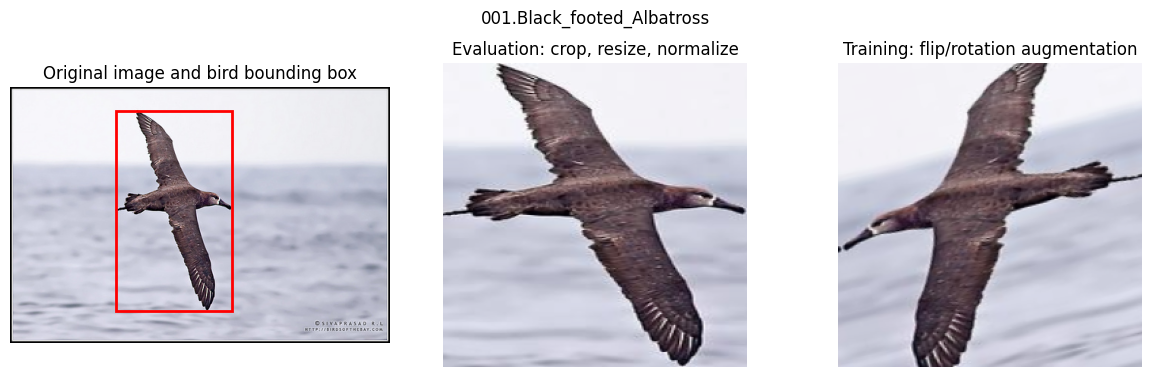

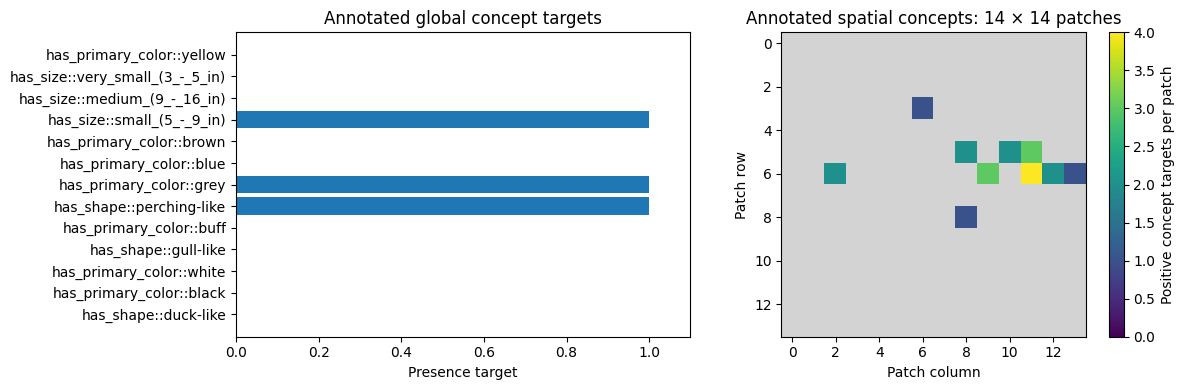

In [10]:
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def display_rgb(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    return np.clip(tensor.permute(1, 2, 0).numpy() * std + mean, 0, 1)

sample_meta = prepared_train.data.iloc[0]
source_path = DATASET_DIR / "images" / sample_meta.filepath
with Image.open(source_path) as image:
    source_rgb = image.convert("RGB").copy()
old_transform = prepared_train.transform
random_state, numpy_state = random.getstate(), np.random.get_state()
try:
    random.seed(42)
    np.random.seed(42)
    prepared_train.transform = module.train_transform
    augmented_image, _, _, _ = prepared_train[0]
finally:
    prepared_train.transform = old_transform
    random.setstate(random_state)
    np.random.set_state(numpy_state)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].imshow(source_rgb)
axes[0].add_patch(Rectangle((sample_meta.x1, sample_meta.y1),
    sample_meta.x2 - sample_meta.x1, sample_meta.y2 - sample_meta.y1,
    fill=False, edgecolor="red", linewidth=2))
axes[0].set_title("Original image and bird bounding box")
axes[1].imshow(display_rgb(sample_image))
axes[1].set_title("Evaluation: crop, resize, normalize")
axes[2].imshow(display_rgb(augmented_image))
axes[2].set_title("Training: flip/rotation augmentation")
for ax in axes:
    ax.axis("off")
fig.suptitle(prepared_train.class_names[int(class_target)], fontsize=12)
fig.tight_layout()
plt.show()

attribute_names = pd.read_csv(DATASET_DIR / "attributes.txt", sep=" ", names=["id", "definition"]).set_index("id").definition
global_names = [attribute_names.loc[i] for i in prepared_train.non_spatial_attributes_pos]
known_global = np.isfinite(global_concepts.numpy())
known_patches = torch.isfinite(spatial_concepts).any(dim=1).numpy().reshape(14, 14)
positive_per_patch = torch.nan_to_num(spatial_concepts, nan=0.0).sum(dim=1).numpy().reshape(14, 14)
patch_targets = np.ma.masked_where(~known_patches, positive_per_patch)
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("lightgray")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(np.array(global_names)[known_global], global_concepts.numpy()[known_global])
axes[0].set(title="Annotated global concept targets", xlabel="Presence target", xlim=(0, 1.1))
heatmap = axes[1].imshow(patch_targets, cmap=cmap, vmin=0, vmax=max(1, float(positive_per_patch.max())))
axes[1].set(title="Annotated spatial concepts: 14 × 14 patches", xlabel="Patch column", ylabel="Patch row")
fig.colorbar(heatmap, ax=axes[1], label="Positive concept targets per patch")
fig.tight_layout()
plt.show()


In [11]:
from torch.utils.data import DataLoader

demo_loader = DataLoader(prepared_train, batch_size=2, shuffle=False, num_workers=0)
images_batch, global_batch, spatial_batch, labels_batch = next(iter(demo_loader))
assert tuple(images_batch.shape) == (2, 3, 224, 224)
assert tuple(global_batch.shape) == (2, 13)
assert tuple(spatial_batch.shape) == (2, 196, 95)
assert tuple(labels_batch.shape) == (2,) and labels_batch.dtype == torch.int64
assert torch.isfinite(images_batch).all() and ((labels_batch >= 0) & (labels_batch < 200)).all()
display(pd.DataFrame([
    {"Model input": name, "Shape": tuple(value.shape), "Dtype": str(value.dtype),
     "Known entries": int(torch.isfinite(value).sum())}
    for name, value in [("images", images_batch), ("global concept targets", global_batch),
                        ("spatial concept targets", spatial_batch), ("class labels", labels_batch)]
]).set_index("Model input"))
print("Real two-image batch passed. NaN concept entries mark unavailable supervision.")


,Shape,Dtype,Known entries
Model input,,,
images,"(2, 3, 224, 224)",torch.float32,301056
global concept targets,"(2, 13)",torch.float32,26
spatial concept targets,"(2, 196, 95)",torch.float32,1710
class labels,"(2,)",torch.int64,2


Real two-image batch passed. NaN concept entries mark unavailable supervision.


### 3.5 Split and model-download considerations

The source data has 5,994 official training images and 5,794 official test images. In the **completed repository-protocol job `45387524`**, the original data module sampled **1,000 validation images from the official test split**, then used the **entire official test split** for final testing. Training and validation shared zero image IDs; validation and final test overlapped. The recorded 87.33% test accuracy belongs to that protocol.

#### Completed second baseline: proportional, non-overlapping sets

**Job `45478721` completed all 50 epochs and final testing on one L4 in `hpg-turin`, with exit code `0:0`.** It ran on October 10, 2026 from 19:18:40 to 21:00:37 EDT, taking **1:41:57** and achieving **86.29% test accuracy** from the minimum-validation-CE checkpoint at **epoch 28**. The user requested the same relative train/validation/test proportions with no overlap. The old counts **5,994:1,000:5,794** add up to 12,788 because validation images were counted again in testing. Normalize this ratio over the **11,788 unique images**, using largest-remainder integer rounding:

| Set | Relative proportion | Images | Source and role |
| --- | ---: | ---: | --- |
| Training | 46.87% | **5,525** | Official training pool after reserving 469 images; gradient updates |
| Validation | 7.82% | **922** | 469 reserved official training images + 453 reserved official test images; checkpoint selection |
| Final test | 45.31% | **5,341** | Official test pool after reserving those 453 validation images; final evaluation |

This preserves the relative proportions to integer rounding. Gradient training uses only official training images, and final testing uses only official test images. Validation uses evaluation transforms for both source pools. Images assigned to validation are excluded from training and final testing. All 200 classes occur in every set, and the actual dataloaders have **zero train–validation, train–test, and validation–test image-ID intersections**.

The partition was generated once with independent split seed **42**, stratifying the reserved images by class. The exact image IDs and source metadata hashes are saved in `split_manifest.json` under the experiment bundle, with SHA-256 `8e7894dc5f436196eb7edfd4d9e3bfd48020ab60fdf1404a3d0e4c510d5011aa`. Reuse this manifest across experiments and training seeds; do not regenerate a split during `setup()`. All 11,788 image IDs are covered exactly once. The verified actual loaders contain **172 training / 29 validation / 167 test batches** at batch size 32, retaining the original training `drop_last=True` behavior.

The completed second baseline retained the **current hyperparameters and runtime** and minimum `val_ce_loss` checkpoint selection: 50 epochs, batch size 32, learning rate `5e-5`, weight decay `1e-3`, warmup 10 epochs, explanation weight 1.0, sparsity weight 0.5, training seed 42, two loader workers, and native FP16 AMP on CUDA. The isolated split adapter uses the repository's dataset, preprocessing, and augmentation; the model, losses, optimizer, and schedule are unchanged. The selected checkpoint was tested once after fitting. Later hyperparameter searches should compare candidates using validation alone and suppress automatic per-trial testing.

The new result uses fewer training and test images and different validation membership. Section 5.3 compares the actual metrics and workload for both completed runs. A difference from **87.33%** cannot be attributed solely to removing overlap. The prior run already evaluated the full official test pool; this new run has disjoint sets, but its test images are not a previously unseen benchmark for this project. Record that history and keep test scores out of subsequent selection decisions.

Training requests pretrained `vit_large_patch16_224` weights through `timm`; the prepared checkpoint is cached in `.cache/torch/hub/checkpoints/` via `TORCH_HOME`. Model weights are separate from the CUB dataset. The job was submitted externally with `sbatch`; notebook cells inspect saved records and results.


## 4. Training Run

### 4.1 CPU debug training/evaluation

`scripts/run_debug.py` invokes the repository's full ViT-Large model with `--debug --batch_size 2 --num_workers 0`. Lightning `fast_dev_run=True` executes one training batch with backward propagation and an optimizer step, one validation batch, and one test batch. This is a pipeline check rather than a dataset performance estimate.

```bash
OMP_NUM_THREADS=4 MKL_NUM_THREADS=4 OPENBLAS_NUM_THREADS=4 \
  .venv/bin/python scripts/run_debug.py
```

The runner records the exact command, current platform, repository revision, entry-point/runtime/lock hashes, elapsed time, raw log, and test metrics under `training_runs/debug/`. The pretrained checkpoint is cached under `.cache/torch/`. Repository model and optimization defaults are retained.

### 4.2 Runtime and debug compatibility

The Lightning 1.9 trainer uses supported accelerator/device and callback arguments. Regular CUDA training uses native FP16 AMP. Debug verification uses CPU FP32. TorchMetrics accuracy receives the explicit multiclass task and class count. These source changes are captured in `patches/hpg-runtime.patch`.

Batch size 2 avoids the upstream spatial-loss `.squeeze()` mask error at batch size 1. Evaluation explicitly passes the data module for Lightning 1.9. Debug mode uses the in-memory model; regular training reloads the best checkpoint:

```python
test_results = trainer.test(
    model=model, datamodule=trainer.datamodule,
    ckpt_path=None if args.debug else "best",
)
```

### 4.3 Execute or inspect the current recorded run

The next cell displays a successful recorded CPU debug run after checking its repository, entry-point, runtime, and lock hashes. It uses the local record when available, or the embedded presentation record otherwise. It does not automatically launch training. Set `RERUN_DEBUG=True` in Section 2.1 to perform a fresh one-batch demonstration; prepare the pretrained weights first.

### Attribution of the earlier issues

| Issue | Origin | Resolution |
| --- | --- | --- |
| Batch size 1 raises a spatial-loss mask `IndexError`. | **Original repository loss code**: the unrestricted `.squeeze()` in `ctc/ctc.py::spatial_concepts_cost` removes the batch dimension. | Use batch size 2 for debug checks and 32 for regular training; the original loss implementation is retained. |
| Debug evaluation calls `trainer.test()` without an available checkpoint. | **Original final test-call pattern exercised with the updated runtime**: `fast_dev_run` disables checkpoint saving. The encountered evaluation path requested an unavailable checkpoint after train/validation. This does not establish the same failure under the original pinned Lightning version. | Debug testing uses the in-memory model with `ckpt_path=None`. |
| Lightning 1.9 testing requires the data module explicitly. | **Local runtime upgrade compatibility**, rather than a defect demonstrated under the repository's original pinned Lightning version. | Supply the model and data module explicitly; regular testing selects the best checkpoint. |

The regular Slurm job failures below have different origins: both occurred in locally added runner code.


In [12]:
import shlex

DEBUG_DIR = PROJECT_DIR / "training_runs" / "debug"
DEBUG_RECORD = DEBUG_DIR / "run.json"
runtime_hash = hashlib.sha256((REPO_DIR / "ctc/ctc_model.py").read_bytes()).hexdigest()
lock_hash = hashlib.sha256((PROJECT_DIR / "uv.lock").read_bytes()).hexdigest()
entry_hash = hashlib.sha256((REPO_DIR / "cvit_cub.py").read_bytes()).hexdigest()
if RERUN_DEBUG:
    weight_dir = PROJECT_DIR / ".cache/torch/hub/checkpoints"
    assert any(weight_dir.glob("*.npz")), "Prepare the pretrained ViT weights before the live debug run."
    print("Running the full model for one train/validation/test batch on CPU; allow roughly a minute.")
    subprocess.run([sys.executable, str(PROJECT_DIR / "scripts/run_debug.py")], cwd=str(PROJECT_DIR), check=True)
debug_record = (json.loads(DEBUG_RECORD.read_text()) if DEBUG_RECORD.exists()
                else NOTEBOOK_DOC["metadata"]["presentation_debug_evidence"])
assert debug_record["success"] and debug_record["returncode"] == 0
assert debug_record["repository_commit"] == repo_commit
for name, expected in [("entrypoint_sha256", entry_hash), ("runtime_sha256", runtime_hash), ("lock_sha256", lock_hash)]:
    assert debug_record[name] == expected, "Saved debug evidence differs from source/environment; prepare a fresh run."
print("Recorded command:", shlex.join(debug_record["command"]))
print("Recorded host:", debug_record["hostname"], "| Python:", debug_record["python"])
print("Completed (UTC):", debug_record["finished_at_utc"])
print("Mode:", debug_record["mode"])
print(f"Elapsed: {debug_record['elapsed_seconds']:.2f} seconds (includes model loading)")
values = pd.Series(debug_record["test_metrics"], name="Two-image pipeline check")
assert np.isfinite(values.to_numpy()).all()
display(values.to_frame())
record["cub_debug_training_verified"] = True
completed_run = NOTEBOOK_DOC["metadata"]["completed_l4_training"]["run"]
record["full_cub_training_verified"] = (
    completed_run["status"] == "complete" and completed_run["repository_commit"] == repo_commit
    and completed_run["entrypoint_sha256"] == entry_hash)
record["cub_training_verified"] = True
if WRITE_AUDIT_FILES:
    (PROJECT_DIR / "setup_logs/environment.json").write_text(json.dumps(record, indent=2) + "\n")
print("Source and environment hashes match. Completed L4 results follow in Section 5.1.")


Recorded command: /orange/yonghui.wu/zhangm3/2026/concept_transformer_explain/.venv/bin/python /orange/yonghui.wu/zhangm3/2026/concept_transformer_explain/concept_transformer/cvit_cub.py --data_dir /orange/yonghui.wu/zhangm3/2026/concept_transformer_explain/CUB-200-2011/CUB_200_2011 --debug --batch_size 2 --num_workers 0
Recorded host: c0700a-s9.ufhpc | Python: 3.8.20
Completed (UTC): 2026-10-09T23:58:28.713150+00:00
Mode: repository --debug (fast_dev_run), Lightning 1.9 CPU trainer and in-memory testing
Elapsed: 63.14 seconds (includes model loading)


,Two-image pipeline check
test_acc,0.000000
test_ce_loss,5.283626
test_expl_loss,1.352253
test_l1_loss,0.245224


Source and environment hashes match. Completed L4 results follow in Section 5.1.


### 4.4 What the debug run establishes

Successful execution checks the original model and loss pipeline on CPU, including backward propagation, one optimizer update, validation, and testing in the selected Linux runtime. The two-image test metrics above are **not estimates of dataset accuracy**.

Debug mode disables normal TensorBoard logging and checkpoint saving. The completed L4 training and final evaluation are recorded in Section 5.1. Matching the paper's benchmark metrics remains a separate assessment. Audit files: [run log](training_runs/debug/run.log), [run metadata](training_runs/debug/run.json), and [source changes](training_runs/debug/code.diff).

### 4.5 L4 training through Slurm

`scripts/train_l4.sbatch` requests **one L4 GPU on `hpg-turin`**, one task, four CPUs, 32 GiB host memory, and a 24-hour walltime using account/QOS `yonghui.wu`. It checks CUDA mixed precision before launching 50 epochs with batch size 32 and two data-loader workers. The job fails instead of silently training on CPU when CUDA is unavailable. Slurm GPU visibility is preserved.

Use a working copy on **Blue** for training I/O, following [HPG computation guidance](https://docs.rc.ufl.edu/quickstart/computation/). The current Orange checkout holds setup and verification artifacts. Prepare the Blue copy and recreate its venv at its own path:

```bash
SOURCE=/orange/yonghui.wu/zhangm3/2026/concept_transformer_explain
WORK=/blue/yonghui.wu/zhangm3/concept_transformer_explain
mkdir -p "$WORK"
rsync -a --exclude=.venv --exclude=.uv-cache --exclude=.uv-python \
  --exclude=.git --exclude=.cache/downloads --exclude=training_runs \
  "$SOURCE/" "$WORK/"
cd "$WORK"
export UV_PYTHON_INSTALL_DIR="$PWD/.uv-python"
export UV_CACHE_DIR="$PWD/.uv-cache"
uv python install 3.8.20
uv venv --python 3.8.20 .venv
uv sync --locked --python .venv/bin/python
mkdir -p training_runs
sbatch --test-only scripts/train_l4.sbatch   # validate without submitting
sbatch scripts/train_l4.sbatch             # actual submission when requested
```

The copy includes the prepared CUB data and cached model weights. `training_runs/` must exist before submission so Slurm can open its logs. The venv is recreated rather than copied because its interpreter paths are absolute. Run installs in an allocated CPU session where `uv` is available.

After submission, use `squeue -u zhangm3` and inspect `training_runs/slurm-<job-id>.out` / `.err`. Each run records Slurm metadata, batch timings, checkpoints, and TensorBoard files under `training_runs/l4-<job-id>/`. The 24-hour limit is an initial request, not a measured completion estimate. Job **45387524 completed successfully** from `/blue/yonghui.wu/zhangm3/concept_transformer_explain`; use `sacct -j 45387524 --format=JobID,State,Elapsed,End,ExitCode` to verify its final state. Initial attempts 45377754 and 45387301 failed before training because of timing-hook and source-hash metadata compatibility errors. Both are fixed and the actual runner has passed a small-model end-to-end check. The completed training and final evaluation are shown in Section 5.1; older committed CPU run records are historical artifacts.

The actual submission used `sbatch --parsable scripts/train_l4.sbatch`. Blue environment package consistency, staged source images/crops, cached weights, and source-file equality were checked first. Slurm briefly delayed acceptance and retried; the request was accepted.


The timing callback hooks accept an optional `dataloader_idx` for Lightning 1.9. Runner hashes use absolute paths after changing into the run directory. Recovery checks are recorded in `setup_logs/timing-callback-check.json`; failed attempts remain under their individual Slurm/run paths. Hyperparameters are unchanged.


Final verified status: job **45387524 is COMPLETED**, with exit code **0:0**, **50 complete epochs**, and **9,350 training batches**. Slurm records start `2026-10-09 21:29:31 EDT`, end `2026-10-09 23:19:35 EDT`, and elapsed `01:50:04`. The early time estimate has been superseded by this measured duration. Final testing loaded the checkpoint selected by minimum validation classification loss.


### Attribution of the failed Slurm attempts

| Job | Failure | Origin | Fix and verification |
| --- | --- | --- | --- |
| `45377754` | `TypeError: on_train_batch_start() missing ... dataloader_idx`; no training batch completed. | **Locally added timing callback in `scripts/run_training.py`**, not the original repository model, loss, or optimizer code. The callback required an argument that Lightning 1.9 does not pass to train hooks. | Make `dataloader_idx` optional in the callback hooks. Exercise training, sanity validation, validation, and testing through Lightning. |
| `45387301` | `FileNotFoundError: scripts/run_training.py` while recording the runner hash; training had not begun. | **Locally added metadata code in `scripts/run_training.py`**, not upstream code. Python 3.8 supplied a relative `__file__`, which was read after changing into the run directory. | Read the runner using its absolute project path. Test the actual runner's initialization, metadata writing, training, validation, testing, and timing output with a small CPU model. |

Both corrections preserve the submitted hyperparameters. Recovery job `45387524` subsequently completed all 50 epochs and final testing, with finite training losses. The check record is `setup_logs/timing-callback-check.json`; individual failed-job logs are retained in the Blue working copy. These two Slurm failures should **not be attributed to the original repository**.


In [13]:
batch_script = PROJECT_DIR / "scripts/train_l4.sbatch"
subprocess.run(["bash", "-n", str(batch_script)], check=True)
print(batch_script.read_text())
print("Batch-script syntax passed. This cell does not submit a job.")
saved_run = json.loads((PROJECT_DIR / "concept_transformer_walkthrough.ipynb").read_text())["metadata"]["completed_l4_training"]
scheduler = saved_run["snapshot"]["scheduler"]
print("Recorded final job status:", scheduler["JobID"], scheduler["State"], "| Exit code:", scheduler["ExitCode"])
print("Elapsed:", scheduler["Elapsed"], "| End (EDT):", scheduler["End"])
print("Training working directory:", saved_run["snapshot"]["source_run"])
print("Verify with: sacct -j", scheduler["JobID"], "--format=JobID,State,Elapsed,End,ExitCode")


#!/bin/bash
#SBATCH --job-name=concept-cub-l4
#SBATCH --account=yonghui.wu
#SBATCH --qos=yonghui.wu
#SBATCH --partition=hpg-turin
#SBATCH --gres=gpu:l4:1
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=4
#SBATCH --mem=32G
#SBATCH --time=24:00:00
#SBATCH --output=training_runs/slurm-%j.out
#SBATCH --error=training_runs/slurm-%j.err
#SBATCH --export=NONE

set -euo pipefail
cd "${SLURM_SUBMIT_DIR:?Submit from the prepared project on Blue}"
case "$PWD" in
    /blue/*) ;;
    *) echo "Submit from the project working copy on /blue." >&2; exit 1 ;;
esac
unset PYTHONHOME PYTHONPATH
export PATH=/opt/slurm/bin:/usr/bin:/bin
export SLURM_EXPORT_ENV=ALL
export OMP_NUM_THREADS="$SLURM_CPUS_PER_TASK"
export MKL_NUM_THREADS="$SLURM_CPUS_PER_TASK"
export OPENBLAS_NUM_THREADS="$SLURM_CPUS_PER_TASK"
export PYTHONUNBUFFERED=1
export TORCH_HOME="$PWD/.cache/torch"
export MPLCONFIGDIR="$PWD/.cache/matplotlib"
PYTHON="$PWD/.venv/bin/python"
test -x "$PYTHON"
# The wheel bundles CUDA 11.8; no CU

## 5. Results & Visualization

This section presents the final validation/test metrics, learning curves, and concept-based explanations from the two completed runs. **5.1** records the first repository-protocol run, **5.2** reports the disjoint baseline, **5.3** compares their results and workload, and **5.4** explains three correct and three incorrect test predictions. Section 6 discusses the existing hypotheses for future improvements.


### 5.1 Completed L4 training: logs and metrics

The following results cover the complete run, using the repository's CUB defaults: **AdamW**, learning rate **5e-5**, weight decay **1e-3**, **50 epochs**, **10 warmup epochs** followed by cosine decay, batch size **32**, seed **42**, explanation weight **1.0**, and attention sparsity weight **0.5**. Two loader workers fit the four-CPU allocation; training used native FP16 mixed precision.

Epoch metrics come from the saved **TensorBoard scalar events**. Batch losses, learning rates, and timing come from `run_training.py`. The checked values and source hashes are embedded in this notebook's metadata, so the saved tables and plots remain available without copying the checkpoint or requiring a GPU. Set `REFRESH_FROM_LOGS=True` to reread the completed run from `GPU_RUN_DIR` on the cluster. This only reads logs.

The training loader drops its last incomplete batch: **187 × 32 = 5,984 images per epoch** from the 5,994-image training set. There are 32 validation batches per epoch and 182 final test batches. The checkpoint is selected by **minimum validation classification loss**, at **epoch 30** (one-based), rather than by maximum validation accuracy.


In [14]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REFRESH_FROM_LOGS = False
GPU_RUN_DIR = Path("/blue/yonghui.wu/zhangm3/concept_transformer_explain/training_runs/l4-45387524")
NOTEBOOK_PATH = PROJECT_DIR / "concept_transformer_walkthrough.ipynb"
evidence = json.loads(NOTEBOOK_PATH.read_text())["metadata"]["completed_l4_training"]
snapshot = evidence["snapshot"]
gpu_run = evidence["run"]
epochs = pd.DataFrame(evidence["epochs"]).set_index("epoch").sort_index()
test_metrics = dict(snapshot["test_metrics"])
best_epoch = int(snapshot["best_validation_epoch"])

if REFRESH_FROM_LOGS:
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
    gpu_run = json.loads((GPU_RUN_DIR / "run.json").read_text())
    assert gpu_run["status"] == "complete", "The selected run must be complete."
    for filename, expected in evidence["tensorboard_sha256"].items():
        event_path = GPU_RUN_DIR / "logs/version_0" / Path(filename).name
        assert hashlib.sha256(event_path.read_bytes()).hexdigest() == expected
    event_log = EventAccumulator(str(GPU_RUN_DIR / "logs/version_0"), size_guidance={"scalars": 0})
    event_log.Reload()
    scalars = pd.DataFrame([
        {"tag": tag, "step": point.step, "value": point.value}
        for tag in event_log.Tags()["scalars"] for point in event_log.Scalars(tag)
    ])
    step_epochs = scalars[scalars.tag == "epoch"].drop_duplicates("step").set_index("step").value
    curves = scalars[scalars.tag.str.startswith(("train_", "val_"))].copy()
    curves["epoch"] = curves.step.map(step_epochs).astype(int) + 1
    live_epochs = curves.pivot(index="epoch", columns="tag", values="value").sort_index()
    np.testing.assert_allclose(live_epochs, epochs[live_epochs.columns], rtol=1e-7)
    for tag in ["test_acc", "test_ce_loss", "test_expl_loss", "test_l1_loss"]:
        value = float(scalars.loc[scalars.tag == tag, "value"].iloc[-1])
        np.testing.assert_allclose(value, test_metrics[tag], rtol=1e-7)
    print("Refreshed TensorBoard values match the embedded final evidence.")

assert gpu_run["status"] == "complete"
assert snapshot["scheduler"]["State"] == "COMPLETED"
assert snapshot["scheduler"]["ExitCode"] == "0:0"
assert list(epochs.index) == list(range(1, 51))
assert len(epochs) == gpu_run["max_epochs"] == snapshot["complete_epochs"]
assert snapshot["train_batches"] == 50 * 187 == 9350
assert (epochs.train_batches == 187).all()
assert np.isfinite(epochs.to_numpy()).all() and np.isfinite(list(test_metrics.values())).all()
expl_weight = snapshot["objective_weights"]["explanation"]
sparse_weight = snapshot["objective_weights"]["sparsity"]
np.testing.assert_allclose(epochs.train_loss,
    epochs.train_ce_loss + expl_weight * epochs.train_expl_loss + sparse_weight * epochs.train_l1_loss,
    rtol=1e-5, atol=1e-6)
assert best_epoch == int(epochs.val_ce_loss.idxmin())

summary = pd.Series({
    "Job": snapshot["job_id"], "Partition / GPU": "hpg-turin / NVIDIA L4",
    "Slurm state / exit": "COMPLETED / 0:0", "Complete epochs": len(epochs),
    "Training batches": snapshot["train_batches"],
    "Slurm elapsed": snapshot["scheduler"]["Elapsed"],
    "Finished (EDT)": snapshot["scheduler"]["End"],
    "Selected checkpoint epoch": best_epoch,
    "Final test accuracy": f"{100 * test_metrics['test_acc']:.2f}%",
}, name="Completed run")
display(summary.to_frame())
print("Recorded repository command:", " ".join(gpu_run["command"]))
print("Evidence captured (UTC):", snapshot["captured_at_utc"])


,Completed run
Job,45387524
Partition / GPU,hpg-turin / NVIDIA L4
Slurm state / exit,COMPLETED / 0:0
Complete epochs,50
Training batches,9350
Slurm elapsed,01:50:04
Finished (EDT),2026-10-09T23:19:35
Selected checkpoint epoch,30
Final test accuracy,87.33%


Recorded repository command: /blue/yonghui.wu/zhangm3/concept_transformer_explain/.venv/bin/python /blue/yonghui.wu/zhangm3/concept_transformer_explain/concept_transformer/cvit_cub.py --data_dir /blue/yonghui.wu/zhangm3/concept_transformer_explain/CUB-200-2011/CUB_200_2011 --batch_size 32 --num_workers 2 --max_epochs 50
Evidence captured (UTC): 2026-10-10T03:47:27.163541+00:00


#### Training and validation curves

The plots use unsmoothed per-epoch metrics. The total training objective is `CE + 1.0 × explanation + 0.5 × sparsity`. Validation total loss was **not logged directly**; it is calculated from the logged validation components using the same weights. The explanation loss combines global and spatial concept supervision. The sparsity panel shows the **unweighted** penalty. Learning rates are mean observed optimizer learning rates within each epoch, including linear warmup and cosine decay. Vertical dotted lines mark the selected checkpoint epoch.


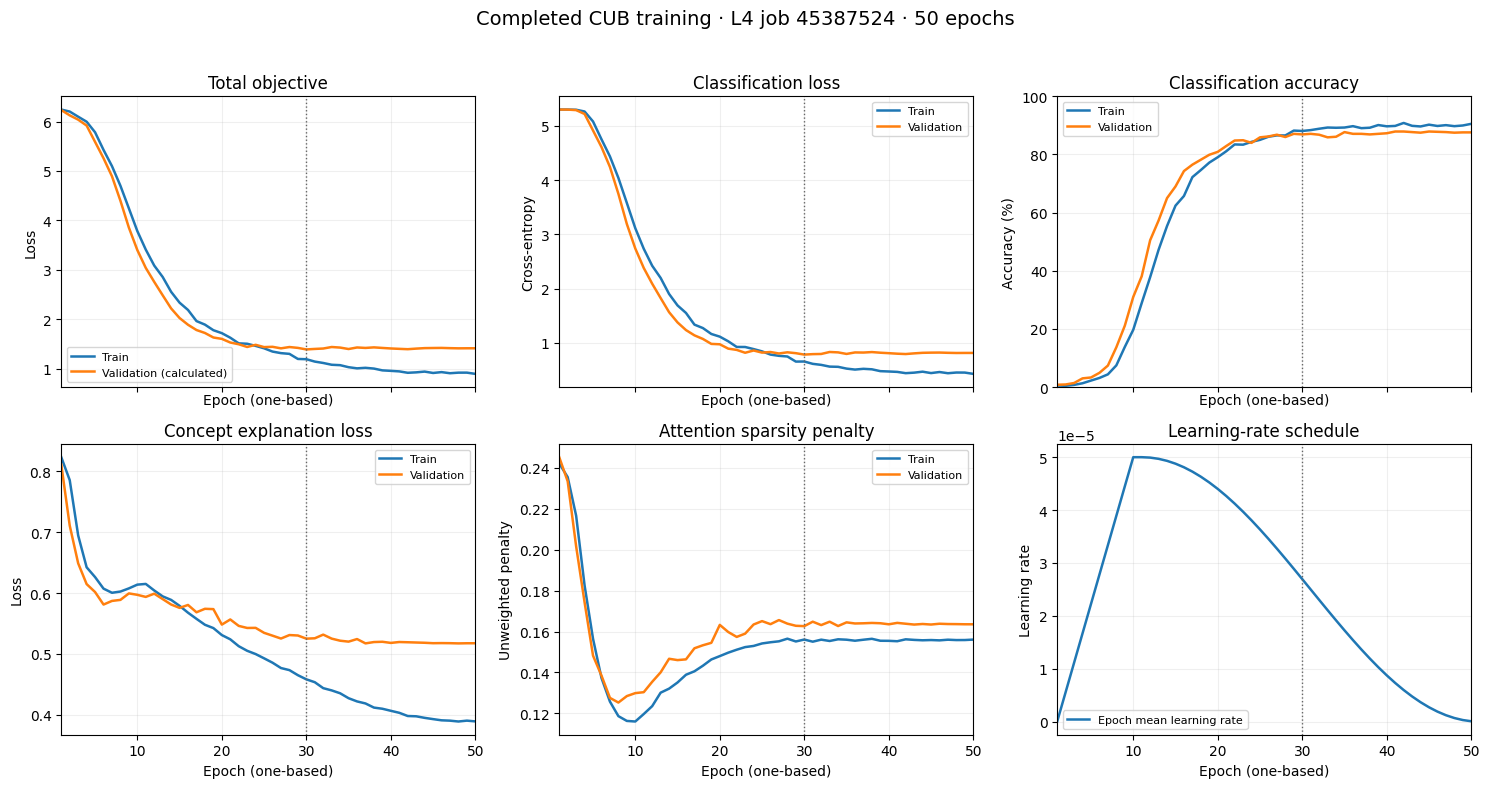

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
panels = [
    (axes[0, 0], "Total objective", [("train_loss", "Train"), ("val_total_loss_derived", "Validation (calculated)")], "Loss", 1),
    (axes[0, 1], "Classification loss", [("train_ce_loss", "Train"), ("val_ce_loss", "Validation")], "Cross-entropy", 1),
    (axes[0, 2], "Classification accuracy", [("train_acc", "Train"), ("val_acc", "Validation")], "Accuracy (%)", 100),
    (axes[1, 0], "Concept explanation loss", [("train_expl_loss", "Train"), ("val_expl_loss", "Validation")], "Loss", 1),
    (axes[1, 1], "Attention sparsity penalty", [("train_l1_loss", "Train"), ("val_l1_loss", "Validation")], "Unweighted penalty", 1),
    (axes[1, 2], "Learning-rate schedule", [("learning_rate", "Epoch mean learning rate")], "Learning rate", 1),
]
for ax, title, series, ylabel, scale in panels:
    for column, label in series:
        ax.plot(epochs.index, epochs[column] * scale, linewidth=1.8, label=label)
    ax.axvline(best_epoch, color="0.4", linestyle=":", linewidth=1)
    ax.set(title=title, xlabel="Epoch (one-based)", ylabel=ylabel, xlim=(1, 50))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
axes[0, 2].set_ylim(0, 100)
axes[1, 2].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
fig.suptitle("Completed CUB training · L4 job 45387524 · 50 epochs", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()


#### Final metrics and checkpoint selection

The table distinguishes the **last training/validation epoch** from the **validation epoch used to select the checkpoint**. The final test values come from evaluating that selected checkpoint on all **5,794 official test images**. Test accuracy is **87.33%**; validation accuracy at checkpoint selection is **86.90%**. Checkpoint selection minimizes classification loss, so the selected epoch need not have the highest validation accuracy.

Validation does **not** backpropagate or update the model weights; gradient updates use training batches. It still affects which weights are evaluated because the lowest-validation-CE checkpoint is selected. Reusing those validation images in final testing can introduce model-selection bias. The measured accuracy is correct for this dataset and checkpoint, but the size of any optimism is unknown; the overlap percentage is not an estimate of accuracy inflation.

**Interpretation:** the repository samples its 1,000 validation images from the official test split, then tests on the full official test split. The final test therefore overlaps checkpoint-selection data; it is not an independent holdout estimate. These results describe this repository configuration and runtime, and do not establish reproduction of the paper's benchmark.


,Epoch / checkpoint,Accuracy (%),Classification loss,Explanation loss,Sparsity penalty (unweighted),Total objective
"Train, final epoch",50,90.5414,0.4302,0.3893,0.1561,0.8975
"Validation, final epoch",50,87.6000,0.8158,0.5176,0.1636,1.4151
"Validation, selected checkpoint",30,86.9000,0.7853,0.5251,0.1627,1.3917
"Test, selected checkpoint",30,87.3317,0.7376,0.5344,0.1626,1.3533


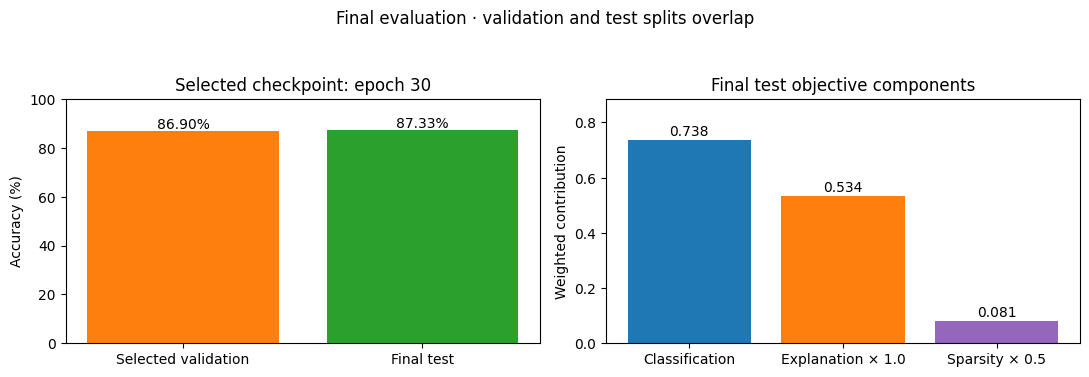

In [16]:
def metric_row(row, prefix, epoch_label):
    return {
        "Epoch / checkpoint": epoch_label, "Accuracy (%)": 100 * row[prefix + "_acc"],
        "Classification loss": row[prefix + "_ce_loss"],
        "Explanation loss": row[prefix + "_expl_loss"],
        "Sparsity penalty (unweighted)": row[prefix + "_l1_loss"],
        "Total objective": (row[prefix + "_ce_loss"] + expl_weight * row[prefix + "_expl_loss"]
                            + sparse_weight * row[prefix + "_l1_loss"]),
    }

final_metrics = pd.DataFrame({
    "Train, final epoch": metric_row(epochs.loc[50], "train", "50"),
    "Validation, final epoch": metric_row(epochs.loc[50], "val", "50"),
    "Validation, selected checkpoint": metric_row(epochs.loc[best_epoch], "val", str(best_epoch)),
    "Test, selected checkpoint": metric_row(test_metrics, "test", str(best_epoch)),
}).T
display(final_metrics.style.format({column: "{:.4f}" for column in final_metrics.columns if column != "Epoch / checkpoint"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bars = axes[0].bar(["Selected validation", "Final test"],
    [100 * epochs.loc[best_epoch, "val_acc"], 100 * test_metrics["test_acc"]],
    color=["tab:orange", "tab:green"])
axes[0].set(title=f"Selected checkpoint: epoch {best_epoch}", ylabel="Accuracy (%)", ylim=(0, 100))
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
                 f"{bar.get_height():.2f}%", ha="center")
loss_values = [test_metrics["test_ce_loss"], expl_weight * test_metrics["test_expl_loss"],
               sparse_weight * test_metrics["test_l1_loss"]]
bars = axes[1].bar(["Classification", "Explanation × 1.0", "Sparsity × 0.5"], loss_values,
                  color=["tab:blue", "tab:orange", "tab:purple"])
axes[1].set(title="Final test objective components", ylabel="Weighted contribution")
for bar in bars:
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
                 f"{bar.get_height():.3f}", ha="center")
axes[1].set_ylim(0, max(loss_values) * 1.2)
fig.suptitle("Final evaluation · validation and test splits overlap", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()


#### Timing and completion logs

These batch timings describe the observed run. Batch wall time includes work between consecutive training batches; compute time covers the timing callback's batch-start to batch-end interval. They do not include validation or checkpoint writes. The full Slurm elapsed time above includes job startup, training, validation, and final testing.

The original logs and TensorBoard event files remain under the Blue run directory. The following excerpts and source hashes are stored in this notebook. The checkpoint is saved at `cub_cvit/CUB2011Parts_expl1.0/binary_mnist_best_ckpt.ckpt` beneath the run directory. The filename is inherited from the repository; this is the CUB checkpoint.


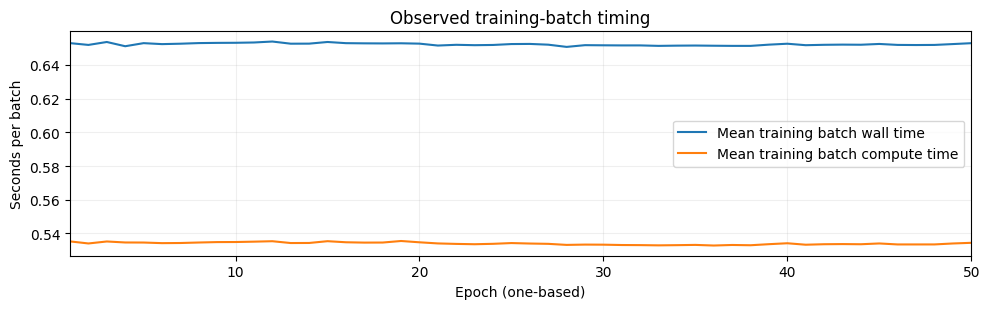

Training and checkpoint completion (stderr excerpt):
`Trainer.fit` stopped: `max_epochs=50` reached.
Restoring states from the checkpoint path at ./cub_cvit/CUB2011Parts_expl1.0/binary_mnist_best_ckpt.ckpt
Loaded model weights from checkpoint at ./cub_cvit/CUB2011Parts_expl1.0/binary_mnist_best_ckpt.ckpt

Final test metrics (stdout excerpt):
Testing DataLoader 0: 100%|██████████| 182/182 [00:30<00:00,  5.89it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_acc            0.8733172416687012
      test_ce_loss          0.7375802397727966
     test_expl_loss          0.534404993057251
      test_l1_loss          0.1625971645116806
──────────────────────────────────────────────────────────────────────────────────────────────────────────────

,SHA-256 of saved source
batch_timings.jsonl,57b4f8875f7164f8289d5ebd1222184e652977d5c9746d...
gpu-run.json,cda1375a4edb469a07427cdd810e852afcdc5cc7c53f4a...
gpu-slurm.err,232aecf136428e16f964aff3bb24d989df3d798975e0ba...
gpu-slurm.out,c98153e5e5d270f7f17fd6f238cf8f058dc70abb52349b...


In [17]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(epochs.index, epochs.mean_batch_wall_seconds, label="Mean training batch wall time")
ax.plot(epochs.index, epochs.mean_batch_compute_seconds, label="Mean training batch compute time")
ax.set(title="Observed training-batch timing", xlabel="Epoch (one-based)", ylabel="Seconds per batch", xlim=(1, 50))
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

print("Training and checkpoint completion (stderr excerpt):")
print(evidence["stderr_completion_excerpt"])
print("\nFinal test metrics (stdout excerpt):")
print(evidence["stdout_excerpt"])
print("\nSaved checkpoint:", snapshot["checkpoint_path"])
print("Raw logs:", GPU_RUN_DIR.parent / "slurm-45387524.out", "and .err")
print("TensorBoard:", GPU_RUN_DIR / "logs/version_0")
display(pd.Series(evidence["source_sha256"], name="SHA-256 of saved source").to_frame())


### 5.2 Completed proportional non-overlapping baseline: job 45478721

The second run **completed 50 training and validation epochs plus final testing**, with Slurm exit code **0:0**, on an L4 in `hpg-turin`. Start: **October 10, 2026, 19:18:40 EDT**; finish: **21:00:37 EDT**; elapsed: **1:41:57**. The allocation used four CPUs, 32 GB host memory, and a four-hour wall limit.

The saved split has **5,525 training / 922 validation / 5,341 test images**, covering every source image once with no shared image IDs. Minimum validation CE selected **epoch 28**. Final testing of that checkpoint produced **86.29% accuracy**, **0.6853 classification CE**, **0.5346 explanation loss**, and **0.1557 unweighted attention concentration penalty**.

Full records are under `/blue/yonghui.wu/zhangm3/concept_transformer_explain/training_runs/disjoint-proportional-seed42-20261010/l4-45478721/`. The job's Slurm logs and split manifest are in its parent bundle. These values and all 50 epoch records have been embedded in the notebook after verification against the completed logs. The following cells run on CPU. Set `REFRESH_COMPARISON_FROM_LOGS=True` to verify the embedded values against both immutable TensorBoard event directories; the default uses the embedded evidence.


In [18]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REFRESH_COMPARISON_FROM_LOGS = False
comparison_notebook_path = Path('/orange/yonghui.wu/zhangm3/2026/concept_transformer_explain/concept_transformer_walkthrough.ipynb')
comparison_evidence = json.loads(comparison_notebook_path.read_text())['metadata']['completed_run_comparison']
comparison_jobs = ['45387524', '45478721']
comparison_labels = {'45387524': 'First: repo protocol', '45478721': 'Second: disjoint'}
comparison_colors = {'45387524': 'tab:blue', '45478721': 'tab:orange'}
comparison_records = comparison_evidence['runs']
comparison_epochs = {
    job: pd.DataFrame(comparison_records[job]['epochs']).set_index('epoch').sort_index()
    for job in comparison_jobs
}
comparison_selected_epochs = {
    job: int(comparison_records[job]['snapshot']['best_validation_epoch'])
    for job in comparison_jobs
}
for comparison_job in comparison_jobs:
    comparison_record = comparison_records[comparison_job]
    comparison_frame = comparison_epochs[comparison_job]
    comparison_snapshot = comparison_record['snapshot']
    assert comparison_record['run']['status'] == 'complete'
    assert comparison_snapshot['scheduler']['State'] == 'COMPLETED'
    assert comparison_snapshot['scheduler']['ExitCode'] == '0:0'
    assert list(comparison_frame.index) == list(range(1, 51))
    assert np.isfinite(comparison_frame.to_numpy()).all()
    assert comparison_selected_epochs[comparison_job] == int(comparison_frame.val_ce_loss.idxmin())
    assert comparison_snapshot['train_batches'] == 50 * comparison_record['run']['train_batches_per_epoch']
    comparison_weights = comparison_snapshot['objective_weights']
    np.testing.assert_allclose(comparison_frame.train_loss,
        comparison_frame.train_ce_loss + comparison_weights['explanation'] * comparison_frame.train_expl_loss
        + comparison_weights['sparsity'] * comparison_frame.train_l1_loss,
        rtol=1e-5, atol=1e-6)
    if REFRESH_COMPARISON_FROM_LOGS:
        from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
        comparison_log_dir = Path(comparison_snapshot['source_run']) / 'logs/version_0'
        for comparison_filename, comparison_expected in comparison_record['tensorboard_sha256'].items():
            assert hashlib.sha256((comparison_log_dir / comparison_filename).read_bytes()).hexdigest() == comparison_expected
        comparison_events = EventAccumulator(str(comparison_log_dir), size_guidance={'scalars': 0})
        comparison_events.Reload()
        comparison_live = pd.DataFrame([
            {'tag': tag, 'step': point.step, 'value': point.value}
            for tag in comparison_events.Tags()['scalars'] for point in comparison_events.Scalars(tag)
        ])
        comparison_step_epochs = comparison_live[comparison_live.tag == 'epoch'].drop_duplicates('step').set_index('step').value
        comparison_live_curves = comparison_live[comparison_live.tag.str.startswith(('train_', 'val_'))].copy()
        comparison_live_curves['epoch'] = comparison_live_curves.step.map(comparison_step_epochs).astype(int) + 1
        comparison_live_frame = comparison_live_curves.pivot(index='epoch', columns='tag', values='value').sort_index()
        np.testing.assert_allclose(comparison_live_frame, comparison_frame[comparison_live_frame.columns], rtol=1e-7)
        for comparison_tag in ['test_acc', 'test_ce_loss', 'test_expl_loss', 'test_l1_loss']:
            comparison_value = float(comparison_live.loc[comparison_live.tag == comparison_tag, 'value'].iloc[-1])
            np.testing.assert_allclose(comparison_value, comparison_snapshot['test_metrics'][comparison_tag], rtol=1e-7)
assert all(comparison_evidence['checks'].values())
disjoint_evidence = comparison_records['45478721']
disjoint_epochs = comparison_epochs['45478721']
disjoint_snapshot = disjoint_evidence['snapshot']
disjoint_best_epoch = comparison_selected_epochs['45478721']
display(pd.Series({
    'Job / state / exit': '45478721 / COMPLETED / 0:0',
    'Train / validation / test images': '5,525 / 922 / 5,341',
    'Complete epochs': 50,
    'Training batches': disjoint_snapshot['train_batches'],
    'Validation / test batches': f"{disjoint_snapshot['phase_counts']['validation']} / {disjoint_snapshot['phase_counts']['test']}",
    'Slurm elapsed': disjoint_snapshot['scheduler']['Elapsed'],
    'Finished (EDT)': disjoint_snapshot['scheduler']['End'],
    'Selected checkpoint epoch': disjoint_best_epoch,
    'Test accuracy': f"{100 * disjoint_snapshot['test_metrics']['test_acc']:.2f}%",
}, name='Completed second run').to_frame())
print('Evidence captured (UTC):', comparison_evidence['captured_at_utc'])
print('Shared hyperparameters and runner/entrypoint hashes were verified equal.')


,Completed second run
Job / state / exit,45478721 / COMPLETED / 0:0
Train / validation / test images,"5,525 / 922 / 5,341"
Complete epochs,50
Training batches,8600
Validation / test batches,1450 / 167
Slurm elapsed,01:41:57
Finished (EDT),2026-10-10T21:00:37
Selected checkpoint epoch,28
Test accuracy,86.29%


Evidence captured (UTC): 2026-10-11T02:21:10.373444+00:00
Shared hyperparameters and runner/entrypoint hashes were verified equal.


#### Full new-run learning curves

These curves use all 50 recorded epochs. The dotted line marks the **selected epoch 28**, not the final epoch. Validation total objective is calculated from the three logged components with the same weights as training. The logged `*_l1_loss` is the repository's entropy-style attention concentration penalty; it is not an L1 norm. Lower explanation loss measures alignment with the supplied concept targets, and does not by itself establish explanation faithfulness.


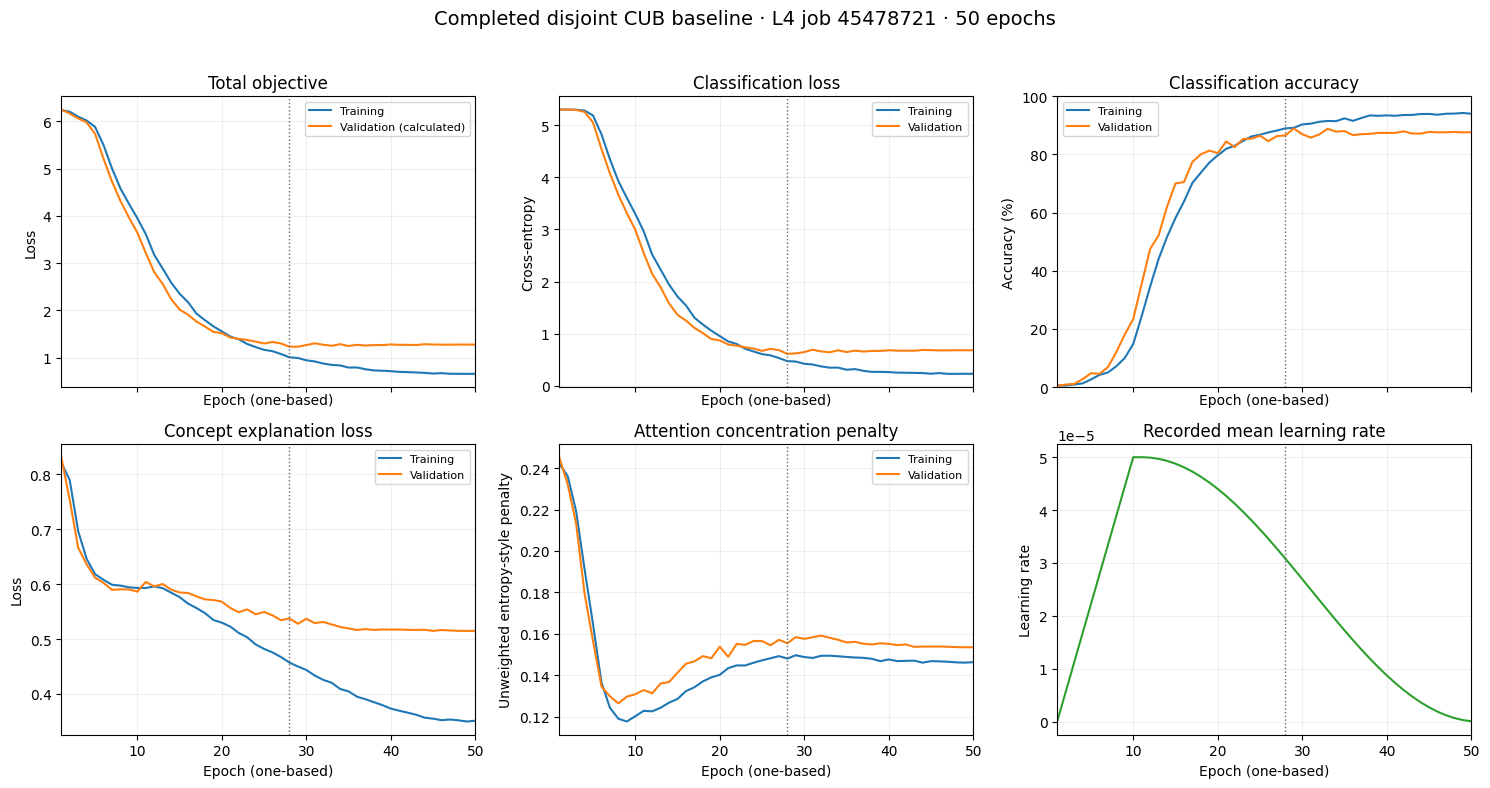

In [19]:
disjoint_figure, disjoint_axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
disjoint_panels = [
    ('Total objective', 'train_loss', 'val_total_loss_derived', 'Loss', 1),
    ('Classification loss', 'train_ce_loss', 'val_ce_loss', 'Cross-entropy', 1),
    ('Classification accuracy', 'train_acc', 'val_acc', 'Accuracy (%)', 100),
    ('Concept explanation loss', 'train_expl_loss', 'val_expl_loss', 'Loss', 1),
    ('Attention concentration penalty', 'train_l1_loss', 'val_l1_loss', 'Unweighted entropy-style penalty', 1),
]
for disjoint_axis, (title, train_tag, val_tag, ylabel, scale) in zip(disjoint_axes.flat, disjoint_panels):
    disjoint_axis.plot(disjoint_epochs.index, disjoint_epochs[train_tag] * scale,
                       color='tab:blue', label='Training')
    disjoint_axis.plot(disjoint_epochs.index, disjoint_epochs[val_tag] * scale,
                       color='tab:orange', label='Validation' + (' (calculated)' if val_tag == 'val_total_loss_derived' else ''))
    disjoint_axis.axvline(disjoint_best_epoch, color='0.4', linestyle=':', linewidth=1)
    disjoint_axis.set(title=title, xlabel='Epoch (one-based)', ylabel=ylabel, xlim=(1, 50))
    disjoint_axis.grid(alpha=0.2)
    disjoint_axis.legend(fontsize=8)
disjoint_axes[0, 2].set_ylim(0, 100)
disjoint_axes[1, 2].plot(disjoint_epochs.index, disjoint_epochs.learning_rate, color='tab:green')
disjoint_axes[1, 2].axvline(disjoint_best_epoch, color='0.4', linestyle=':', linewidth=1)
disjoint_axes[1, 2].set(title='Recorded mean learning rate', xlabel='Epoch (one-based)', ylabel='Learning rate', xlim=(1, 50))
disjoint_axes[1, 2].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
disjoint_axes[1, 2].grid(alpha=0.2)
disjoint_figure.suptitle('Completed disjoint CUB baseline · L4 job 45478721 · 50 epochs', fontsize=14)
disjoint_figure.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()


#### New-run checkpoint and final metrics

The selected checkpoint is **epoch 28**, while training continued through epoch 50. Final test metrics describe the selected checkpoint. Keep selected-checkpoint validation values separate from the final epoch when presenting the result.


In [20]:
disjoint_stage_rows = []
for disjoint_stage, disjoint_epoch, disjoint_prefix in [
    ('Training at selected checkpoint', disjoint_best_epoch, 'train'),
    ('Validation at selected checkpoint', disjoint_best_epoch, 'val'),
    ('Training at final epoch', 50, 'train'),
    ('Validation at final epoch', 50, 'val'),
]:
    disjoint_row = disjoint_epochs.loc[disjoint_epoch]
    disjoint_stage_rows.append({
        'Stage': disjoint_stage, 'Epoch': disjoint_epoch,
        'Accuracy (%)': 100 * disjoint_row[disjoint_prefix + '_acc'],
        'Classification CE': disjoint_row[disjoint_prefix + '_ce_loss'],
        'Explanation loss': disjoint_row[disjoint_prefix + '_expl_loss'],
        'Concentration penalty': disjoint_row[disjoint_prefix + '_l1_loss'],
        'Total objective': disjoint_row[disjoint_prefix + '_ce_loss'] + disjoint_row[disjoint_prefix + '_expl_loss'] + 0.5 * disjoint_row[disjoint_prefix + '_l1_loss'],
    })
disjoint_tests = disjoint_snapshot['test_metrics']
disjoint_stage_rows.append({
    'Stage': 'Test of selected checkpoint', 'Epoch': disjoint_best_epoch,
    'Accuracy (%)': 100 * disjoint_tests['test_acc'],
    'Classification CE': disjoint_tests['test_ce_loss'],
    'Explanation loss': disjoint_tests['test_expl_loss'],
    'Concentration penalty': disjoint_tests['test_l1_loss'],
    'Total objective': disjoint_tests['test_total_loss_derived'],
})
display(pd.DataFrame(disjoint_stage_rows).set_index('Stage').style.format({
    'Epoch': '{:.0f}', 'Accuracy (%)': '{:.2f}', 'Classification CE': '{:.4f}',
    'Explanation loss': '{:.4f}', 'Concentration penalty': '{:.4f}', 'Total objective': '{:.4f}',
}))
print('Checkpoint restoration and completion:')
print(disjoint_evidence['stderr_completion_excerpt'])
print('\nFinal test log:')
print(disjoint_evidence['stdout_excerpt'])
print('\nSaved checkpoint:', disjoint_snapshot['checkpoint_path'])


,Epoch,Accuracy (%),Classification CE,Explanation loss,Concentration penalty,Total objective
Stage,,,,,,
Training at selected checkpoint,28,88.99,0.4741,0.4572,0.1482,1.0054
Validation at selected checkpoint,28,86.55,0.6153,0.5376,0.1555,1.2306
Training at final epoch,50,94.00,0.2319,0.3513,0.1464,0.6565
Validation at final epoch,50,87.64,0.6831,0.5148,0.1536,1.2747
Test of selected checkpoint,28,86.29,0.6853,0.5346,0.1557,1.2978


Checkpoint restoration and completion:
`Trainer.fit` stopped: `max_epochs=50` reached.
Restoring states from the checkpoint path at ./cub_cvit/CUB2011Parts_expl1.0/binary_mnist_best_ckpt.ckpt
Loaded model weights from checkpoint at ./cub_cvit/CUB2011Parts_expl1.0/binary_mnist_best_ckpt.ckpt

Final test log:
Testing DataLoader 0: 100%|██████████| 167/167 [00:28<00:00,  5.85it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_acc            0.8629469871520996
      test_ce_loss          0.6853255033493042
     test_expl_loss         0.5346314311027527
      test_l1_loss          0.15571942925453186
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Saved checkpoint: /blu

### 5.3 What we did after the first training, and how the results compare

After the first completed run, we:

1. Reviewed the full training/validation curves and the minimum-validation-CE checkpoint. The first run selected epoch 30 and tested at 87.33% accuracy.
2. Checked the exact upstream dataset/datamodule revision and our submitted code. Validation did not update weights through gradients, but its 1,000 images were included in the final test set and influenced checkpoint selection.
3. Created and saved a stratified **non-overlapping** partition with split seed 42. To preserve the requested relative ratio **5,994:1,000:5,794**, we normalized it over unique images and rounded to **5,525:922:5,341**. Every image appears in exactly one set; all 200 classes occur in each set. Gradient-training images remain in the official training pool, test images remain in the official test pool, and validation uses reserved images from both.
4. Verified actual loader IDs, crop availability, transforms, and batch shapes. A real CPU smoke check passed training, finite gradients, validation, checkpoint saving/restoration, and testing.
5. Reran all 50 epochs on an L4 with the **same model, pretrained weights, losses, optimizer, hyperparameters, runtime, and checkpoint rule**. We did not tune hyperparameters between runs. The new checkpoint was selected at epoch 28 and tested at 86.29% accuracy.

The tables and plots below are a **descriptive comparison of two evaluation protocols**, not a controlled estimate of the effect of overlap. The training set shrank by 469 images, validation changed in size and membership, and the new 5,341-image test partition is a subset of the original 5,794-image test set. The exact first-run validation IDs were not saved. Also, the prior run already evaluated the official test pool; the new split is disjoint within the new run, but its test images are not previously unseen in this project. These differences prevent attributing the accuracy change solely to removing overlap.

Accuracy differences are shown in **percentage points**. Loss differences use their original units. Validation total objective and test total objective are calculated from CE + 1.0 × explanation loss + 0.5 × concentration penalty. The concentration term is shown unweighted in its own rows. Both runs use training seed 42, so this comparison does not quantify variation across seeds.


In [21]:
def comparison_elapsed_seconds(text):
    pieces = text.split(':')
    return int(pieces[0]) * 3600 + int(pieces[1]) * 60 + int(pieces[2])

comparison_setup_rows = []
for comparison_job in comparison_jobs:
    item = comparison_records[comparison_job]
    snap = item['snapshot']
    sizes = snap['dataset_sizes']
    comparison_setup_rows.append({
        'Run': comparison_labels[comparison_job], 'Job': comparison_job,
        'Train images': sizes['train'], 'Validation images': sizes['validation'], 'Test images': sizes['test'],
        'Validation–test overlap': 1000 if comparison_job == '45387524' else 0,
        'Selected epoch': comparison_selected_epochs[comparison_job],
        'Training batches': snap['train_batches'],
        'Samples per training epoch': snap['train_samples_per_epoch'],
        'Slurm elapsed': snap['scheduler']['Elapsed'],
    })
display(pd.DataFrame(comparison_setup_rows).set_index('Run'))
display(pd.Series(comparison_evidence['shared_hyperparameters'], name='Verified shared settings').to_frame())

comparison_test_specs = [
    ('Test accuracy', '% / delta in percentage points', 'test_acc', 100),
    ('Test classification CE', 'loss', 'test_ce_loss', 1),
    ('Test explanation loss', 'loss', 'test_expl_loss', 1),
    ('Test concentration penalty', 'unweighted penalty', 'test_l1_loss', 1),
    ('Test total objective', 'calculated loss', 'test_total_loss_derived', 1),
]
comparison_test_rows = []
for label, unit, key, scale in comparison_test_specs:
    first = scale * comparison_records['45387524']['snapshot']['test_metrics'][key]
    second = scale * comparison_records['45478721']['snapshot']['test_metrics'][key]
    comparison_test_rows.append({'Metric': label, 'Unit': unit,
        'First: repo protocol': first, 'Second: disjoint': second, 'Second − first': second - first})
comparison_test_table = pd.DataFrame(comparison_test_rows).set_index('Metric')
display(comparison_test_table.style.format({
    'First: repo protocol': '{:.4f}', 'Second: disjoint': '{:.4f}', 'Second − first': '{:+.4f}',
}))

comparison_stage_rows = []
for stage, prefix, use_selected in [
    ('Training at selected checkpoint', 'train', True),
    ('Validation at selected checkpoint', 'val', True),
    ('Training at final epoch', 'train', False),
    ('Validation at final epoch', 'val', False),
]:
    for job in comparison_jobs:
        epoch_number = comparison_selected_epochs[job] if use_selected else 50
        row = comparison_epochs[job].loc[epoch_number]
        comparison_stage_rows.append({
            'Stage': stage, 'Run': comparison_labels[job], 'Epoch': epoch_number,
            'Accuracy (%)': 100 * row[prefix + '_acc'],
            'Classification CE': row[prefix + '_ce_loss'],
            'Explanation loss': row[prefix + '_expl_loss'],
            'Concentration penalty': row[prefix + '_l1_loss'],
            'Total objective': row[prefix + '_ce_loss'] + row[prefix + '_expl_loss'] + 0.5 * row[prefix + '_l1_loss'],
        })
comparison_stage_table = pd.DataFrame(comparison_stage_rows).set_index(['Stage', 'Run'])
display(comparison_stage_table.style.format({
    'Epoch': '{:.0f}', 'Accuracy (%)': '{:.2f}', 'Classification CE': '{:.4f}',
    'Explanation loss': '{:.4f}', 'Concentration penalty': '{:.4f}', 'Total objective': '{:.4f}',
}))


,Job,Train images,Validation images,Test images,Validation–test overlap,Selected epoch,Training batches,Samples per training epoch,Slurm elapsed
Run,,,,,,,,,
First: repo protocol,45387524,5994,1000,5794,1000,30,9350,5984,01:50:04
Second: disjoint,45478721,5525,922,5341,0,28,8600,5504,01:41:57


,Verified shared settings
learning_rate,0.00005
weight_decay,0.001
batch_size,32
warmup,10
max_epochs,50
expl_lambda,1.0
attention_sparsity,0.5
seed,42
num_workers,2
baseline,False


,Unit,First: repo protocol,Second: disjoint,Second − first
Metric,,,,
Test accuracy,% / delta in percentage points,87.3317,86.2947,-1.0370
Test classification CE,loss,0.7376,0.6853,-0.0523
Test explanation loss,loss,0.5344,0.5346,+0.0002
Test concentration penalty,unweighted penalty,0.1626,0.1557,-0.0069
Test total objective,calculated loss,1.3533,1.2978,-0.0555


#### Side-by-side learning curves

**Blue = first run; orange = second run. Solid = validation; dashed = training.** Dots mark each run's validation values at its selected checkpoint. Epochs are one-based. The learning-rate schedule is unchanged, while the number of optimizer steps per epoch differs (187 versus 172). Curves are evaluated on different image memberships, so their gaps and relative heights do not isolate the split change's causal effect.


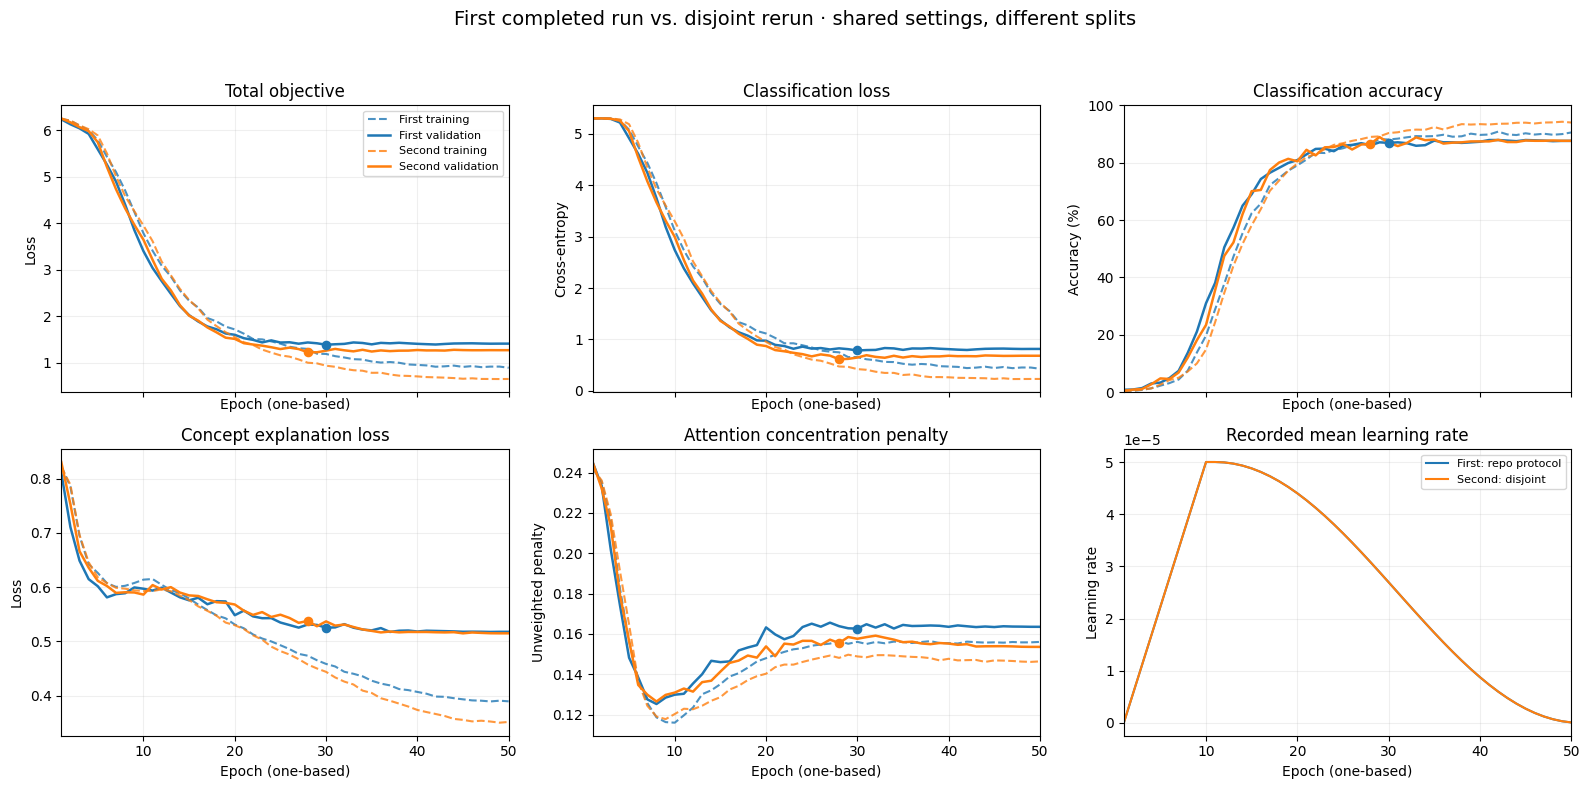

In [22]:
comparison_figure, comparison_axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
comparison_curve_panels = [
    ('Total objective', 'train_loss', 'val_total_loss_derived', 'Loss', 1),
    ('Classification loss', 'train_ce_loss', 'val_ce_loss', 'Cross-entropy', 1),
    ('Classification accuracy', 'train_acc', 'val_acc', 'Accuracy (%)', 100),
    ('Concept explanation loss', 'train_expl_loss', 'val_expl_loss', 'Loss', 1),
    ('Attention concentration penalty', 'train_l1_loss', 'val_l1_loss', 'Unweighted penalty', 1),
]
for axis, (title, train_tag, val_tag, ylabel, scale) in zip(comparison_axes.flat, comparison_curve_panels):
    for job in comparison_jobs:
        frame = comparison_epochs[job]
        color = comparison_colors[job]
        label = 'First' if job == '45387524' else 'Second'
        axis.plot(frame.index, frame[train_tag] * scale, color=color, linestyle='--', linewidth=1.5, alpha=0.8, label=label + ' training')
        axis.plot(frame.index, frame[val_tag] * scale, color=color, linewidth=1.8, label=label + ' validation')
        selected = comparison_selected_epochs[job]
        axis.scatter([selected], [frame.loc[selected, val_tag] * scale], color=color, s=35, zorder=5)
    axis.set(title=title, xlabel='Epoch (one-based)', ylabel=ylabel, xlim=(1, 50))
    axis.grid(alpha=0.2)
comparison_axes[0, 2].set_ylim(0, 100)
for job in comparison_jobs:
    frame = comparison_epochs[job]
    comparison_axes[1, 2].plot(frame.index, frame.learning_rate, color=comparison_colors[job], label=comparison_labels[job])
comparison_axes[1, 2].set(title='Recorded mean learning rate', xlabel='Epoch (one-based)', ylabel='Learning rate', xlim=(1, 50))
comparison_axes[1, 2].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
comparison_axes[1, 2].grid(alpha=0.2)
comparison_axes[0, 0].legend(fontsize=8, loc='upper right')
comparison_axes[1, 2].legend(fontsize=8)
comparison_figure.suptitle('First completed run vs. disjoint rerun · shared settings, different splits', fontsize=14)
comparison_figure.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()


#### Test performance and checkpoint-selection accuracy

The new test accuracy is **1.04 percentage points lower** (87.33% → 86.29%), while its test classification CE is **0.0523 lower** (0.7376 → 0.6853). Accuracy depends on the predicted class; CE also depends on its probability. Those metrics can move in different directions, especially with different evaluation memberships. These values do not establish that removing overlap caused either change or that probability calibration improved.

Test explanation loss is nearly unchanged at the displayed scale (**0.5344 → 0.5346**). The unweighted concentration penalty is lower (**0.1626 → 0.1557**); that indicates lower values of this logged attention penalty, not a measured gain in explanation faithfulness. No statistical significance or across-seed improvement is established by these two runs.


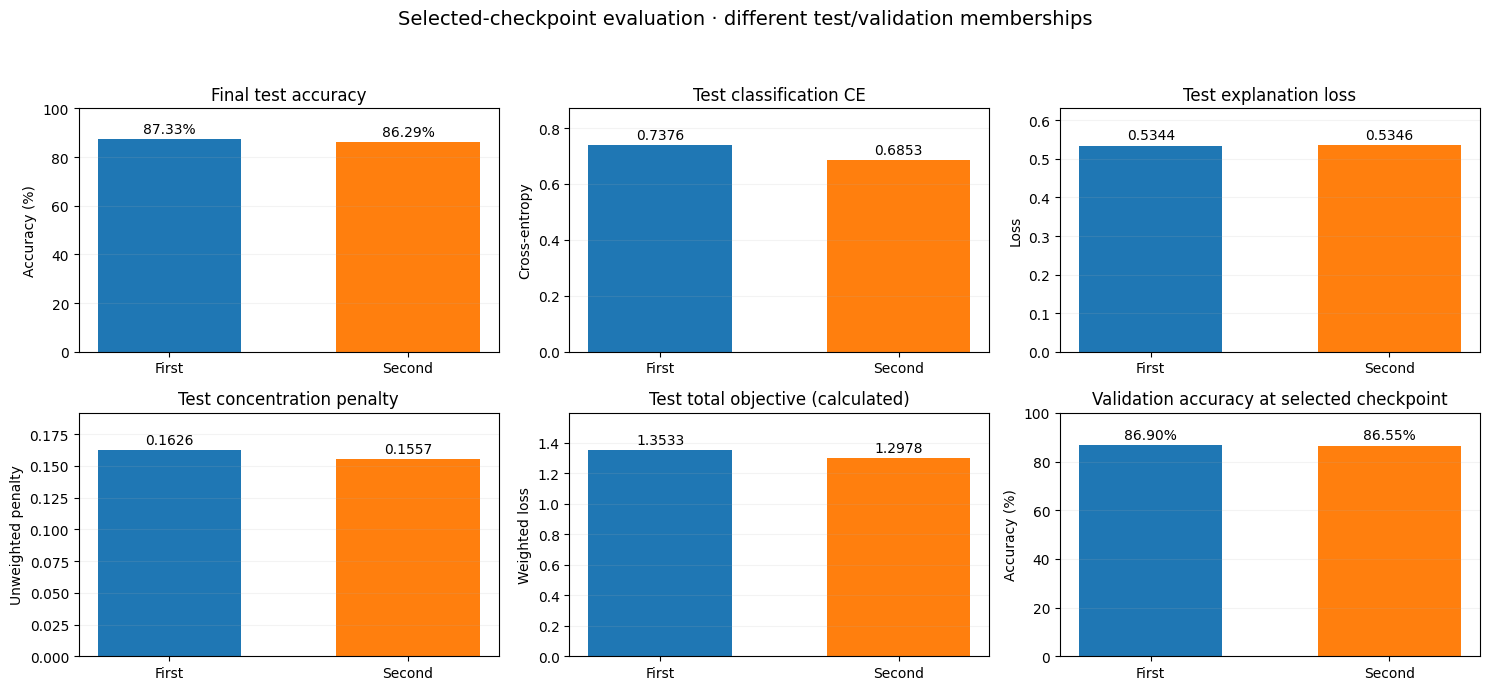

In [23]:
comparison_metric_figure, comparison_metric_axes = plt.subplots(2, 3, figsize=(15, 7))
comparison_bar_panels = [
    ('Final test accuracy', 'test_acc', 100, 'Accuracy (%)', '{:.2f}%', 'test'),
    ('Test classification CE', 'test_ce_loss', 1, 'Cross-entropy', '{:.4f}', 'test'),
    ('Test explanation loss', 'test_expl_loss', 1, 'Loss', '{:.4f}', 'test'),
    ('Test concentration penalty', 'test_l1_loss', 1, 'Unweighted penalty', '{:.4f}', 'test'),
    ('Test total objective (calculated)', 'test_total_loss_derived', 1, 'Weighted loss', '{:.4f}', 'test'),
    ('Validation accuracy at selected checkpoint', 'val_acc', 100, 'Accuracy (%)', '{:.2f}%', 'selected'),
]
for axis, (title, tag, scale, ylabel, template, location) in zip(comparison_metric_axes.flat, comparison_bar_panels):
    values = []
    for job in comparison_jobs:
        value = (comparison_records[job]['snapshot']['test_metrics'][tag] if location == 'test'
                 else comparison_epochs[job].loc[comparison_selected_epochs[job], tag])
        values.append(scale * value)
    bars = axis.bar(['First', 'Second'], values, color=[comparison_colors[job] for job in comparison_jobs], width=0.6)
    upper = 100 if scale == 100 else max(values) * 1.18
    axis.set(title=title, ylabel=ylabel, ylim=(0, upper))
    for bar, value in zip(bars, values):
        axis.text(bar.get_x() + bar.get_width() / 2, value + upper * 0.025,
                  template.format(value), ha='center', fontsize=10)
    axis.grid(axis='y', alpha=0.15)
comparison_metric_figure.suptitle('Selected-checkpoint evaluation · different test/validation memberships', fontsize=14)
comparison_metric_figure.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()


#### Runtime, workload, and how to present the comparison

The second run finished **8 minutes 7 seconds sooner** (**1:50:04 → 1:41:57**), with **750 fewer training batches** (**9,350 → 8,600**). Mean training-batch wall time was **0.6522 → 0.6571 seconds**, so the shorter overall run is accompanied by less work and does not demonstrate a throughput improvement. Slurm elapsed time includes initialization, validation, checkpoint I/O, and final testing.

A presentation-ready statement is: **“We first reproduced the repository's evaluation protocol. After confirming validation–test overlap, we repeated training with a saved disjoint split and unchanged model/settings. The rerun achieved 86.29% test accuracy versus 87.33% previously, with lower test CE and a shorter workload. Different training/test memberships and a single seed limit causal conclusions.”**

To make a stronger follow-up comparison, evaluate both saved checkpoints on the same fixed test IDs and repeat training across seeds. A shared test set would remove the test-membership difference, while differences in training size and checkpoint-selection exposure would still need to be considered. The current figures use the recorded final evaluations; they are sufficient to describe what happened in these two completed runs.


,Slurm elapsed (minutes),Training batches,Validation batches,Test batches,Mean training compute (s/batch),Mean training wall (s/batch),Mean validation compute (s/batch),Mean test compute (s/batch)
Run,,,,,,,,
First: repo protocol,110.07,9350,1600,182,0.5341,0.6522,0.1589,0.1632
Second: disjoint,101.95,8600,1450,167,0.5394,0.6571,0.1635,0.1664


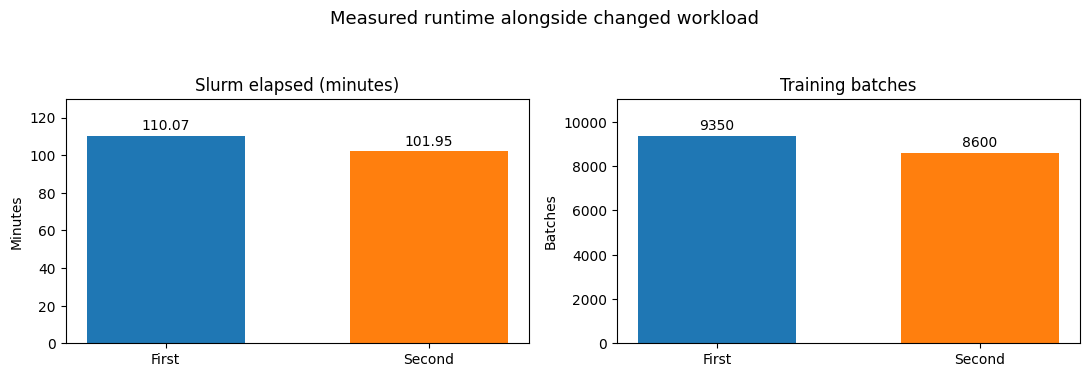

Raw run directories:
45387524 /blue/yonghui.wu/zhangm3/concept_transformer_explain/training_runs/l4-45387524
45478721 /blue/yonghui.wu/zhangm3/concept_transformer_explain/training_runs/disjoint-proportional-seed42-20261010/l4-45478721
Both checkpoints were selected by minimum validation CE; all 50 epochs are included in the plots.


In [24]:
comparison_timing_rows = []
for job in comparison_jobs:
    snap = comparison_records[job]['snapshot']
    comparison_timing_rows.append({
        'Run': comparison_labels[job],
        'Slurm elapsed (minutes)': comparison_elapsed_seconds(snap['scheduler']['Elapsed']) / 60,
        'Training batches': snap['train_batches'],
        'Validation batches': snap['phase_counts']['validation'],
        'Test batches': snap['phase_counts']['test'],
        'Mean training compute (s/batch)': snap['mean_train_batch_compute_seconds'],
        'Mean training wall (s/batch)': snap['mean_train_batch_wall_seconds'],
        'Mean validation compute (s/batch)': snap['mean_validation_batch_compute_seconds'],
        'Mean test compute (s/batch)': snap['mean_test_batch_compute_seconds'],
    })
comparison_timing_table = pd.DataFrame(comparison_timing_rows).set_index('Run')
display(comparison_timing_table.style.format({
    column: '{:.4f}' if '(s/batch)' in column else '{:.2f}' if '(minutes)' in column else '{:.0f}'
    for column in comparison_timing_table.columns
}))
comparison_work_figure, comparison_work_axes = plt.subplots(1, 2, figsize=(11, 3.8))
for axis, column, ylabel, template in [
    (comparison_work_axes[0], 'Slurm elapsed (minutes)', 'Minutes', '{:.2f}'),
    (comparison_work_axes[1], 'Training batches', 'Batches', '{:.0f}'),
]:
    values = comparison_timing_table[column].to_numpy()
    bars = axis.bar(['First', 'Second'], values, color=[comparison_colors[job] for job in comparison_jobs], width=0.6)
    upper = max(values) * 1.18
    axis.set(title=column, ylabel=ylabel, ylim=(0, upper))
    for bar, value in zip(bars, values):
        axis.text(bar.get_x() + bar.get_width() / 2, value + upper * 0.025, template.format(value), ha='center')
comparison_work_figure.suptitle('Measured runtime alongside changed workload', fontsize=13)
comparison_work_figure.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()
print('Raw run directories:')
for job in comparison_jobs:
    print(job, comparison_records[job]['snapshot']['source_run'])
print('Both checkpoints were selected by minimum validation CE; all 50 epochs are included in the plots.')


### 5.4 Concept explanations: correct and incorrect test predictions

These are **six actual predictions from the disjoint run 45478721**, using its selected **epoch-28 checkpoint** and the saved **5,341-image test partition**. Attention was recomputed with those weights in CPU float32 evaluation mode. We scanned 16 of 64 predetermined, evenly spaced test positions and kept the first three correct and three incorrect predictions with distinct true classes in each group. Their probabilities describe these recomputed examples; they are not a new full-test accuracy measurement.

This follows the [paper's Equation 2 and Figures 4–5](https://openreview.net/pdf?id=kAa9eDS0RdO): explanations are learned attention over named concepts, and the classifier combines their learned value vectors linearly. The model uses **13 global concepts** (size, shape, primary color) and **95 spatial concepts** (part colors, patterns, etc.) on a **14 × 14 patch grid**.

Read each detailed figure as follows:

- **Input and three spatial maps:** the three highest peak-attention concepts from different attribute families. Brighter colors mean higher attention on a fixed **0–1** scale. These are the original patches, with no smoothing or per-image rescaling. Cyan rings mark patches where the CUB explanation target is positive.
- **Global bars:** five highest attention weights, averaged across heads. An asterisk marks a positive CUB target. An unmarked concept is not evidence that the attribute is absent everywhere; annotations and visible part coverage are incomplete.
- **Signed contribution bars:** green supports the predicted class over the comparison; red supports the comparison. For an error the comparison is the **true class**; for a correct prediction it is the **runner-up**. All remaining concepts and classifier biases are included as aggregate bars, so their sum equals the displayed logit margin.

**Attention and class support answer different questions.** We retain each head when computing contributions: for concept c and class k, its contribution is the sum over heads of mean patch attention times that head's value-to-class coefficient. Summing all 108 contributions and both classifier biases reconstructs every raw class logit, with maximum error **0.00000954** on the scanned images. For class differences this also equals the log-probability difference. This numerical identity verifies the classifier decomposition; it does not establish perfect concept recognition or localization.

The following cells display cached results immediately. The reproducible extraction/plotting script is `scripts/visualize_test_explanations.py`; PNG/PDF figures, cached tensors, image IDs, probabilities, source hashes, and a local HTML gallery are in `explanation_artifacts/disjoint-45478721/`. Set `RERUN_EXPLANATIONS=True` only to recompute these examples from the saved model.


In [1]:
from pathlib import Path
import json
import subprocess
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

explanation_project = Path('/orange/yonghui.wu/zhangm3/2026/concept_transformer_explain')
explanation_dir = explanation_project / 'explanation_artifacts/disjoint-45478721'
RERUN_EXPLANATIONS = False
if RERUN_EXPLANATIONS:
    subprocess.run([sys.executable, str(explanation_project / 'scripts/visualize_test_explanations.py')], check=True)
explanation_report = json.loads((explanation_dir / 'examples.json').read_text())
explanation_arrays = np.load(explanation_dir / 'selected_examples.npz')
explanation_notebook = json.loads((explanation_project / 'concept_transformer_walkthrough.ipynb').read_text())
assert explanation_report['manifest_sha256'] == explanation_notebook['metadata']['disjoint_training_job']['manifest_sha256']
assert explanation_report['checkpoint_path'] == explanation_notebook['metadata']['disjoint_training_job']['completion_verification']['checkpoint_path']
assert explanation_report['checkpoint_epoch_one_based'] == 28
assert len(explanation_report['examples']) == 6
assert sum(sample['correct'] for sample in explanation_report['examples']) == 3
explanation_reconstructed = explanation_arrays['contributions'].sum(axis=1) + explanation_arrays['bias']
np.testing.assert_allclose(explanation_reconstructed, explanation_arrays['logits'], atol=1e-4, rtol=1e-4)
for index, sample in enumerate(explanation_report['examples']):
    assert sample['correct'] == (sample['true_label'] == sample['predicted_label'])
    assert int(explanation_arrays['logits'][index].argmax()) == sample['predicted_label']
    contribution_margin = (explanation_arrays['contributions'][index, :, sample['predicted_label']]
                           - explanation_arrays['contributions'][index, :, sample['comparison_label']]).sum() + sample['bias_margin']
    np.testing.assert_allclose(contribution_margin, sample['logit_margin'], atol=1e-4)
    assert (explanation_dir / sample['figure_png']).is_file()
explanation_rows = [{
    'Outcome': 'Correct' if sample['correct'] else 'Wrong', 'Image ID': sample['image_id'],
    'True species': sample['true_class'], 'Predicted species': sample['predicted_class'],
    'Prediction probability (%)': 100 * sample['predicted_probability'],
    'True-class probability (%)': 100 * sample['true_probability'],
    'Comparison species': sample['comparison_class'], 'Logit margin': sample['logit_margin'],
} for sample in explanation_report['examples']]
display(pd.DataFrame(explanation_rows).set_index(['Outcome', 'Image ID']).style.format({
    'Prediction probability (%)': '{:.2f}', 'True-class probability (%)': '{:.2f}', 'Logit margin': '{:.4f}',
}))
print('Checkpoint:', explanation_report['checkpoint_path'])
print('Selection:', explanation_report['selection_rule'])
print('Maximum all-class logit reconstruction error:', explanation_report['maximum_logit_reconstruction_error'])
print('Local gallery:', explanation_dir / 'gallery.html')


Checkpoint: /blue/yonghui.wu/zhangm3/concept_transformer_explain/training_runs/disjoint-proportional-seed42-20261010/l4-45478721/cub_cvit/CUB2011Parts_expl1.0/binary_mnist_best_ckpt.ckpt
Selection: First three predictions per correctness status with distinct true classes, scanning 64 evenly spaced saved test positions in ascending order; stop after both groups are filled.
Maximum all-class logit reconstruction error: 9.5367431640625e-06
Local gallery: /orange/yonghui.wu/zhangm3/2026/concept_transformer_explain/explanation_artifacts/disjoint-45478721/gallery.html


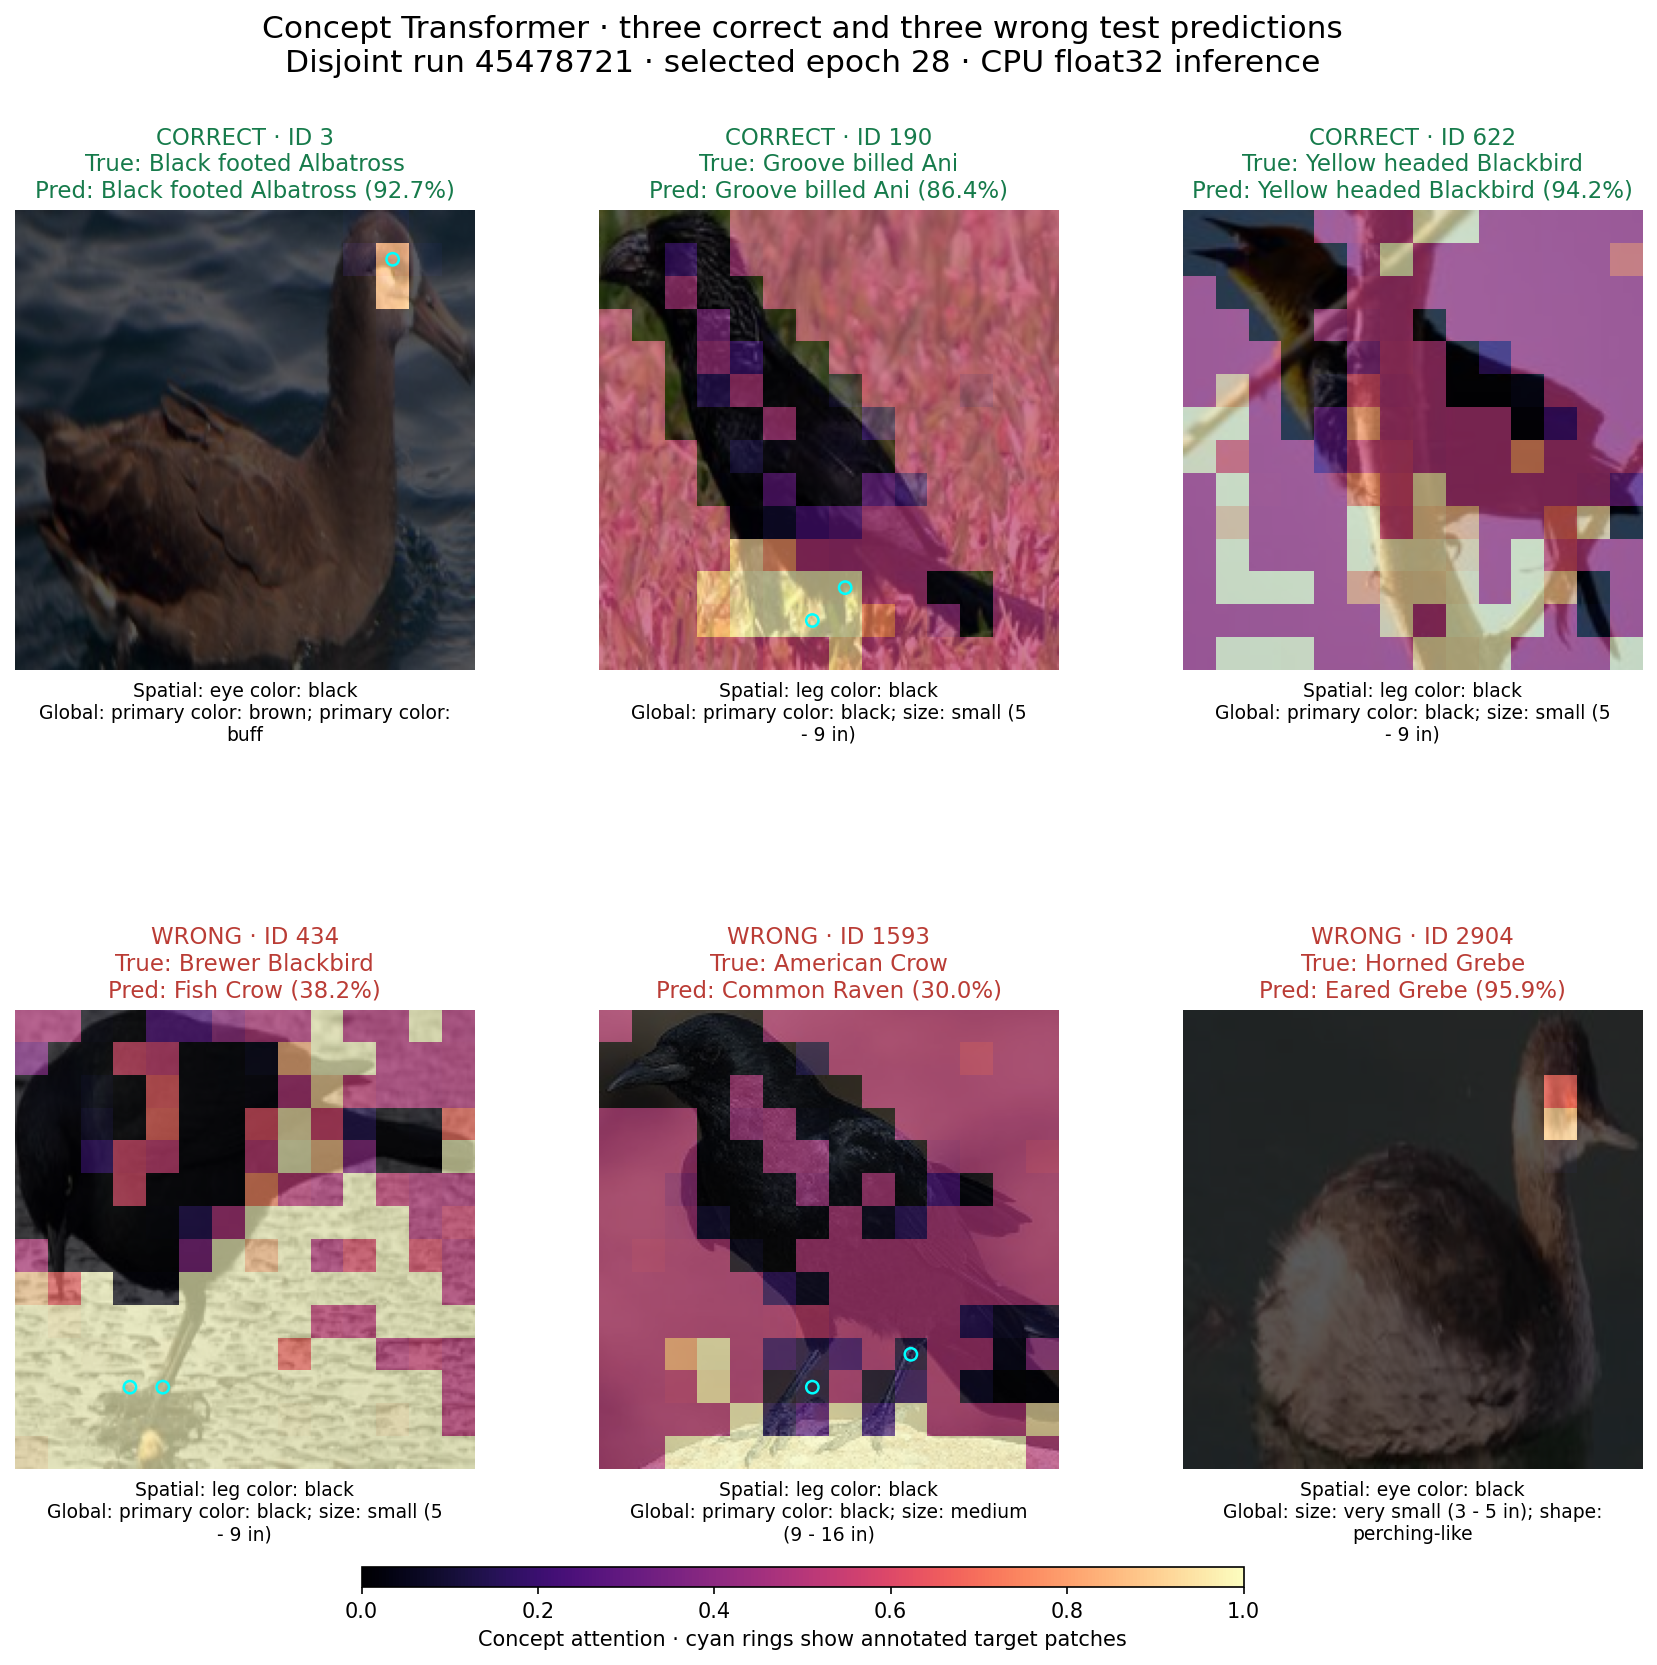

In [2]:
display(Image(filename=str(explanation_dir / 'overview.png'), width=1200))


#### Three correct predictions

**Black footed Albatross (ID 3, 92.7%)**: brown primary color receives the largest global attention and contributes **+2.21** to the margin over Sooty Albatross; buff primary color adds **+1.22**. The eye-color map focuses near the eye. Other concept assignments differ from the CUB targets, so a correct species prediction does not imply a perfect explanation.

**Groove billed Ani (ID 190, 86.4%)**: the model attends to black primary color (**0.457**) and small size (**0.211**), both present in its CUB target. Black upperparts contribute **+1.82** over Yellow headed Blackbird. Black-leg attention is high, yet its signed contribution is **−1.60** against that comparison: high attention alone does not mean positive class support.

**Yellow headed Blackbird (ID 622, 94.2%)**: global black, small-size, and yellow-color concepts match positive CUB targets. Black-leg and small-size contributions favor this class over Groove billed Ani (**+3.15** and **+2.12**). The black-leg map also activates background patches. This is a useful example of correct classification alongside imperfect localization.


**Correct · image 3 · Black footed Albatross (92.7%)**

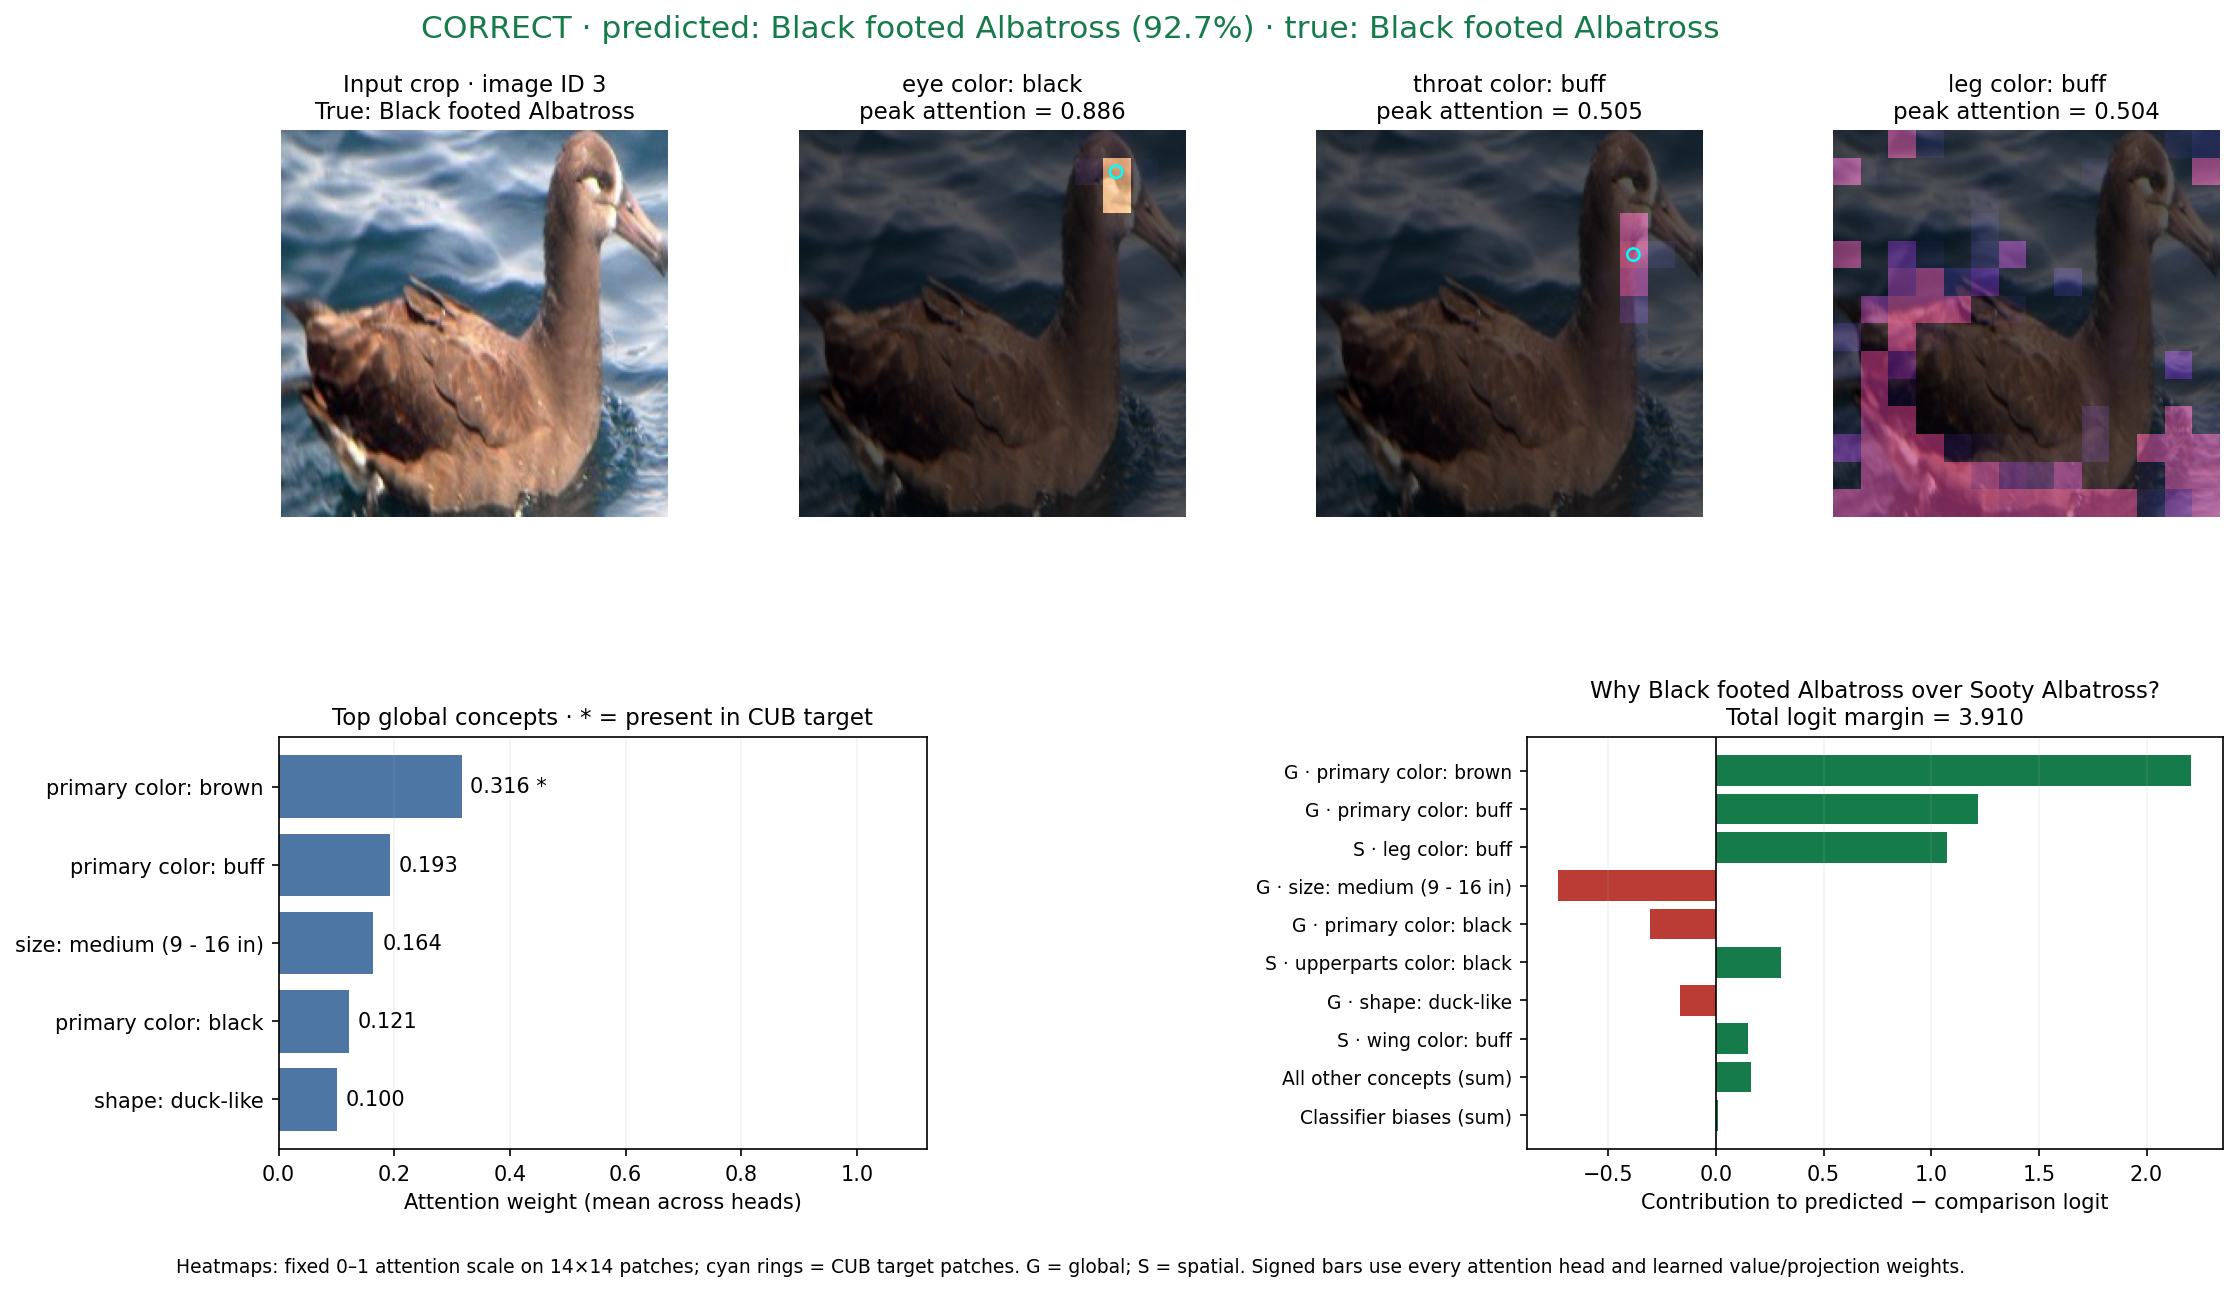

**Correct · image 190 · Groove billed Ani (86.4%)**

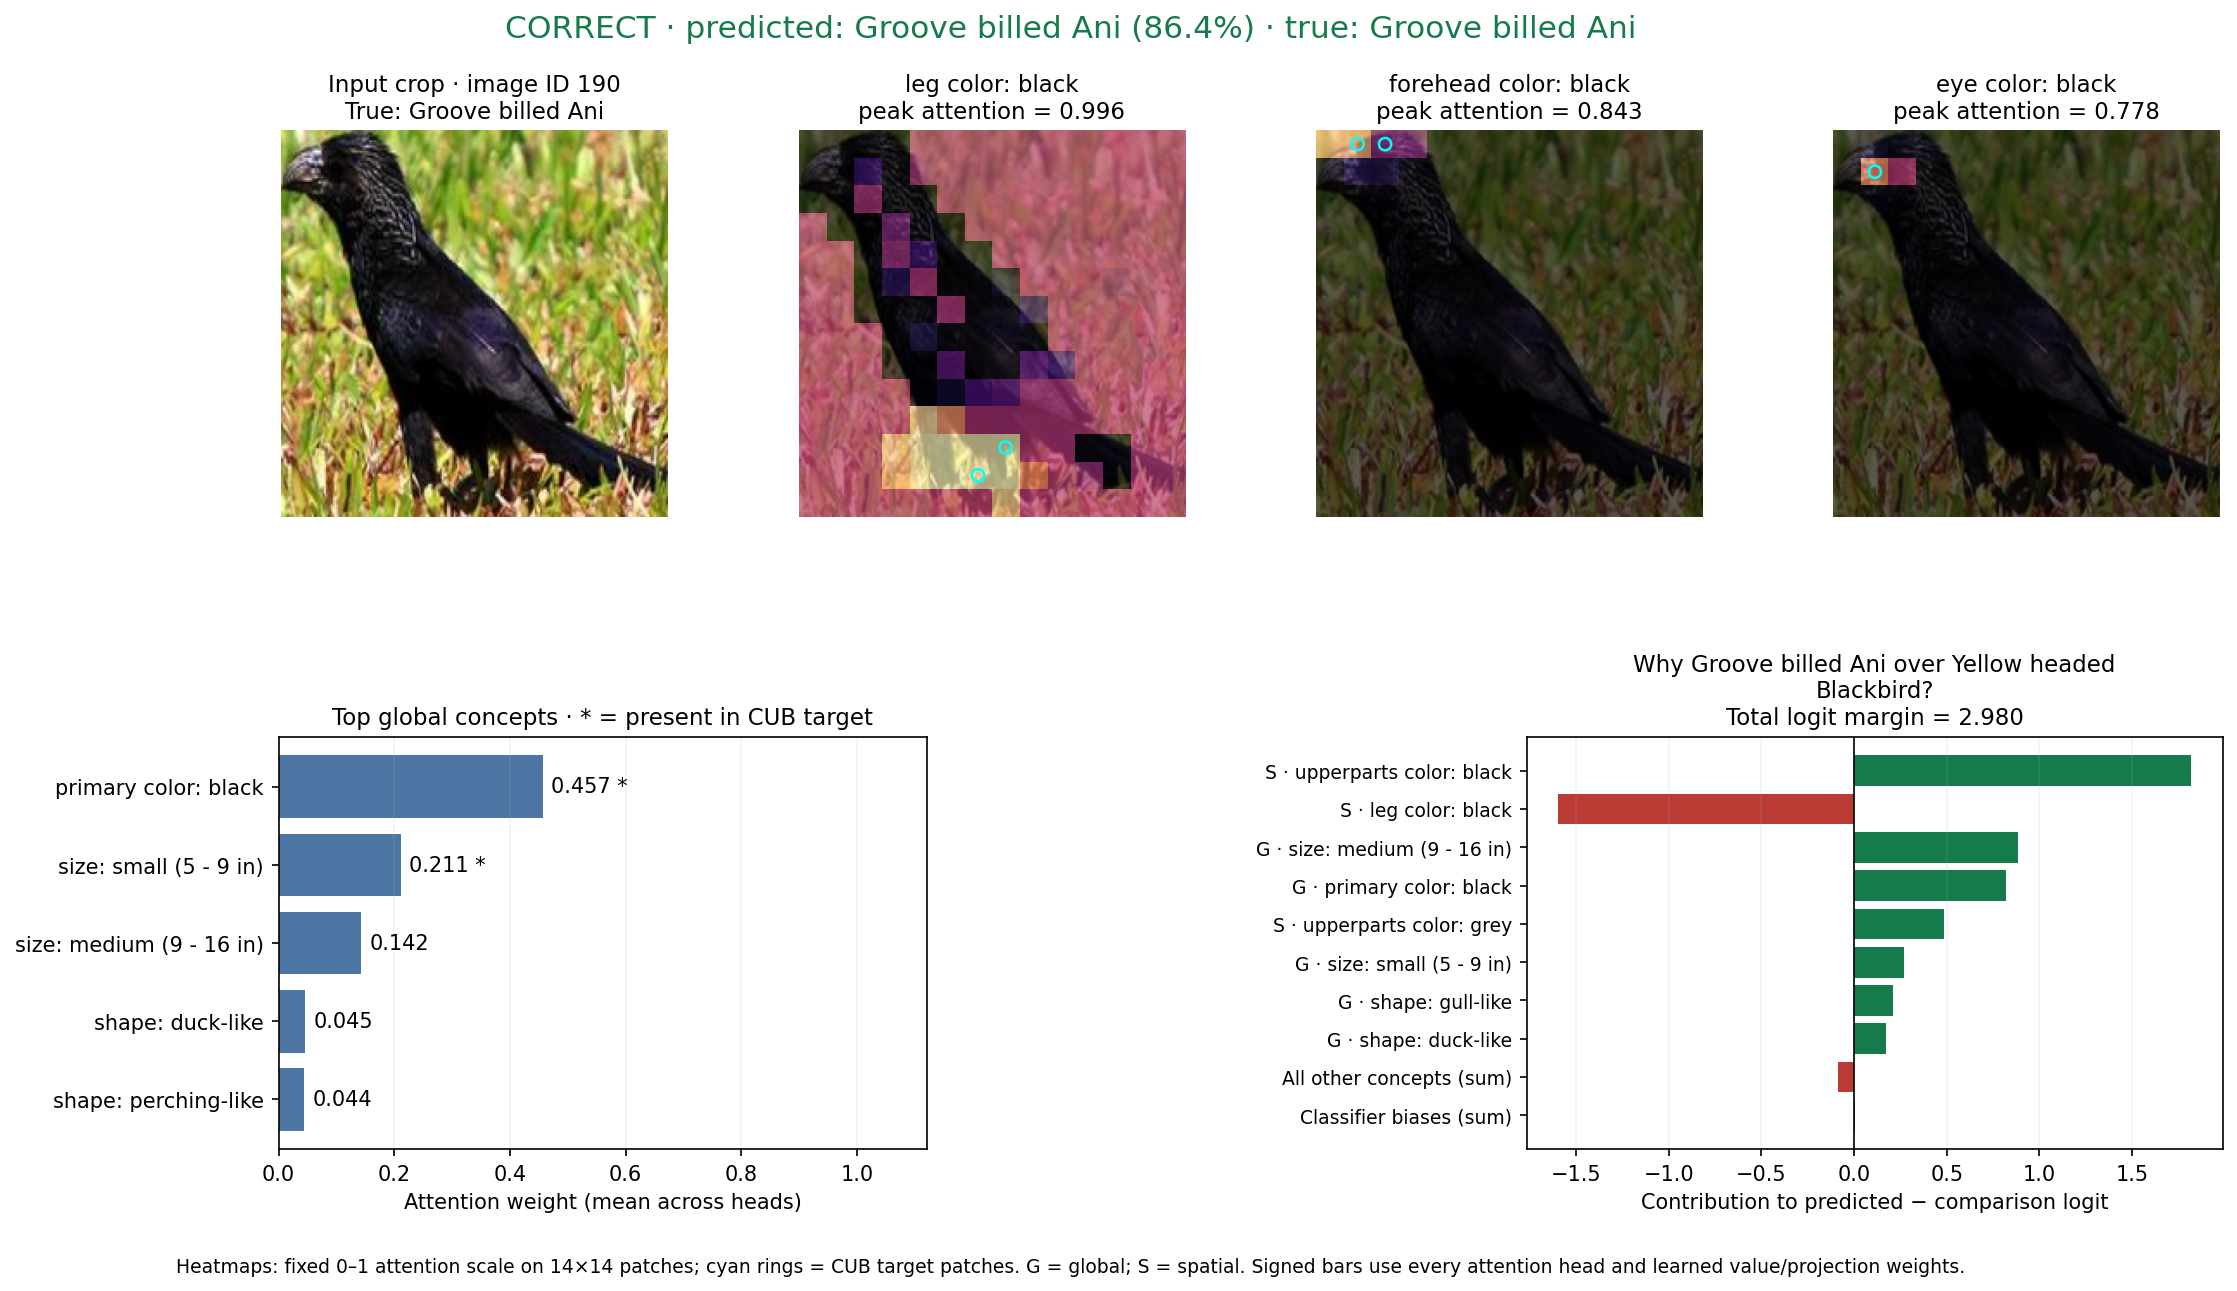

**Correct · image 622 · Yellow headed Blackbird (94.2%)**

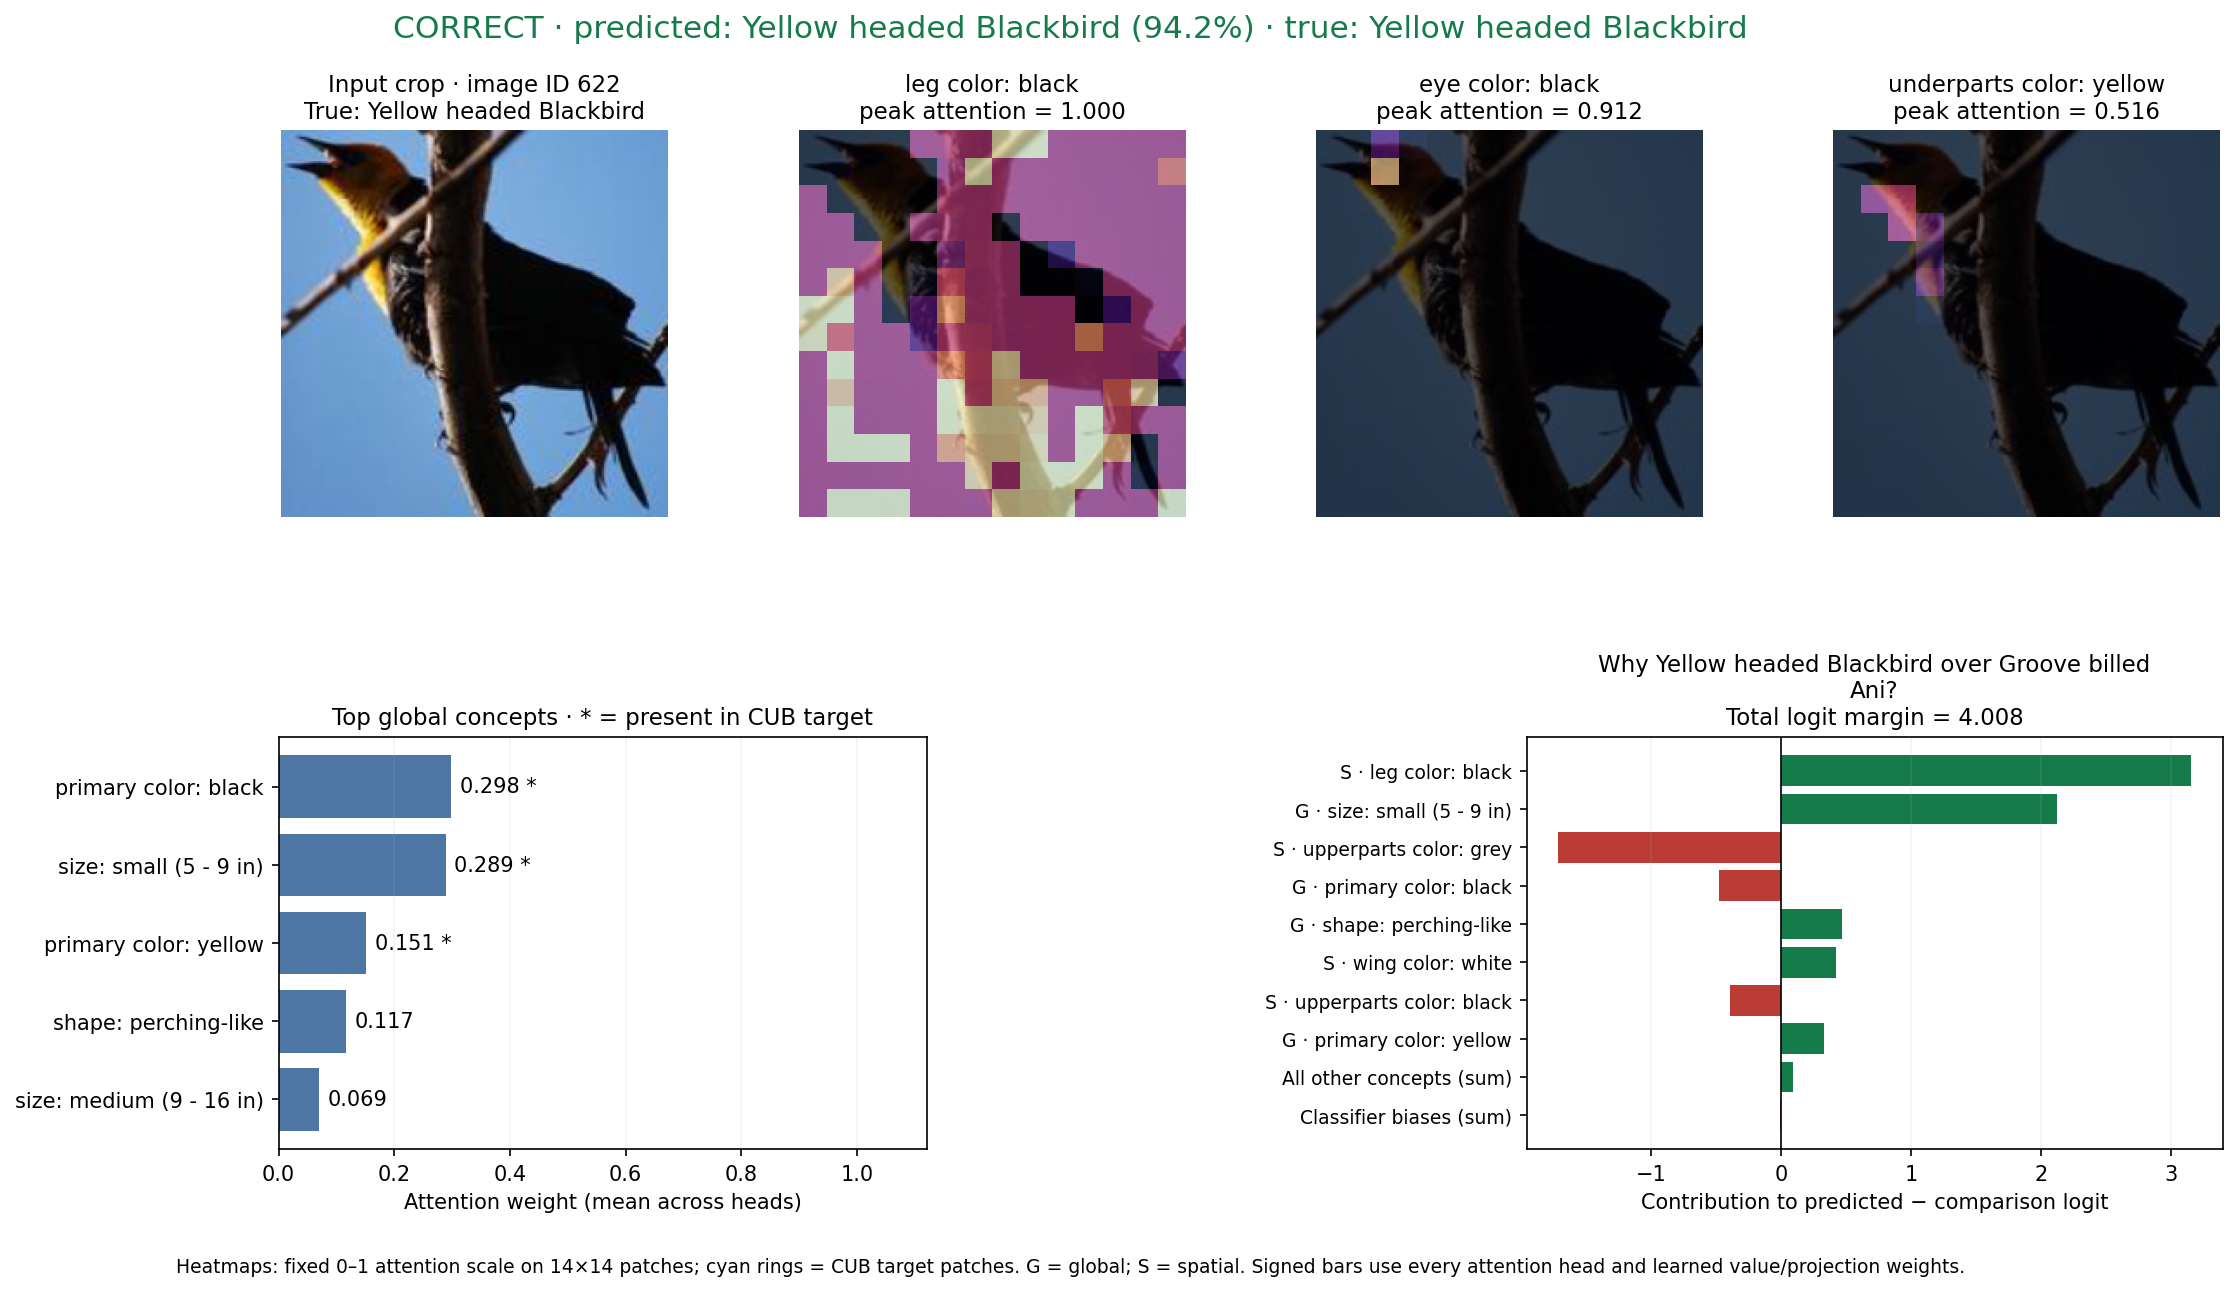

In [3]:
for sample in explanation_report['examples']:
    if sample['correct']:
        display(Markdown('**Correct · image {} · {} ({:.1%})**'.format(
            sample['image_id'], sample['predicted_class'], sample['predicted_probability'])))
        display(Image(filename=str(explanation_dir / sample['figure_png']), width=1400))


my understanding to read the visualization: 
- there are 3 spatial maps, selected for high peak attention, the contribution bar shows the top concepts that contribute most to the class decision.
- in the attention weight bar, the number does not mean a 29.8% that bird in that color, it is relative weights, At each patch, spatial attention is normalized across the 95 concepts.

why it has more explanability:
This CT model can ingertagte conceps that have meanings humna can recoginize, it can expose the specific feature of the 


#### Three incorrect predictions and what the concepts reveal

**Brewer Blackbird → Fish Crow (ID 434, 38.2%; true class 25.5%)**: black primary color contributes **+0.64** and medium size **+0.39** toward Fish Crow. Small size supplies **−1.05**, favoring the true Brewer Blackbird. The complete concept/bias sum still favors Fish Crow by **0.404** logits. This identifies competing class evidence; it does not imply that black color alone caused the error.

**American Crow → Common Raven (ID 1593, 30.0%; true class 29.7%)**: black upperparts (**+0.65**) and a solid wing pattern (**+0.27**) favor Raven, while black primary color (**−0.49**), black legs (**−0.29**), and medium size (**−0.21**) favor Crow. The net margin is only **0.0122** logits: this is a near-tie error with opposing concept evidence.

**Horned Grebe → Eared Grebe (ID 2904, 95.9%; true class 0.23%)**: grey upperparts contribute **+4.45** and the model's very-small-size concept **+1.94** toward Eared Grebe. Black upperparts favor the true Horned Grebe (**−1.53**), but the total margin is **6.02** logits. The displayed grey map spreads over the bird and background; the top five global concepts are not positive in this image's CUB target. This example exposes a confident mistake and mismatched concept assignments despite a readable eye-region heatmap.


**Wrong · image 434 · Brewer Blackbird → Fish Crow (38.2%)**

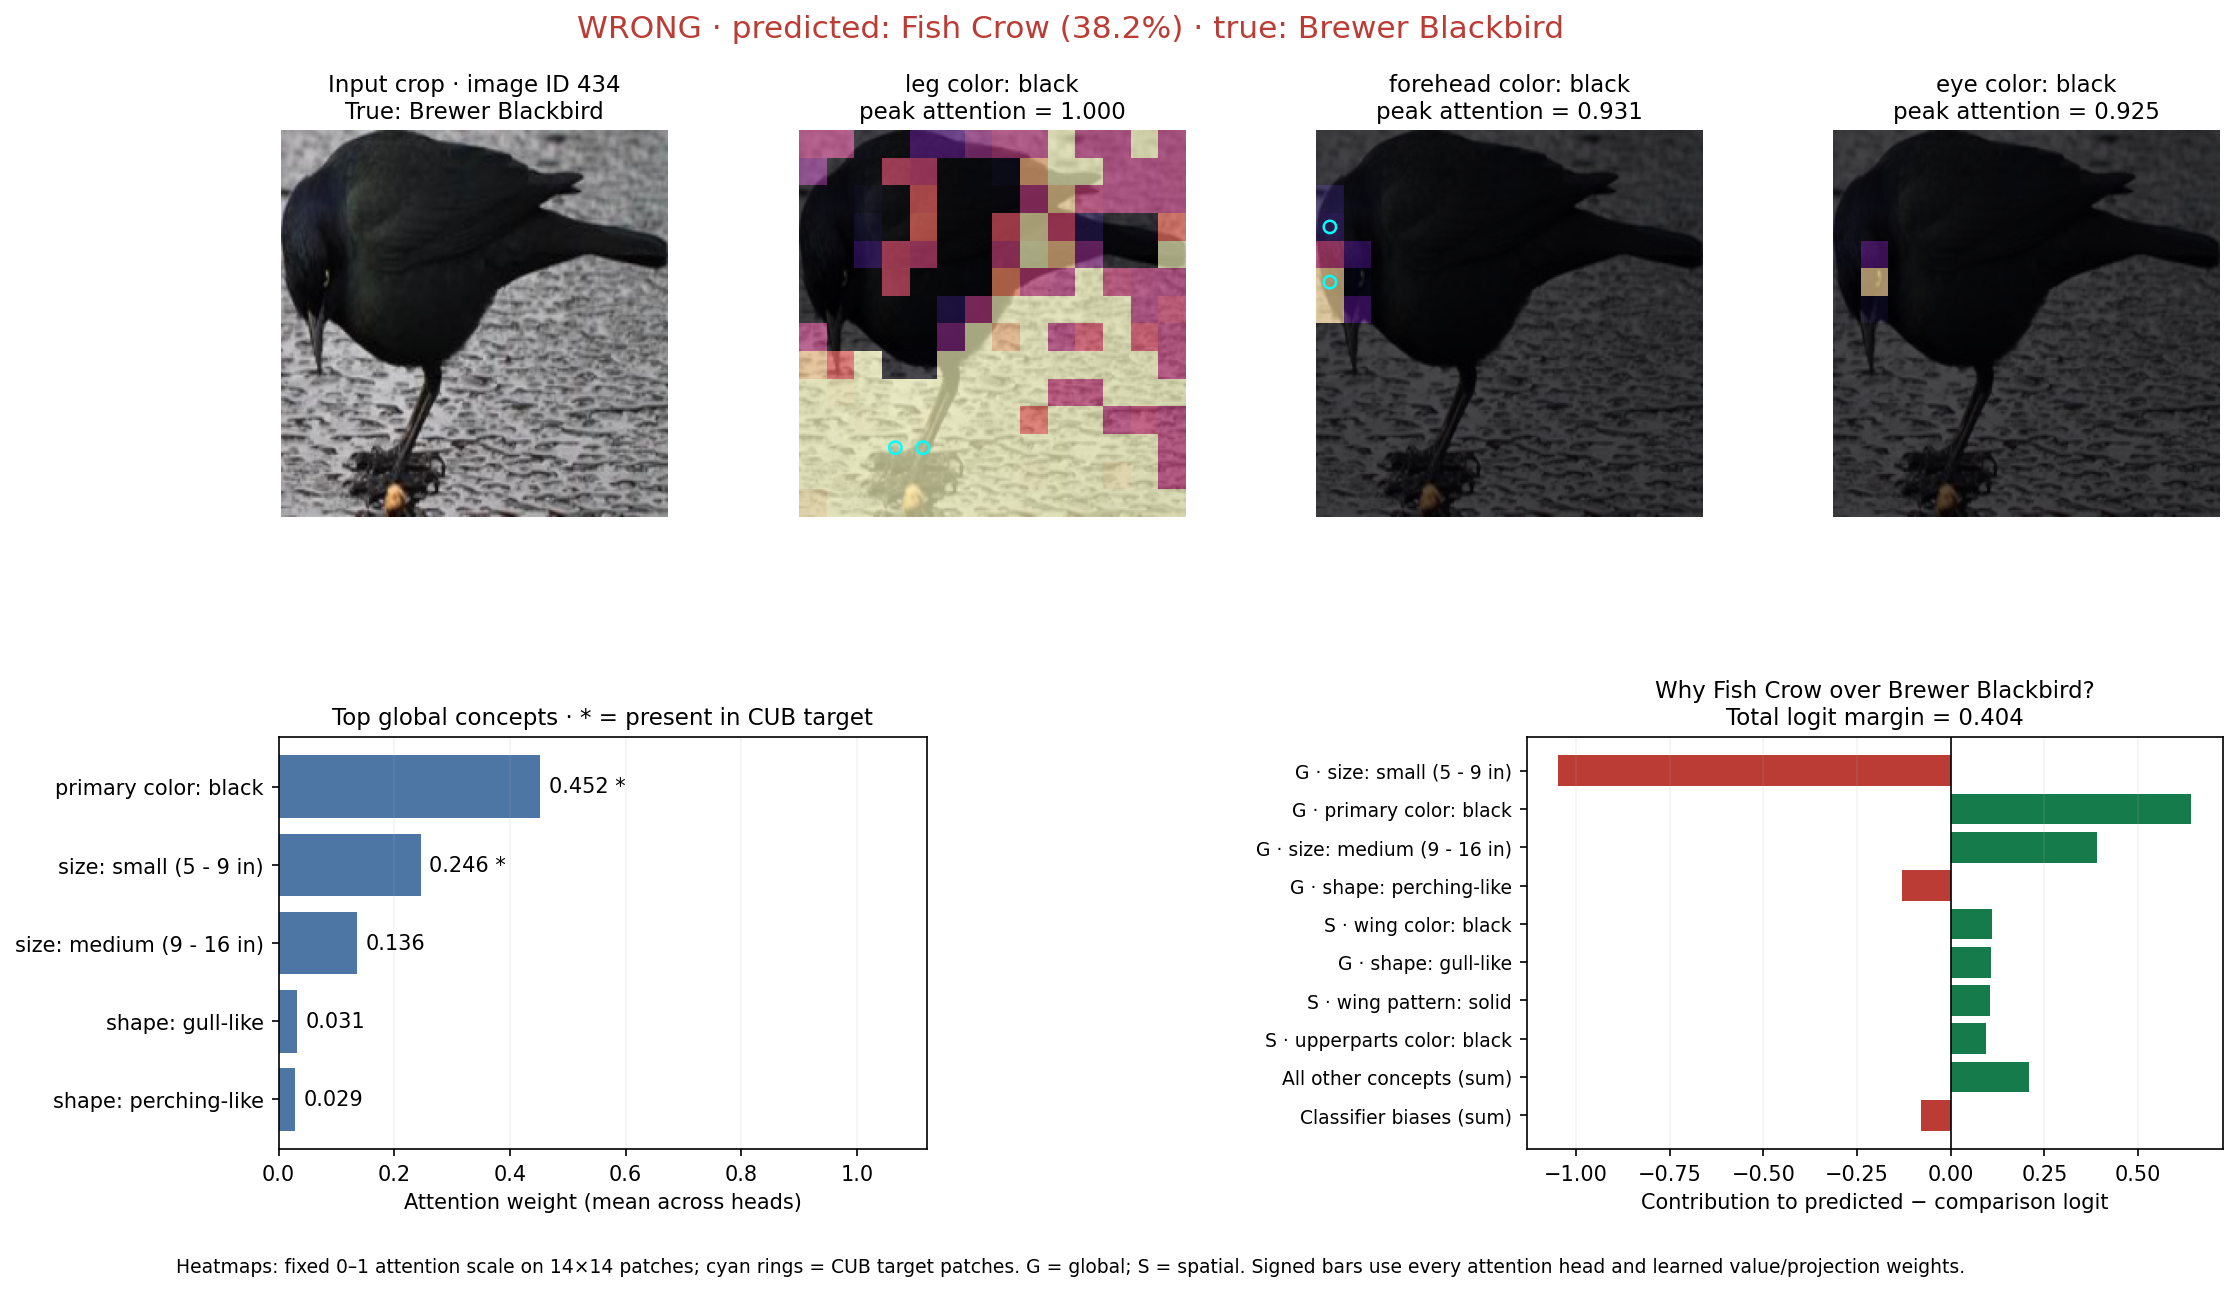

**Wrong · image 1593 · American Crow → Common Raven (30.0%)**

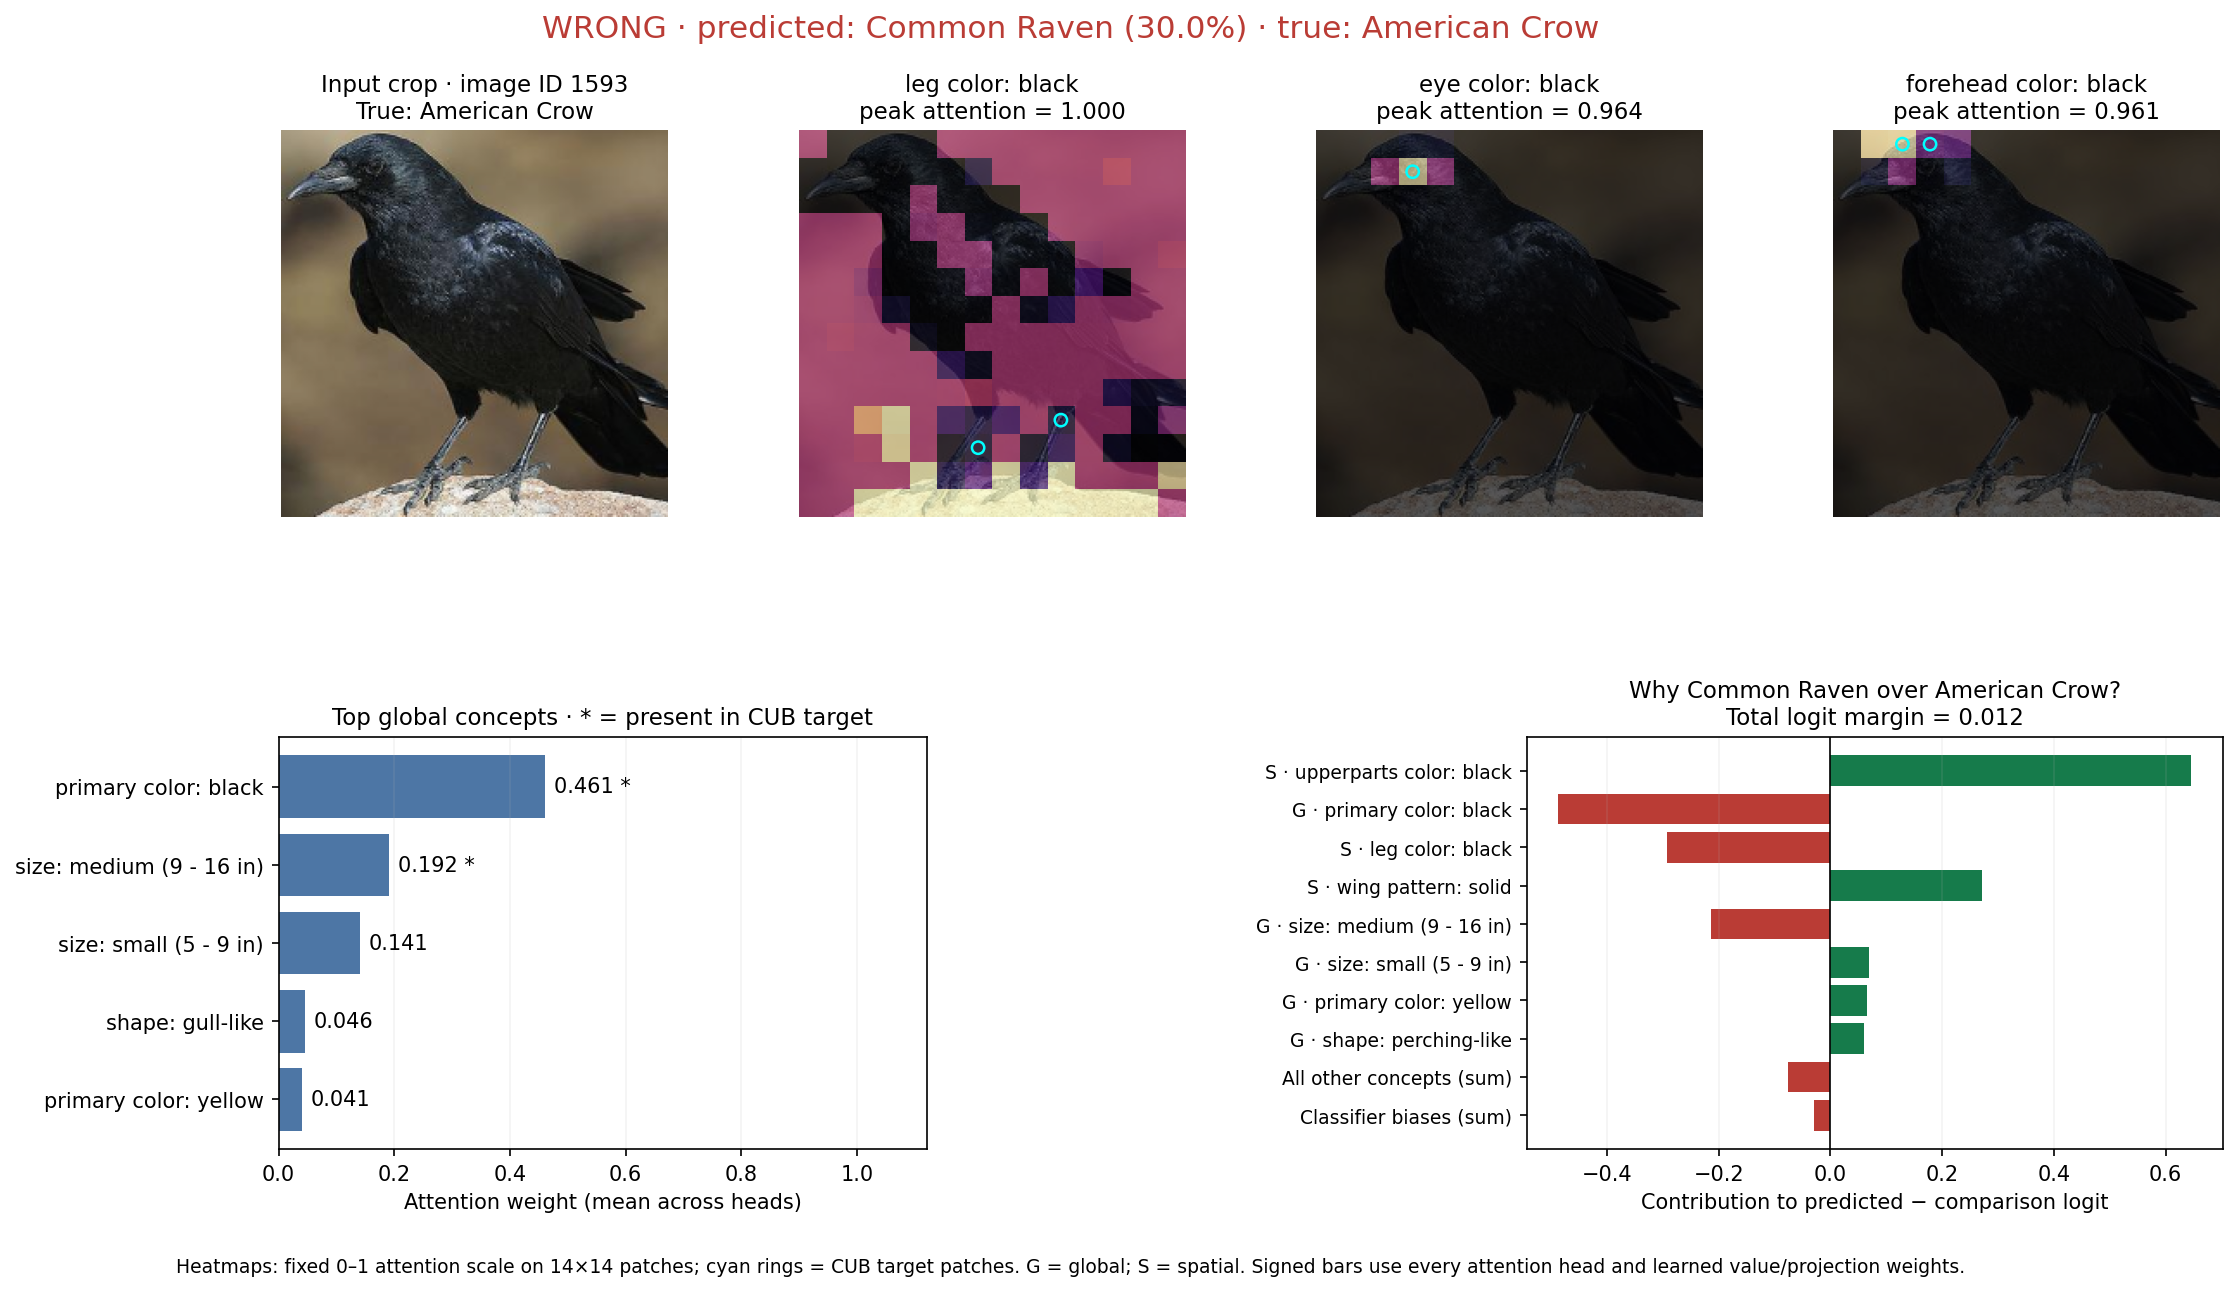

**Wrong · image 2904 · Horned Grebe → Eared Grebe (95.9%)**

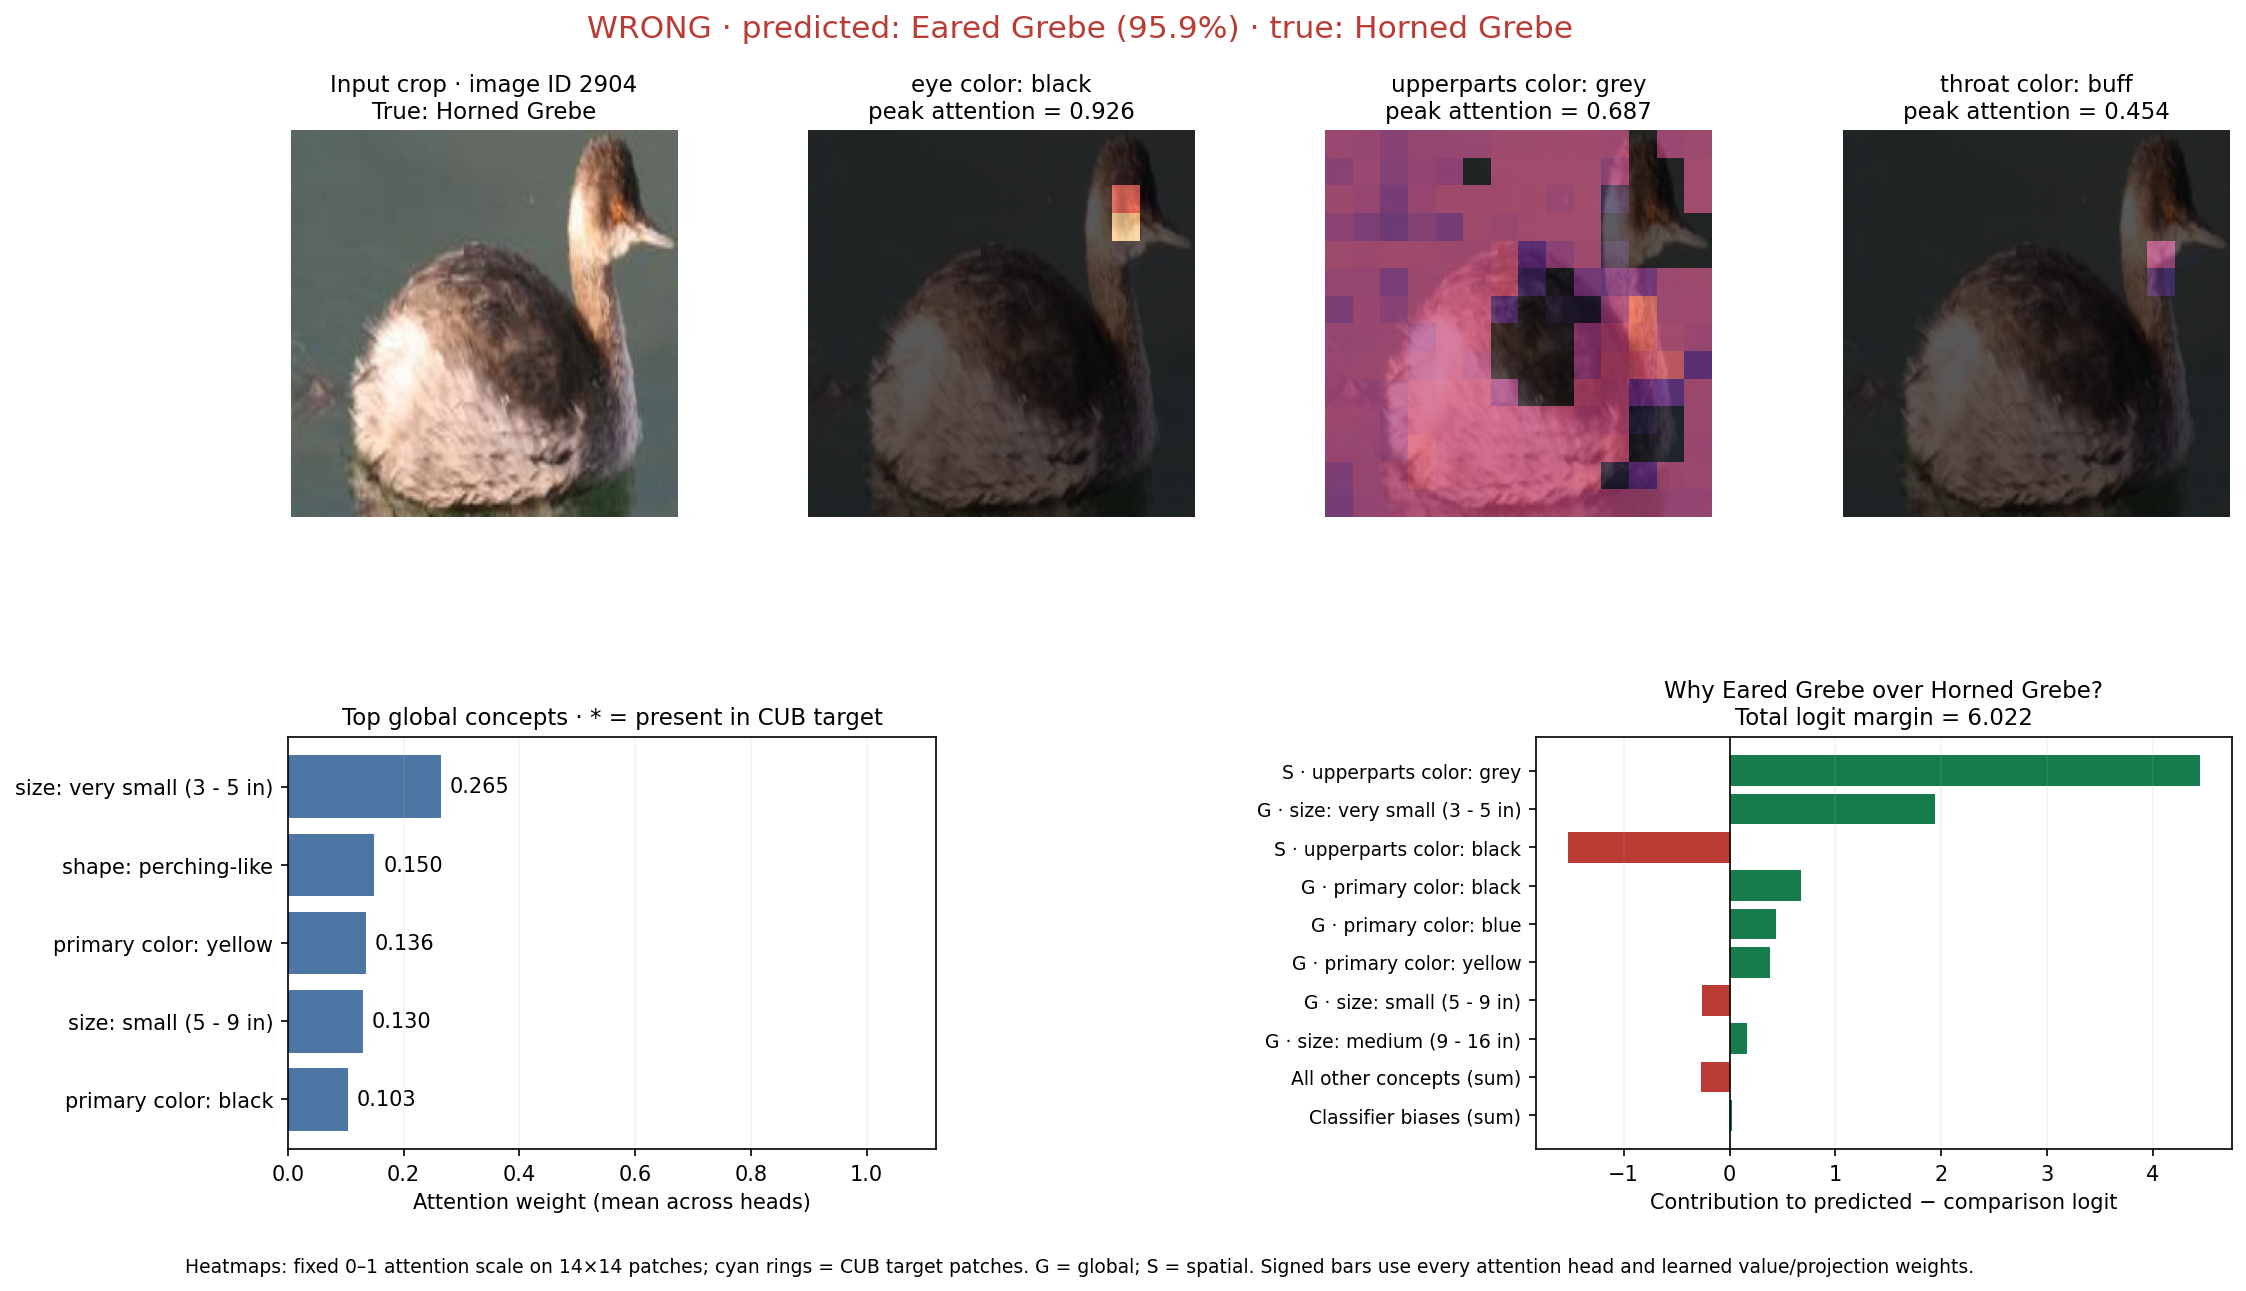

In [4]:
for sample in explanation_report['examples']:
    if not sample['correct']:
        display(Markdown('**Wrong · image {} · {} → {} ({:.1%})**'.format(
            sample['image_id'], sample['true_class'], sample['predicted_class'], sample['predicted_probability'])))
        display(Image(filename=str(explanation_dir / sample['figure_png']), width=1400))


#### What these examples establish

These visualizations expose **which concepts the model attends to, where it attends, and how those concepts enter its class comparison**. They reveal competing evidence in a near tie, incorrect size/color assignments in a confident error, and imperfect localization even for correct predictions. The interpretation concerns the saved model's computation; it is not a claim that the concepts are visually or biologically correct.

Six selected cases are qualitative examples. Evaluating explanation quality across the dataset would require separate measurements of concept agreement and localization, together with additional faithfulness checks. The per-example class-margin sum is already verified here. The split is disjoint within this run, while these test images were previously evaluated by the project's first run, as documented in Section 5.3.


## 6. Discussion

### 6.1 Hyperparameter hypotheses from the first completed run

**The non-overlapping baseline is now complete; no hyperparameter tuning was performed between these two runs.** The following hypotheses were motivated by the first run. Compare any future learning-rate, weight-decay, explanation-weight, or sparsity-weight changes with the new baseline under its fixed split and selection rule. The actual two-run comparison is in Section 5.3. The first two proposed tuning experiments would change only `learning_rate` to **2.5e-5**, then separately change only `weight_decay` to **1e-2**, each compared with a baseline under the same evaluation protocol. These are hypotheses to test, not measured improvements. The completed run remains the reference: **87.33% test accuracy**, selected using minimum validation classification loss.

#### What the learning curves tell us

These values come from the complete TensorBoard evidence embedded in this notebook; epochs are one-based.

| Diagnostic | Epoch 30: selected checkpoint | Epoch 50: final epoch | Implication |
| --- | --- | --- | --- |
| Training classification loss | 0.6576 | 0.4302 | The model continues fitting the training data. |
| Validation classification loss | 0.7853 | 0.8158 | Generalization by this metric worsens slightly after the selected epoch. |
| Training accuracy | 88.08% | 90.54% | Training accuracy continues to improve. |
| Validation accuracy | 86.90% | 87.60% | Accuracy and classification loss do not select the same epoch. |
| Training explanation loss | 0.4583 | 0.3893 | Concept fitting continues to improve on training examples. |
| Validation explanation loss | 0.5251 | 0.5176 | Concept generalization improves only modestly. |

This pattern is consistent with mild late overfitting or increasingly confident incorrect predictions; aggregate losses alone cannot distinguish those explanations. Training also uses augmentation and dropout, so the train/validation gap is not a perfectly matched comparison. **Simply increasing 50 epochs is not the first experiment I would run.** Validation accuracy reaches **87.90% at epochs 41, 42, and 45**, however, so stopping at epoch 30 could discard an accuracy improvement. We have no test measurement establishing that those later checkpoints outperform the selected checkpoint.

At epoch 50, the training objective is approximately **0.4302 classification + 0.3893 explanation + 0.0780 sparsity**. The explanation term is large enough to justify testing its weight, but loss magnitudes do not measure gradient contributions or prove that the objectives conflict.


### 6.2 Prioritized changes, reasons, and tradeoffs

Keep the current value as a control in every comparison. The numeric candidates below are proposed search values based on this run, not claimed optima.

| Priority / hyperparameter | Current value → candidates | Why test this change? | Tradeoff / what to watch |
| --- | --- | --- | --- |
| **1. Peak learning rate** `learning_rate` | `5e-5` → `2.5e-5`, `1e-4` | All pretrained ViT-Large parameters and the new concept head share one rate. A lower rate may preserve useful pretrained features and reduce late validation-loss deterioration; the higher candidate checks whether adaptation is too slow. | Lower rates can underfit within 50 epochs; higher rates can destabilize training or overwrite pretrained features. Keep warmup, batch size, and schedule fixed during this comparison. |
| **2. AdamW weight decay** `weight_decay` | `1e-3` → `3e-3`, `1e-2` | Stronger shrinkage is a reasonable response to decreasing training CE while validation CE worsens. It can discourage fitting details that do not generalize. | Too much decay can underfit, including the concept head. The current optimizer applies decay to every trainable parameter in one group, including biases and normalization parameters. Retain that grouping for a clean comparison; the actual effect also depends on LR and update count. |
| **3. Explanation weight** `expl_lambda` | `1.0` → `0.5`, `2.0` | Lowering it gives classification relatively more influence; raising it tests whether stronger concept supervision improves generalization and annotation alignment. The late train/validation explanation gap motivates testing both directions. | Lower values may improve accuracy but weaken alignment with human concepts. Higher values may regularize useful features or overfit imperfect concept labels and reduce accuracy. Compare unweighted validation explanation loss and learned attention on fixed examples, alongside accuracy. |
| **4. Attention sparsity weight** `attention_sparsity` | `0.5` → `0.1`; `0.0` as an ablation | A weaker penalty may let a prediction combine several useful bird attributes instead of favoring concentrated attention. The zero-weight run tests whether this penalty helps at all. | Weaker regularization can produce more diffuse, less concise explanations. Stronger concentration can discard relevant concepts; a smaller penalty value alone does not demonstrate better explanations. Tune this after the explanation weight because the two objectives interact. |
| **5. Warmup duration** `warmup` | `10` → `5` epochs; consider `3` only if stable | Warmup occupies 20% of the current schedule; the observed mean LR in the first epoch is nearly zero. A shorter warmup reaches useful update sizes earlier and may improve accuracy within the same epoch budget. | The randomly initialized concept head may send unstable gradients into the pretrained backbone. Shorter warmup can hurt stability, especially with a larger peak LR. Hold peak LR fixed for this test. |
| **6. Training budget / early stopping** `max_epochs`, callback patience | Keep a `50`-epoch cap initially; test patience `8–12` validation checks after choosing the target metric | Late CE improvement has stalled, so early stopping may save compute during later searches. There is currently no active early-stopping callback in the CUB command. | CE-based stopping can miss the later accuracy peak. Changing `max_epochs` also changes the cosine decay curve, so a 35-epoch run is not just the first 35 epochs of this run. Early stopping at an unchanged 50-epoch schedule is the cleaner compute experiment. |

The weight-decay rationale follows the [AdamW paper](https://arxiv.org/abs/1711.05101); it does not establish that the proposed values will improve this dataset. The current loss and optimizer behavior can be checked in [ctc_model.py](concept_transformer/ctc/ctc_model.py) and [ctc.py](concept_transformer/ctc/ctc.py).

**Sparsity terminology:** despite the logged name `*_l1_loss`, this implementation uses the mean of `-p * log(p + 1e-8)`, summed across global and spatial streams. It is an entropy-style concentration penalty, not an L1 norm. Reducing its weight relaxes pressure toward concentrated attention.

**Scheduler detail:** the current schedule advances once per epoch and starts at zero LR. The [Bolts scheduler documentation](https://lightning-bolts.readthedocs.io/en/stable/schedulers/warmup_cosine_annealing.html) describes this first-epoch behavior. A future move to per-step scheduling would require expressing both warmup and total duration in optimizer steps; merely changing the interval while retaining `10` and `50` would decay the LR far too quickly.


### 6.3 Secondary options if the first experiments plateau

| Hyperparameter | Candidate | Why it might help | Tradeoff / implementation requirement |
| --- | --- | --- | --- |
| Concept-head dropout | Attention and projection dropout are each `0.1`; try `0.15` or `0.2`, changing one at a time. | Additional regularization may reduce late overfitting. | More dropout can slow learning and add noise to concept supervision. These values are hardcoded in `cub_cvit()` in [vit.py](concept_transformer/ctc/vit.py), not exposed as CUB CLI flags. These are head settings, not backbone dropout. |
| Separate backbone/head learning rates | For example, backbone `2.5e-5`, head `1e-4`, after testing the single-rate controls. | The pretrained backbone may need smaller updates than the newly initialized concept head. | Requires optimizer parameter groups and scheduler checks. It adds another tuning dimension; an aggressive head rate can still destabilize concept attention. |
| Batch size | Keep `32` initially; later compare `16`, or `64` only if GPU memory permits. | Different batch noise may affect generalization; a larger batch may improve throughput. | Smaller batches increase optimizer steps per epoch; larger batches increase memory use and reduce step count. Revisit LR and compare both accuracy and GPU time. A larger batch is not an automatic accuracy improvement. Avoid batch size 1 because of the documented spatial-loss issue. |

I would keep the **13 global / 95 spatial concept definitions, 224 × 224 inputs, pretrained backbone, two data-loader workers, and FP16 runtime** fixed during the first search. Concept counts encode this dataset's supervision, while resolution changes require corresponding patch-target changes. Loader workers mainly affect throughput; they are not a primary accuracy lever.


### 6.4 How to decide whether a change really helps

1. **Use the completed proportional non-overlapping baseline before tuning.** Job `45478721` completed all 50 epochs and final testing using the saved **5,525 training / 922 validation / 5,341 test** partition described in Section 3.5, preserving the old relative counts to integer rounding. The manifest saves split IDs, split seed, and source metadata hashes; actual loader audits verified all three pairwise intersections are empty, coverage is exact, and all 200 classes occur in every set. The new baseline keeps the current hyperparameters, runtime, 50-epoch schedule, and minimum `val_ce_loss` selection rule. Its score is not directly comparable with 87.33% as a measure of improvement, because training size, test membership, and checkpoint-selection data change.
2. **Freeze the selection rule before each controlled comparison.** The first baseline uses `val_ce_loss` with `mode="min"`, matching the completed run. If a later accuracy-focused study selects by `val_acc` with `mode="max"`, apply that rule to its baseline and every candidate before testing; use CE as a secondary diagnostic and also assess concept alignment. Changing the monitor alone does not prove a test improvement. Test the initial baseline after training, and subsequently suppress per-trial test evaluation during searches: choose later candidates using validation alone, then test the chosen configuration. The official test has already been viewed; report that history and keep test scores out of further selection decisions.
3. **Run a small, staged search.** With the split and seed fixed, compare the baseline with the two LR candidates and the two weight-decay candidates, changing one parameter at a time: **five initial runs** including the baseline. Then test whether the winning LR and decay work well together. Only after that, compare explanation weights, sparsity weights, and shorter warmup. This controls attribution while checking that individually useful changes still work in combination.
4. **Track accuracy, explanation quality, and cost together.** Record validation accuracy, CE, unweighted explanation loss, attention concentration and maps on the same held-out examples, selected epoch, GPU time, and peak memory. When loss weights differ, do not rank runs by their weighted total loss: the objective itself has changed. Stronger annotation alignment or more concentrated attention is not, by itself, proof of causal explanation faithfulness.
5. **Confirm the baseline and the best one or two settings with seeds 42, 43, and 44.** Keep split IDs fixed across seeds; seed Python, NumPy, PyTorch, and data-loader workers and record the reproducibility settings. Report mean and standard deviation before claiming a small gain. As a scale check, a 1-point difference on the new 922-image validation set is about nine images. Evaluate the final chosen configuration on the saved 5,341-image test partition after selecting settings using validation alone.

The completed disjoint baseline took about **1.70 L4-hours**, so five runs with the same workload would cost roughly **8.5 L4-hours**, excluding queue time. This is a planning estimate: validation, checkpoint I/O, and any early stopping can change the actual duration. Seed confirmation and later stages are additional runs.

**Where these settings live:** `learning_rate`, `weight_decay`, `expl_lambda`, `attention_sparsity`, `warmup`, and `seed` are accepted by [cvit_cub.py](concept_transformer/cvit_cub.py). The existing [run_training.py](scripts/run_training.py) wrapper exposes epochs, batch size, workers, run directory, and the CUDA requirement. The new fixed split is implemented by `split_adapter.py` and `launch.py` in the isolated Blue experiment bundle; it does not replace the repository's original datamodule. Configurable checkpoint monitor/patience, forwarding further hyperparameters through the wrapper, and suppression of automatic per-trial tests still need implementation before a tuning sweep. Both baseline runs completed successfully; the tuning candidates remain proposals.
